# **EDA del kárdex — ERP de inventario inteligente**


## **Bloque A - Preparación de datos**

   0. Configuración  
   1. Carga e inspección inicial  
   2. DataFrame base  
   3. Normalización de texto

### **0. Configuracin**


```
# librerias
```



In [1]:
!pip install -q holidays



[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import holidays
from scipy.stats import friedmanchisquare, wilcoxon
from scipy.stats import spearmanr

from scipy.stats import chi2_contingency

import os, json
SALIDA = "/content/drive/MyDrive/2026_II/PF/salidas_EDA"
os.makedirs(SALIDA, exist_ok=True)

import pandas as pd
from pandas.core.reshape import concat

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10,6)

KeyboardInterrupt: 

In [126]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **1. Carga e inspeccion inicial**

In [127]:
# Usa las rutas absolutas apuntando a tu Drive
ruta_23_24_25 = '/content/drive/MyDrive/2026_II/PF/dataset/INV_23_24_25.xlsx' # Ajusta el nombre exacto según aparece en tu Drive
ruta_26 = '/content/drive/MyDrive/2026_II/PF/dataset/INV_26.xlsx'

df_23_24_25 = pd.read_excel(ruta_23_24_25)
df_26 = pd.read_excel(ruta_26)

df_23_24_25["archivo"] = "23_24_25"
df_26["archivo"] = "26"

In [128]:
# Load dataset inside notebook colab
# df_23_24_25 = pd.read_excel('/INV_23_24_25.xlsx')
# df_26 = pd.read_excel('/INV_26.xlsx')

# df_23_24_25["archivo"] = "23_24_25"
# df_26["archivo"] = "26"

In [129]:
#Dataframe original
df_original = pd.concat([df_23_24_25, df_26], ignore_index=True)
#Rango de fechas de cada archivo
print(df_original.groupby("archivo")["Fecha"].agg(["min", "max", "count"]))

                min        max   count
archivo                               
23_24_25 2022-12-31 2025-12-31  134018
26       2025-12-31 2026-09-29   28311


In [130]:
# 2. Renombrar columnas
RENOMBRE = {
    "Bodega": "bodega",
    "GrupoUno": "grupo1",
    "GrupoDos": "grupo2",
    "Producto": "producto",
    "Fecha": "fecha",
    "Doc": "doc",
    "NumDoc": "num_doc",
    "Entrada Cantidad": "ent_cant",
    "Entrada Costo": "ent_costo_u",
    "Ent Costo Entradas": "ent_total",
    "Salidas Cantidad": "sal_cant",
    "Salidas Costo": "sal_costo_u",
    "Sal Costo Salidas": "sal_total",
    "Saldo Cantidad": "saldo_cant",
    "Saldo Costo Promedio": "saldo_prom",
    "Saldo Costo Final": "saldo_valor",
}
df_original = df_original.rename(columns=RENOMBRE)

In [131]:
#Eliminacion de las columnas constantes
df_original = df_original.drop(columns=['EtGrupoUno', 'EtGrupoDos'])

### **2. DataFrame Base**

In [132]:
#Copia de Df original - Reset dataframe.
df = df_original.copy()

In [133]:
#Tipos del Df
df.dtypes

,0
bodega,object
grupo1,object
grupo2,object
producto,object
fecha,datetime64[ns]
doc,object
num_doc,object
ent_cant,int64
ent_costo_u,float64
ent_total,float64


In [134]:
#Cantidad de filas y columnas del df
df.shape

(162329, 17)

### **3. Normalización de texto**


In [135]:
def normalizar_legible(serie):
    return (serie.str.replace("_x000D_", "", case=False, regex=False)                  # residuo de Excel
                 .str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("ascii")  # quita tildes
                 .str.strip()
                 .str.replace(r"\s*-\s*", "-", regex=True)
                 .str.replace(r"\s+", "_", regex=True)
                 .str.lower())


def verificar(original, normalizada, nombre):
    """
        * Compara antes y después: únicos, vacíos y cuántos valores nuevos vienen de más de un original.
        original: lista antes de ser normalizada
        normalizada: lista después de ser normalizada
        nombre: nombre de la lista a normalizar
    """
    origenes = original.groupby(normalizada).unique()
    colisiones = origenes[origenes.map(len) > 1]
    print(f"{nombre:8s} únicos: {original.nunique():>5} -> {normalizada.nunique():>5} | "
          f"vacíos: {original.isna().sum():>5} -> {normalizada.isna().sum():>5} | "
          f"valores unidos: {len(colisiones)}")
    return colisiones

In [136]:
for col in ["bodega", "grupo1", "grupo2", "doc"]:
    nueva = normalizar_legible(df[col])   # 1. calcular sin tocar df
    verificar(df[col], nueva, col)        # 2. comparar: df[col] todavía es el original
    df[col] = nueva                       # 3. recién aquí se reemplaza

bodega   únicos:   132 ->   132 | vacíos:     0 ->     0 | valores unidos: 0
grupo1   únicos:     7 ->     7 | vacíos:    52 ->    52 | valores unidos: 0
grupo2   únicos:    15 ->    15 | vacíos:  2772 ->  2772 | valores unidos: 0
doc      únicos:    15 ->    15 | vacíos:     0 ->     0 | valores unidos: 0


In [137]:
#normalizacion de producto
nueva_prod = normalizar_legible(df["producto"])               # 1. calcular sin tocar df
colisiones_prod = verificar(df["producto"], nueva_prod, "producto")   # 2. comparar

producto únicos:  9203 ->  9178 | vacíos:     0 ->     0 | valores unidos: 25


In [138]:
# ¿Qué productos unió la regla nueva (tildes / _x000D_)?
def normalizar_anterior(serie):                     # versión sin quitar tildes, solo para comparar
    return (serie.str.strip().str.replace(r"\s*-\s*", "-", regex=True)
                 .str.replace(r"\s+", "_", regex=True).str.lower())

orig = df_original["producto"]
n_ant, n_nueva = normalizar_anterior(orig), normalizar_legible(orig)
print(f"Productos originales: {orig.nunique()} | normalización anterior: {n_ant.nunique()} | nueva: {n_nueva.nunique()}")

tmp = pd.DataFrame({"ant": n_ant, "nueva": n_nueva, "archivo": df_original["archivo"]})
var = tmp.groupby("nueva")["ant"].nunique()
grupos_nuevos = var[var > 1].index
print("Grupos unidos SOLO por la regla nueva (tildes / _x000D_):", len(grupos_nuevos))

sub = tmp[tmp["nueva"].isin(grupos_nuevos)]
arch_por_var = sub.groupby(["nueva", "ant"])["archivo"].agg(lambda s: "+".join(sorted(set(s))))
def tipo(s):
    if any("+" in x for x in s): return "alguna variante está en ambos archivos"
    return "variantes en archivos distintos" if s.nunique() > 1 else "variantes en el mismo archivo"
print(arch_por_var.groupby(level="nueva").agg(tipo).value_counts().to_string())
print("Filas afectadas:", len(sub))

Productos originales: 9203 | normalización anterior: 9200 | nueva: 9178
Grupos unidos SOLO por la regla nueva (tildes / _x000D_): 22
archivo
variantes en archivos distintos    22
Filas afectadas: 718


In [139]:
sub.drop_duplicates(["nueva", "ant"]).sort_values("nueva").head(100)

,ant,nueva,archivo
149515,100893_martillo_demoledor_hex_20_kg_55_j_1600_...,100893_martillo_demoledor_hex_20_kg_55_j_1600_...,26
68604,100893_martillo_demoledor_hex_20_kg_55_j_1600_...,100893_martillo_demoledor_hex_20_kg_55_j_1600_...,23_24_25
151391,3652_000_0096_cadena_stihl_para_espada_de_75cm...,3652_000_0096_cadena_stihl_para_espada_de_75cm...,26
114939,3652_000_0096_cadena_stihl_para_espada_de_75cm...,3652_000_0096_cadena_stihl_para_espada_de_75cm...,23_24_25
115088,3800000133_buje_reductor_para_disco_fs_280_buj...,3800000133_buje_reductor_para_disco_fs_280_buj...,23_24_25
151409,3800000133_buje_reductor_para_disco_fs_280_x00...,3800000133_buje_reductor_para_disco_fs_280_buj...,26
134399,4002_710_2198_trimcut_(yoyo)_32-2_para_guadaña...,4002_710_2198_trimcut_(yoyo)_32-2_para_guadana...,26
23308,4002_710_2198_trimcut_(yoyo)_32-2_para_guadaña...,4002_710_2198_trimcut_(yoyo)_32-2_para_guadana...,23_24_25
78893,4pwp35g_10c16p3c_bomba_tipo_lapicero_4pwp35g_1...,4pwp35g_10c16p3c_bomba_tipo_lapicero_4pwp35g_1...,23_24_25
149755,4pwp35g_10c16p3c_bomba_tipo_lapicero_4pwp35g_1...,4pwp35g_10c16p3c_bomba_tipo_lapicero_4pwp35g_1...,26


In [140]:
df["producto"] = nueva_prod

In [141]:
# CONTROL: después de normalizar no debe quedar ningún espacio ni mayúscula
for col in ["bodega", "grupo1", "grupo2", "doc", "producto"]:
    s = df[col].dropna()
    con_espacios = s.str.contains(r"\s", regex=True).sum()
    con_mayusculas = (s != s.str.lower()).sum()
    assert con_espacios == 0 and con_mayusculas == 0, \
        f"{col} no está normalizada: {con_espacios} con espacios, {con_mayusculas} con mayúsculas"
print("OK: todas las columnas de texto están normalizadas.")

OK: todas las columnas de texto están normalizadas.


In [142]:
print("Filas:", len(df))                                  # debe seguir en 162.329
print("Productos distintos:", df["producto"].nunique())   # 3 menos que antes

Filas: 162329
Productos distintos: 9178


In [143]:
df_copy = df.copy()

## **Bloque B - Integridad del kárdex**


   4. Integridad del kárdex (4.1 a 4.8)







### 4. Integridad del kárdex

identificar qué columnas tienen celdas vacías y en qué proporción.

#### 4.1 — Faltantes explícitos

In [144]:

faltantes = pd.DataFrame({
    "vacíos": df.isna().sum(),
    "% vacíos": (100 * df.isna().mean()).round(2),
})
faltantes = faltantes.sort_values("vacíos", ascending=False)
faltantes

,vacíos,% vacíos
grupo2,2772,1.71
grupo1,52,0.03
bodega,0,0.00
producto,0,0.00
fecha,0,0.00
doc,0,0.00
num_doc,0,0.00
ent_cant,0,0.00
ent_costo_u,0,0.00
ent_total,0,0.00


#### 4.2 — Mecanismo de los faltantes

In [145]:
for col in ["grupo1", "grupo2"]:
    print(f"\n=== {col}")
    resumen = (df.assign(vacio=df[col].isna(), year=df["fecha"].dt.year)
                 .groupby(["archivo", "year"])
                 .agg(filas=("vacio", "size"), vacios=("vacio", "sum")))
    resumen["% vacíos"] = (100 * resumen["vacios"] / resumen["filas"]).round(2)
    print(resumen.to_string())


=== grupo1
               filas  vacios  % vacíos
archivo  year                         
23_24_25 2022   7593       0      0.00
         2023  43463       0      0.00
         2024  41097      23      0.06
         2025  41865      29      0.07
26       2025   1824       0      0.00
         2026  26487       0      0.00

=== grupo2
               filas  vacios  % vacíos
archivo  year                         
23_24_25 2022   7593     253      3.33
         2023  43463     692      1.59
         2024  41097     851      2.07
         2025  41865     976      2.33
26       2025   1824       0      0.00
         2026  26487       0      0.00


##### 4.2 A — ¿De qué depende el faltante de grupo2?

In [146]:
def cramers_v(tabla):
    """Devuelve chi², valor p y V de Cramér de una tabla de contingencia."""
    chi2, p, gl, _ = chi2_contingency(tabla)
    n = tabla.to_numpy().sum()
    k = min(tabla.shape) - 1
    return chi2, p, np.sqrt(chi2 / (n * k))

vacio = df["grupo2"].isna()

# ¿El vacío está asociado al archivo?
t1 = pd.crosstab(vacio, df["archivo"])
chi2, p, v = cramers_v(t1)
print(f"1. Vacío vs ARCHIVO      -> chi² = {chi2:,.1f} | p = {p:.2e} | V de Cramér = {v:.3f}")

# ¿El vacío está asociado al tipo de ítem?
t2 = pd.crosstab(vacio, df["grupo1"].fillna("(vacío)"))
chi2, p, v = cramers_v(t2)
print(f"2. Vacío vs TIPO DE ÍTEM -> chi² = {chi2:,.1f} | p = {p:.2e} | V de Cramér = {v:.3f}")

# Dentro de cada tipo de ítem, ¿cambia el % de vacíos entre archivos?
print("\n3. % de filas con grupo2 vacío, por tipo de ítem y archivo:")
tabla = (df.assign(vacio=vacio)
           .groupby([df["grupo1"].fillna("(vacío)"), "archivo"])["vacio"]
           .agg(filas="size", pct_vacio=lambda s: round(100 * s.mean(), 1))
           .unstack("archivo"))
print(tabla.to_string())

1. Vacío vs ARCHIVO      -> chi² = 594.5 | p = 2.60e-131 | V de Cramér = 0.061
2. Vacío vs TIPO DE ÍTEM -> chi² = 79,095.1 | p = 0.00e+00 | V de Cramér = 0.698

3. % de filas con grupo2 vacío, por tipo de ítem y archivo:
                                           filas          pct_vacio     
archivo                                 23_24_25       26  23_24_25   26
grupo1                                                                  
(vacío)                                     52.0      NaN     100.0  NaN
activos_fijos                              310.0      NaN      77.4  NaN
contabilizaciones_automaticas             5400.0      NaN      45.9  NaN
inventarios_de_productos_terminados        117.0     24.0       0.0  0.0
mano_de_obra                               131.0      NaN       0.0  NaN
productos_ensamblados                     3996.0    422.0       0.0  0.0
productos_no_fabricados_por_la_empresa  119511.0  27865.0       0.0  0.0
servicios                                 4501.0 

**Conclusión**
- Solo dos columnas tienen vacíos: grupo2 (2.772 filas; 1,71 %) y grupo1 (52 filas; 0,03 %).
- El vacío de grupo2 tiene una asociación débil con el archivo (p < 0,001; V de Cramér = 0,061)
  y una asociación fuerte con el tipo de ítem (V = 0,698).
- Al estratificar por tipo de ítem, la proporción de vacíos es la misma en ambos archivos
  (0 % en mercancía). El archivo es una **variable de confusión**: parece influir solo porque
  los ítems no comerciales aparecen únicamente en 23_24_25.
- **Mecanismo:** el vacío no es un dato perdido. Es un "no aplica" estructural de los ítems
  no comerciales (servicios, contabilizaciones, activos, mano de obra).
  Ningún producto de mercancía tiene vacíos en grupo2.
- El vacío de grupo1 corresponde a un único ítem sin clasificar.


#### **4.3 — Faltantes disfrazados**

In [147]:
PLACEHOLDERS = {"", "nan", "none", "null", "na", "n/a", "n.a", "n.a.", "nd", "n.d", "n.d.",
                "-", "--", "---", ".", "..", "?", "0", "00", "x", "xx", "xxx",
                "sin_dato", "sin_datos", "sin_definir", "sin_nombre", "sin_informacion",
                "no_aplica", "ninguno", "ninguna", "pendiente", "por_definir", "test", "prueba"}

cols_texto = ["bodega", "grupo1", "grupo2", "doc", "producto", "num_doc"]
filas = []
for c in cols_texto:
    s = df[c].dropna().astype(str).str.strip().str.lower()
    es_relleno = s.isin(PLACEHOLDERS)          # coincidencia EXACTA, no parcial
    filas.append({"columna": c,
                  "filas_relleno": int(es_relleno.sum()),
                  "valores_encontrados": sorted(s[es_relleno].unique())})
pd.DataFrame(filas)

,columna,filas_relleno,valores_encontrados
0,bodega,0,[]
1,grupo1,0,[]
2,grupo2,0,[]
3,doc,0,[]
4,producto,0,[]
5,num_doc,9417,[0]


In [148]:
#Fechas imposibles
print(df.groupby("archivo")["fecha"].agg(["min", "max"]))
print(pd.crosstab(df["fecha"].dt.year, df["archivo"]))      # ¿cada año está en el archivo correcto?

fuera = (df["fecha"] < "2022-12-31") | (df["fecha"] > pd.Timestamp.today())
print("Fechas fuera de rango:", fuera.sum())
print("Fechas con hora distinta de 00:00:", (df["fecha"] != df["fecha"].dt.normalize()).sum())

                min        max
archivo                       
23_24_25 2022-12-31 2025-12-31
26       2025-12-31 2026-09-29
archivo  23_24_25     26
fecha                   
2022         7593      0
2023        43463      0
2024        41097      0
2025        41865   1824
2026            0  26487
Fechas fuera de rango: 0
Fechas con hora distinta de 00:00: 0


In [149]:
#Valores negativos por documento
#¿qué columnas numéricas tienen valores negativos y en qué documentos?

num = ["ent_cant", "ent_costo_u", "ent_total", "sal_cant", "sal_costo_u", "sal_total",
       "saldo_cant", "saldo_prom", "saldo_valor"]

neg_doc = df[num].lt(0).groupby(df["doc"]).sum()   # lt(0) = "menor que 0"
neg_doc.loc["TOTAL"] = neg_doc.sum()
neg_doc.loc[:, neg_doc.loc["TOTAL"] > 0].T          # solo columnas con algún negativo

doc,dmc,dmp,drc,drem,ea,ept,fc,fv,imp,ncpr,ndpr,rem,remc,sa,si_ini,TOTAL
sal_costo_u,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,2
sal_total,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,2
saldo_cant,119,31,51,443,9,0,34,6722,0,0,2,77,1,109,30,7628
saldo_prom,0,0,2,0,0,0,0,0,0,1,1,0,0,2,0,6
saldo_valor,0,31,51,418,7,0,4,1655,0,1,0,52,1,103,4,2327


In [150]:
#Ceros sospechosos (cantidad sin costo, o costo sin cantidad)
#¿hay filas en las que una parte del movimiento está y la otra falta?

reglas = {
    "ent_cant>0 y costo 0":       (df["ent_cant"] > 0) & (df["ent_costo_u"] == 0),
    "sal_cant>0 y costo 0":       (df["sal_cant"] > 0) & (df["sal_costo_u"] == 0),
    "ent_cant=0 con valor":       (df["ent_cant"] == 0) & (df["ent_total"] != 0),
    "sal_cant=0 con valor":       (df["sal_cant"] == 0) & (df["sal_total"] != 0),
    "ent y sal en la misma fila": (df["ent_cant"] > 0) & (df["sal_cant"] > 0),
    "fila sin movimiento":        (df[["ent_cant", "sal_cant", "ent_total", "sal_total"]] == 0).all(axis=1),
    "saldo>0 y prom 0":           (df["saldo_cant"] > 0) & (df["saldo_prom"] == 0),
}
sosp = pd.DataFrame({k: m.groupby(df["doc"]).sum() for k, m in reglas.items()})
sosp.loc["TOTAL"] = sosp.sum()
sosp.loc[sosp.sum(axis=1) > 0, sosp.loc["TOTAL"] > 0].T   # solo reglas y docs con casos

doc,dmc,dmp,drc,drem,ea,ept,fc,fv,ncpr,ndpr,rem,remc,sa,si_ini,TOTAL
ent_cant>0 y costo 0,129,0,0,20,13,5,6,0,0,0,0,18,0,0,191
sal_cant>0 y costo 0,0,1,16,0,0,0,0,5081,0,0,25,0,13,0,5136
fila sin movimiento,1,0,1,955,1,3,11,0,1,6855,2,6,19,9417,17272
saldo>0 y prom 0,7,9,2,0,6,2,5295,9,54,4,0,32,1,59,5480


In [151]:
#Valores centinela y repetidos de forma anormal
#¿alguien escribió 9999 o -1 para decir “no sé”? ¿Hay un valor que se repite demasiado?

CENTINELAS = [-1, 9999, 99999, 999999, 9999999, 99999999]
filas = []
for c in num:
    s = df[c]
    top = s[s != 0].value_counts(normalize=True)
    filas.append({"columna": c,
                  "centinelas": int(s.isin(CENTINELAS).sum()),
                  "% ceros": round(100 * (s == 0).mean(), 1),
                  "% del valor no-cero más repetido": round(100 * top.iloc[0], 1) if len(top) else 0})
pd.DataFrame(filas)

,columna,centinelas,% ceros,% del valor no-cero más repetido
0,ent_cant,0,67.9,59.0
1,ent_costo_u,5,63.3,0.5
2,ent_total,3,68.1,0.5
3,sal_cant,0,42.7,77.2
4,sal_costo_u,1,45.8,0.3
5,sal_total,1,45.9,0.2
6,saldo_cant,1439,17.7,17.9
7,saldo_prom,1,6.7,0.2
8,saldo_valor,0,24.3,0.0


In [152]:
#  Diagnóstico de los hallazgos (confirma o refuta las hipótesis)
CENTINELAS = [-1, 9999, 99999, 999999, 9999999, 99999999]

# 1) ¿num_doc "0" = si_ini? ¿en qué fechas están los si_ini?
print("1) num_doc = '0' por doc:")
print(df.loc[df["num_doc"] == "0", "doc"].value_counts())
print("   si_ini por fecha:")
print(df.loc[df["doc"] == "si_ini", "fecha"].dt.strftime("%Y-%m-%d").value_counts().head())

# 2) Saldo negativo: ¿qué pasa con el valor?
neg = df["saldo_cant"] < 0
print("\n2) Filas con saldo_cant < 0:", neg.sum())
print(pd.Series(np.sign(df.loc[neg, "saldo_valor"]))
        .map({-1: "valor negativo", 0: "valor 0", 1: "valor positivo"}).value_counts())
print("   ...con saldo_prom = 0:", (df.loc[neg, "saldo_prom"] == 0).sum())

# 3) fv con costo 0: ¿había stock antes de la venta?
fv0 = (df["doc"] == "fv") & (df["sal_cant"] > 0) & (df["sal_costo_u"] == 0)
saldo_antes = df["saldo_cant"] + df["sal_cant"] - df["ent_cant"]
print("\n3) fv con costo 0:", fv0.sum())
print(pd.crosstab(np.where(saldo_antes[fv0] > 0, "había stock", "sin stock (<=0)"),
                  df.loc[fv0, "archivo"], margins=True))

# 4) Saldo positivo con promedio 0: ¿qué docs y qué archivo?
p0 = (df["saldo_cant"] > 0) & (df["saldo_prom"] == 0)
print("\n4) saldo>0 y prom 0:", p0.sum())
print(pd.crosstab(df.loc[p0, "doc"], df.loc[p0, "archivo"], margins=True))
print("   ...de ellas con saldo_valor = 0:", (df.loc[p0, "saldo_valor"] == 0).sum())
print("   ...fc con costo de entrada > 0:", (p0 & (df["doc"] == "fc") & (df["ent_costo_u"] > 0)).sum())

# 5) ¿Qué centinela aparece en cada columna?
print("\n5) Centinelas por columna y valor:")
print(df[["ent_costo_u", "ent_total", "sal_costo_u", "sal_total", "saldo_cant", "saldo_prom"]]
      .apply(lambda s: s[s.isin(CENTINELAS)].value_counts()).fillna(0).astype(int))

1) num_doc = '0' por doc:
doc
si_ini    9417
Name: count, dtype: int64
   si_ini por fecha:
fecha
2022-12-31    7593
2025-12-31    1824
Name: count, dtype: int64

2) Filas con saldo_cant < 0: 7628
saldo_valor
valor 0           5304
valor negativo    2324
Name: count, dtype: int64
   ...con saldo_prom = 0: 5304

3) fv con costo 0: 5081
archivo          23_24_25   26   All
row_0                               
había stock             7    7    14
sin stock (<=0)      4935  132  5067
All                  4942  139  5081

4) saldo>0 y prom 0: 5480
archivo  23_24_25  26   All
doc                        
dmc             0   7     7
dmp             9   0     9
drc             2   0     2
ea              4   2     6
ept             0   2     2
fc           5292   3  5295
fv              5   4     9
ncpr           54   0    54
ndpr            4   0     4
remc           30   2    32
sa              1   0     1
si_ini         58   1    59
All          5459  21  5480
   ...de ellas con saldo_valor 

In [153]:
# 4.3 G — ¿Las compras con promedio 0 venían de saldo negativo o cero?
fc0 = p0 & (df["doc"] == "fc")
print(pd.Series(np.select([saldo_antes[fc0] < 0, saldo_antes[fc0] == 0],
                          ["venía negativo", "venía en 0"], "venía positivo")).value_counts())

venía positivo    5277
venía en 0          18
Name: count, dtype: int64


In [154]:
# 4.3 H - ¿Dónde se concentra el promedio en 0? (bodega, periodo o producto)
pos = df["saldo_cant"] > 0

# 1) Por bodega: % de filas con saldo > 0 que tienen promedio 0
por_bod = (df[pos].assign(p0=p0[pos]).groupby("bodega")["p0"]
             .agg(filas_saldo_pos="size", con_prom_0="sum"))
por_bod["%_prom_0"] = (100 * por_bod["con_prom_0"] / por_bod["filas_saldo_pos"]).round(1)
print("1) Bodegas según % de filas (con saldo > 0) que tienen promedio 0:")
print(pd.cut(por_bod["%_prom_0"], [-0.1, 0, 10, 50, 90, 99.9, 100],
             labels=["0 %", "0-10 %", "10-50 %", "50-90 %", "90-99,9 %", "100 %"])
        .value_counts().sort_index())
print("\n   Bodegas que concentran los casos (top 10):")
print(por_bod.sort_values("con_prom_0", ascending=False).head(10))

# 2) Por periodo
print("\n2) Casos por trimestre:")
print(df.loc[p0, "fecha"].dt.to_period("Q").value_counts().sort_index())

# 3) Por producto: ¿esos pares bodega-producto alguna vez tuvieron costo?
pares = df.loc[p0, ["bodega", "producto"]].drop_duplicates()
nunca = (df.merge(pares, on=["bodega", "producto"])
           .groupby(["bodega", "producto"])["saldo_prom"].max().eq(0).sum())
print(f"\n3) Pares bodega-producto con promedio 0: {len(pares)} | de ellos NUNCA tienen promedio > 0: {nunca}")

1) Bodegas según % de filas (con saldo > 0) que tienen promedio 0:
%_prom_0
0 %          88
0-10 %        6
10-50 %       0
50-90 %       0
90-99,9 %     0
100 %         0
Name: count, dtype: int64

   Bodegas que concentran los casos (top 10):
                  filas_saldo_pos  con_prom_0  %_prom_0
bodega                                                 
principal                   97359        5373       5.5
dropshipping                 3558          83       2.3
bgt_principal                3658          12       0.3
baq_principal                8763           5       0.1
consignacion                  529           3       0.6
ctg_principal                5746           3       0.1
nte_principal                2305           1       0.0
baq_dropshipping              841           0       0.0
baq_franco                     74           0       0.0
baq_equipamex                  16           0       0.0

2) Casos por trimestre:
fecha
2022Q4     58
2023Q1    357
2023Q2    390
2023Q3    

In [155]:
# 4.3 I - ¿El costo en 0 depende del tipo de ítem?  (usa p0, fv0 y pares de las celdas F y H)
MERCANCIA = ["productos_no_fabricados_por_la_empresa", "productos_ensamblados",
             "inventarios_de_productos_terminados"]
g1 = df["grupo1"].fillna("(vacío)")

res = pd.DataFrame({"filas":      g1.value_counts(),
                    "prom_0":     p0.groupby(g1).sum(),
                    "fv_costo_0": fv0.groupby(g1).sum(),
                    "saldo_neg":  (df["saldo_cant"] < 0).groupby(g1).sum()}).fillna(0).astype(int)
res["es_mercancia"] = res.index.isin(MERCANCIA)
print("1) Por tipo de ítem (grupo1):")
print(res.sort_values("prom_0", ascending=False))
print("\n   Totales por mercancía / no mercancía:")
print(res.groupby("es_mercancia")[["filas", "prom_0", "fv_costo_0", "saldo_neg"]].sum())

# 2) Los 100 pares con promedio 0: ¿son mercancía?
pares_g1 = pares.merge(df[["bodega", "producto", "grupo1"]].drop_duplicates(), on=["bodega", "producto"])
print("\n2) Pares con promedio 0 según tipo de ítem:")
print(pares_g1["grupo1"].fillna("(vacío)").isin(MERCANCIA)
        .map({True: "mercancía", False: "no mercancía"}).value_counts())

# 3) Si hay mercancía afectada: ¿cuánto pesa en las ventas?
fv = (df["doc"] == "fv") & df["grupo1"].isin(MERCANCIA)
clave = df["bodega"].astype(str) + "|" + df["producto"]
afect = clave.isin(pares["bodega"].astype(str) + "|" + pares["producto"])
print(f"\n3) % de las unidades vendidas (fv de mercancía) que vienen de pares afectados: "
      f"{100 * df.loc[fv & afect, 'sal_cant'].sum() / df.loc[fv, 'sal_cant'].sum():.1f} %")

1) Por tipo de ítem (grupo1):
                                         filas  prom_0  fv_costo_0  saldo_neg  \
grupo1                                                                          
contabilizaciones_automaticas             5400    5391           4          3   
(vacío)                                     52      52           0          0   
productos_no_fabricados_por_la_empresa  147376      37         787       2946   
activos_fijos                              310       0           0          0   
inventarios_de_productos_terminados        141       0           0          0   
mano_de_obra                               131       0           0          1   
productos_ensamblados                     4418       0           1        188   
servicios                                 4501       0        4289       4490   

                                        es_mercancia  
grupo1                                                
contabilizaciones_automaticas                  Fa

**Conclusión 4.3 — Faltantes disfrazados**
- **Textos de relleno:** solo num_doc = "0" (9.417 filas), que son exactamente los si_ini.
  Es un "no aplica": el saldo inicial no tiene documento.
- **Fechas:** sin fechas imposibles. Los si_ini se registran el último día del periodo anterior
  (2022-12-31: 7.593; 2025-12-31: 1.824). Los archivos no se traslapan.
- **Costos en 0 y stock negativo: estructurales en ítems no comerciales.**
  - Contabilizaciones automáticas: promedio 0 en el 99,8 % de sus filas (5.391 de 5.480 casos).
    Son registros contables sin inventario que promediar. El ítem sin clasificar (grupo1 vacío)
    se comporta igual (100 %).
  - Servicios: saldo negativo en el 99,8 % de sus filas y 4.289 de las 5.081 fv con costo 0.
    Se venden pero nunca ingresan al inventario.
  - La aparente mejora de 2026 se debe a que el archivo 26 no incluye esos ítems
    (variable de confusión, igual que en 4.2).
- **En mercancía el problema es residual:** promedio 0 en 37 filas (0,1 % de las unidades
  vendidas), fv con costo 0 en 788 filas (0,5 %) y saldo negativo en 3.134 filas (2,1 %).
  Este último confirma que se factura sin existencias: un saldo ≤ 0 no implica ausencia
  de ventas (impacta E3).
- **Centinelas:** los −1 de saldo_cant son saldos reales. 99.999, 999.999 y 9.999 aparecen
  en 11 filas, que se marcan para revisión.
- **Negativos puntuales:** 6 en saldo_prom y 2 en sal_costo_u (sa). Se marcan como error.
- **Decisión general:** el filtro `es_mercancia` resuelve casi todos los casos. En la mercancía
  solo se marcan las filas residuales; no se imputa ni se borra.

####**PUNTO DE CONTROL — después de 4.3**

Desde aqui se puede reiniciar todo el DataFrame

In [156]:
df_copy = df.copy()

#### **4.4 — Tratamiento de faltantes y banderas**

In [157]:
# 4.4 A — Tratamiento de faltantes y banderas (no se borra ninguna fila)
MERCANCIA = ["productos_no_fabricados_por_la_empresa", "productos_ensamblados",
             "inventarios_de_productos_terminados"]
CENTINELAS = [9999, 99999, 999999, 9999999, 99999999]   # sin -1: en saldo_cant es un saldo real
cols_costo = ["ent_costo_u", "ent_total", "sal_costo_u", "sal_total", "saldo_prom", "saldo_valor"]
n_antes = len(df)

# 1) Bandera de mercancía (ANTES de rellenar grupo1)
df["es_mercancia"] = df["grupo1"].isin(MERCANCIA)

# 2) Rellenar vacíos estructurales, con protección
assert not (df["grupo2"].isna() & df["es_mercancia"]).any(), \
    "Hay mercancía con grupo2 vacío: revisar antes de rellenar"
df["grupo1"] = df["grupo1"].fillna("sin_clasificar")
df["grupo2"] = df["grupo2"].fillna("no_aplica")

# 3) Banderas del 4.3
df["es_saldo_inicial"] = df["doc"].eq("si_ini")
df["saldo_negativo"]   = df["saldo_cant"].lt(0)
fv_costo_0 = df["doc"].eq("fv") & df["sal_cant"].gt(0) & df["sal_costo_u"].eq(0)
df["costo_invalido"]   = (df["saldo_prom"].le(0) & df["saldo_cant"].ne(0)) | fv_costo_0
df["revisar"]          = (df[cols_costo].isin(CENTINELAS).any(axis=1)
                          | df["saldo_prom"].lt(0) | df["sal_costo_u"].lt(0))

In [158]:
# 4.4 B — Validación del tratamiento
MERCANCIA = ["productos_no_fabricados_por_la_empresa", "productos_ensamblados",
             "inventarios_de_productos_terminados"]
RELLENO = {"grupo1": "sin_clasificar", "grupo2": "no_aplica"}

# 1) Integridad: no se borró ni se reordenó ninguna fila
assert len(df) == len(df_copy) and df.index.equals(df_copy.index), "Se borraron o reordenaron filas"
print("1) Filas e índice intactos ✔")

# 2) Alcance: solo cambiaron los vacíos de grupo1 y grupo2; el resto de columnas, idénticas
for c in df_copy.columns:
    if c in RELLENO:
        era_vacio = df_copy[c].isna()
        assert df.loc[~era_vacio, c].equals(df_copy.loc[~era_vacio, c]), f"{c}: cambió un valor que NO era vacío"
        assert df.loc[era_vacio, c].eq(RELLENO[c]).all(), f"{c}: un vacío no recibió '{RELLENO[c]}'"
    else:
        assert df[c].equals(df_copy[c]), f"{c} cambió y no debía"
print("2) Solo cambiaron los vacíos de grupo1 y grupo2 ✔")

# 3) Conteos esperados (de 4.2 y 4.3)
esperado = {
    "filas":                      (len(df),                                              162329),
    "grupo1 = sin_clasificar":    (df["grupo1"].eq("sin_clasificar").sum(),               52),
    "grupo2 = no_aplica":         (df["grupo2"].eq("no_aplica").sum(),                    2772),
    "es_mercancia":               (df["es_mercancia"].sum(),                              151935),
    "es_saldo_inicial":           (df["es_saldo_inicial"].sum(),                          9417),
    "saldo_negativo":             (df["saldo_negativo"].sum(),                            7628),
    "saldo_negativo en mercancía":(df.loc[df["es_mercancia"], "saldo_negativo"].sum(),    3134),
}
for nombre, (obtenido, esp) in esperado.items():
    assert obtenido == esp, f"{nombre}: obtenido {obtenido}, esperado {esp}"
print("3) Conteos coinciden con 4.2 y 4.3 ✔")

# 4) Validación cruzada: dos caminos distintos deben dar el mismo resultado
assert df["es_saldo_inicial"].equals(df["num_doc"].eq("0")), "es_saldo_inicial ≠ num_doc '0'"
assert not (df["grupo2"].eq("no_aplica") & df["es_mercancia"]).any(), "Hay mercancía con no_aplica"
print("4) Validación cruzada ✔")

# 5) Reproducibilidad: recalcular la bandera desde el grupo1 ya tratado da lo mismo
assert df["es_mercancia"].equals(df["grupo1"].isin(MERCANCIA)), "es_mercancia no es reproducible"
print("5) Idempotencia ✔")

1) Filas e índice intactos ✔
2) Solo cambiaron los vacíos de grupo1 y grupo2 ✔
3) Conteos coinciden con 4.2 y 4.3 ✔
4) Validación cruzada ✔
5) Idempotencia ✔


In [159]:
# 6) Conteos de las banderas de costo (Conclusión 4.4)
esperado_costo = {
    "costo_invalido":               (df["costo_invalido"].sum(),                           10792),
    "costo_invalido en mercancía":  (df.loc[df["es_mercancia"], "costo_invalido"].sum(),   860),
    "revisar":                      (df["revisar"].sum(),                                  12),
    "revisar en mercancía":         (df.loc[df["es_mercancia"], "revisar"].sum(),          8),
}
for nombre, (obtenido, esp) in esperado_costo.items():
    assert obtenido == esp, f"{nombre}: obtenido {obtenido}, esperado {esp}"
print("6) Conteos de costo_invalido y revisar ✔")

6) Conteos de costo_invalido y revisar ✔


**Conclusión 4.4 — Tratamiento**


No se eliminó ninguna fila (162.329). Los vacíos estructurales se rellenaron con una etiqueta
explícita y los hallazgos del 4.3 se registraron como banderas, sin alterar los valores originales.

| Columna | Regla | Filas |
|---|---|---|
| grupo1 | vacío → `sin_clasificar` | 52 |
| grupo2 | vacío → `no_aplica` (solo en ítems no comerciales) | 2.772 |
| `es_mercancia` | grupo1 ∈ {no fabricados, ensamblados, terminados} | 151.935 |
| `es_saldo_inicial` | doc = si_ini (≡ num_doc "0") | 9.417 |
| `saldo_negativo` | saldo_cant < 0 | 7.628 (3.134 en mercancía) |
| `costo_invalido` | promedio ≤ 0 con saldo ≠ 0, o fv con costo 0 | 10.792 (860 en mercancía) |
| `revisar` | centinelas de costo y negativos puntuales | 12 (8 en mercancía) |
El 92 % de las filas con costo inválido son ítems no comerciales; en mercancía son 860 filas (0,6 %).

**Validación:** integridad (filas e índice), alcance (solo cambiaron los vacíos tratados),
consistencia con 4.2 y 4.3, validación cruzada (si_ini ≡ num_doc "0") e idempotencia. Todas superadas.

**Uso:** el análisis de demanda se hará sobre `es_mercancia & ~es_saldo_inicial`. Los indicadores
de valor excluirán además `costo_invalido`.

#### **4.5 - Regla del saldo**

Se revisa el kárdex como cadena: en cada bodega y producto, ordenados por fecha, se debe cumplir:

$$
\text{saldo actual} = \text{saldo anterior} + \text{entradas} - \text{salidas}
$$



*   ¿Cuántas filas rompen la cadena y en qué documentos?
*   ¿Qué hacen realmente los ndpr (6.855 filas sin cantidad ni valor) y los drem sin movimiento? Si no rompen el saldo, son registros informativos.
*   ¿Los saldos iniciales de 2026 empalman con el cierre de 2025? Esto lo completa el 4.6.

In [160]:
# 4.5 A — ¿El saldo se lleva por bodega+producto o por producto total?
TOL = 1e-6                                     # tolerancia para decimales
df["orden_original"] = np.arange(len(df))      # posición original de cada fila

def tasa_ruptura(llave):
    kk = df.sort_values(llave + ["fecha", "orden_original"], kind="mergesort")
    ant = kk.groupby(llave, sort=False)["saldo_cant"].shift()
    evaluables = ant.notna() & ~kk["es_saldo_inicial"]
    rompe = (kk["saldo_cant"] - (ant + kk["ent_cant"] - kk["sal_cant"])).abs().gt(TOL) & evaluables
    return round(100 * rompe.sum() / evaluables.sum(), 2)

print("% de filas que rompen la cadena según la llave:")
for llave in [["archivo", "bodega", "producto"], ["archivo", "producto"]]:
    print(f"   {' + '.join(llave):28s} -> {tasa_ruptura(llave)} %")

% de filas que rompen la cadena según la llave:
   archivo + bodega + producto  -> 0.08 %
   archivo + producto           -> 11.33 %


In [161]:
# 4.5 A (complemento) — productos en 1 vs varias bodegas, DENTRO de cada archivo
n_bod = df.groupby(["archivo", "producto"])["bodega"].nunique()
res = n_bod.gt(1).groupby(level="archivo").agg(en_varias="sum", productos="size")
res["en_1"] = res["productos"] - res["en_varias"]
res["%_en_1"] = (100 * res["en_1"] / res["productos"]).round(1)
res[["productos", "en_1", "en_varias", "%_en_1"]]

,productos,en_1,en_varias,%_en_1
archivo,,,,
23_24_25,8581,6952,1629,81.0
26,2474,1538,936,62.2


In [162]:
n_bod = df.groupby("producto")["bodega"].nunique()
print("Productos en 1 bodega:", (n_bod == 1).sum(), "| en 2 o más:", (n_bod > 1).sum())

Productos en 1 bodega: 6345 | en 2 o más: 2833


**4.5 A — Llave del kárdex:** el saldo se lleva por bodega + producto
(0,08 % de ruptura frente a 11,33 % si se ignora la bodega).
Dentro de cada archivo, la mayoría de los productos está en una sola bodega:
81,0 % en 2023–2025 (6.952 de 8.581) y 62,2 % en 2026 (1.538 de 2.474).
Los productos presentes en varias bodegas explican la ruptura de la llave sin bodega.
La mayor proporción multibodega en 2026 es coherente con la reorganización de bodegas
por ciudad (ver 4.6). La unidad de análisis del inventario es el par bodega-producto.

In [163]:
# 4.5 B — Cadena del saldo (llave ganadora del 4.5 A: bodega + producto)
llave = ["archivo", "bodega", "producto"]
k = df.sort_values(llave + ["fecha", "orden_original"], kind="mergesort").copy()
g = k.groupby(llave, sort=False)

k["saldo_ant"]   = g["saldo_cant"].shift()                   # saldo de la fila anterior
k["es_primera"]  = k["saldo_ant"].isna()                     # primera fila de su cadena
k["saldo_ant"]   = k["saldo_ant"].fillna(0)
k["dif_saldo"]   = k["saldo_cant"] - (k["saldo_ant"] + k["ent_cant"] - k["sal_cant"])
k["rompe_saldo"] = k["dif_saldo"].abs().gt(TOL) & ~k["es_primera"] & ~k["es_saldo_inicial"]

# Devolver las columnas a df en su orden original
k_ord = k.sort_values("orden_original")
for c in ["saldo_ant", "es_primera", "dif_saldo", "rompe_saldo"]:
    df[c] = k_ord[c].to_numpy()

ev = ~k["es_primera"] & ~k["es_saldo_inicial"]               # filas evaluables
print("Filas evaluadas:", ev.sum(), "| rompen la cadena:", k["rompe_saldo"].sum(),
      f"({100 * k['rompe_saldo'].sum() / ev.sum():.2f} %)")
p = k["es_primera"] & ~k["es_saldo_inicial"]
print("Grupos que empiezan SIN si_ini:", p.sum(),
      "| de ellos cuadran partiendo de 0:", (p & k["dif_saldo"].abs().le(TOL)).sum())

Filas evaluadas: 146453 | rompen la cadena: 122 (0.08 %)
Grupos que empiezan SIN si_ini: 6459 | de ellos cuadran partiendo de 0: 6456


In [164]:
# 4.5 C — Diagnóstico de las rupturas
por_doc = k[ev].groupby("doc")["rompe_saldo"].agg(filas="size", rompen="sum")
por_doc["%"] = (100 * por_doc["rompen"] / por_doc["filas"]).round(2)
print("1) Rupturas por documento:"); print(por_doc.sort_values("rompen", ascending=False))

print("\n2) Rupturas por tipo de ítem:")
print(pd.crosstab(k.loc[ev, "es_mercancia"], k.loc[ev, "rompe_saldo"], margins=True))

k["mov_dia"] = k.groupby(llave + ["fecha"])["fecha"].transform("size")
print("\n3) Rupturas según movimientos del mismo producto en el mismo día:")
print(pd.crosstab(np.where(k.loc[ev, "mov_dia"] > 1, "día con varios mov.", "día con 1 mov."),
                  k.loc[ev, "rompe_saldo"], margins=True))

sig = g["dif_saldo"].shift(-1)
compensa = k["rompe_saldo"] & (k["dif_saldo"] + sig).abs().le(TOL)
print(f"\n4) Rupturas que la fila siguiente compensa (error puntual de saldo): "
      f"{compensa.sum()} de {k['rompe_saldo'].sum()}")

print("\n5) Tamaño de las diferencias (valor absoluto):")
print(k.loc[k["rompe_saldo"], "dif_saldo"].abs().describe(percentiles=[.5, .9]).round(2))

1) Rupturas por documento:
      filas  rompen      %
doc                       
ncpr    123     122  99.19
dmc    1502       0   0.00
drc    1012       0   0.00
drem   5925       0   0.00
ea     2151       0   0.00
dmp     229       0   0.00
ept    3118       0   0.00
fc    30047       0   0.00
fv    69605       0   0.00
imp      77       0   0.00
ndpr   6827       0   0.00
rem    4970       0   0.00
remc   3819       0   0.00
sa    17048       0   0.00

2) Rupturas por tipo de ítem:
rompe_saldo    False  True     All
es_mercancia                      
False           9932    56    9988
True          136399    66  136465
All           146331   122  146453

3) Rupturas según movimientos del mismo producto en el mismo día:
rompe_saldo           False  True     All
row_0                                    
día con 1 mov.        72691    50   72741
día con varios mov.   73640    72   73712
All                  146331   122  146453

4) Rupturas que la fila siguiente compensa (error puntual

In [165]:
# 4.5 D — Filas sin movimiento: ¿cambian algo del saldo?
prom_ant, valor_ant = g["saldo_prom"].shift(), g["saldo_valor"].shift()
filas = []
for d in ["ndpr", "drem"]:
    m = ev & k["doc"].eq(d)
    sin_mov = m & k[["ent_cant", "sal_cant", "ent_total", "sal_total"]].eq(0).all(axis=1)
    filas.append({"doc": d, "filas": m.sum(), "sin_movimiento": sin_mov.sum(),
                  "cambian_cantidad": (sin_mov & k["dif_saldo"].abs().gt(TOL)).sum(),
                  "cambian_promedio": (sin_mov & (k["saldo_prom"] - prom_ant).abs().gt(TOL)).sum(),
                  "cambian_valor":    (sin_mov & (k["saldo_valor"] - valor_ant).abs().gt(TOL)).sum()})
pd.DataFrame(filas).set_index("doc")

,filas,sin_movimiento,cambian_cantidad,cambian_promedio,cambian_valor
doc,,,,,
ndpr,6827,6827,0,6557,6078
drem,5925,955,0,1,1


In [166]:
# 4.5 E — ¿Cómo registra el kárdex los ncpr?
x = k.loc[ev & k["doc"].eq("ncpr")]
print("ncpr evaluados:", len(x), "| por archivo:", x["archivo"].value_counts().to_dict())
print("Con ent_cant > 0:", (x["ent_cant"] > 0).sum(), "| con sal_cant > 0:", (x["sal_cant"] > 0).sum(),
      "| sin cantidad:", ((x["ent_cant"] == 0) & (x["sal_cant"] == 0)).sum())
print("\nSigno de la diferencia:")
print(np.sign(x["dif_saldo"]).map({-1: "saldo real MENOR que el calculado",
                                   1: "saldo real MAYOR que el calculado",
                                   0: "cuadra"}).value_counts())
huellas = {
    "dif = -2·ent_cant (salida registrada como entrada)": (x["dif_saldo"] + 2 * x["ent_cant"]).abs().le(TOL) & x["ent_cant"].gt(0),
    "dif = +2·sal_cant (entrada registrada como salida)": (x["dif_saldo"] - 2 * x["sal_cant"]).abs().le(TOL) & x["sal_cant"].gt(0),
    "sin cantidad registrada y saldo cambia":             x["ent_cant"].eq(0) & x["sal_cant"].eq(0) & x["dif_saldo"].abs().gt(TOL),
}
print("\nHuellas:")
for nombre, m in huellas.items():
    print(f"   {nombre:52s} {m.sum():>4} de {len(x)}")

ncpr evaluados: 123 | por archivo: {'23_24_25': 114, '26': 9}
Con ent_cant > 0: 0 | con sal_cant > 0: 122 | sin cantidad: 1

Signo de la diferencia:
dif_saldo
saldo real MAYOR que el calculado    122
cuadra                                 1
Name: count, dtype: int64

Huellas:
   dif = -2·ent_cant (salida registrada como entrada)      0 de 123
   dif = +2·sal_cant (entrada registrada como salida)      0 de 123
   sin cantidad registrada y saldo cambia                  0 de 123


In [167]:
# 4.5 F — ¿El ncpr registra una salida que no mueve el saldo? ¿Cambia el costo?
k["prom_ant"] = g["saldo_prom"].shift().to_numpy()
x = k.loc[ev & k["doc"].eq("ncpr")]

dif_igual_sal = (x["dif_saldo"] - x["sal_cant"]).abs().le(TOL) & x["sal_cant"].gt(0)
saldo_igual   = (x["saldo_cant"] - x["saldo_ant"]).abs().le(TOL)
print("dif = sal_cant (la salida NO movió el saldo):", dif_igual_sal.sum(), "de", len(x))
print("saldo igual al de la fila anterior:          ", saldo_igual.sum(), "de", len(x))

print("\nEfecto sobre el costo promedio:")
cambio = np.sign((x["saldo_prom"] - x["prom_ant"]).round(6))
print(cambio.map({-1: "promedio BAJA", 0: "promedio igual", 1: "promedio SUBE"}).value_counts())

dif = sal_cant (la salida NO movió el saldo): 122 de 123
saldo igual al de la fila anterior:           123 de 123

Efecto sobre el costo promedio:
promedio igual    70
promedio BAJA     52
promedio SUBE      1
Name: count, dtype: int64


In [168]:
# 4.5 G — Tratamiento: el ncpr no es un movimiento físico
df["mov_fisico"]      = ~df["doc"].eq("ncpr")
df["sal_cant_fisica"] = df["sal_cant"].where(df["mov_fisico"], 0)

# 1) Validación: con la salida física, la cadena debe cuadrar al 100 %
sal_fis = k["sal_cant"].where(~k["doc"].eq("ncpr"), 0)
rompe2  = (k["saldo_cant"] - (k["saldo_ant"] + k["ent_cant"] - sal_fis)).abs().gt(TOL) & ev
print("Rupturas usando la salida física:", rompe2.sum(), "de", ev.sum())
assert rompe2.sum() == 0, "La cadena todavía no cuadra"
print("Cadena del kárdex cuadra al 100 % ✔")

# 2) ¿Los ncpr que no cambian el promedio son de ítems no comerciales?
print("\nEfecto del ncpr en el promedio, por tipo de ítem:")
print(pd.crosstab(cambio.map({-1: "baja", 0: "igual", 1: "sube"}), x["es_mercancia"], margins=True))

Rupturas usando la salida física: 0 de 146453
Cadena del kárdex cuadra al 100 % ✔

Efecto del ncpr en el promedio, por tipo de ítem:
es_mercancia  False  True  All
row_0                         
baja              2    50   52
igual            54    16   70
sube              0     1    1
All              56    67  123


- **Causa:** el ncpr registra una cantidad en sal_cant, pero **no mueve el saldo** (123 de 123
  mantienen el saldo anterior). Es una nota de crédito de proveedor: un ajuste de valor. En
  mercancía reduce el costo promedio en 50 de 67 casos (75 %); en ítems no comerciales casi
  nunca lo cambia (54 de 56), consistente con su promedio en 0. **Con la salida física
  (ncpr = 0) la cadena cuadra al 100 % (0 rupturas en 146.453 filas).**

#### **4.6 A —**

##### **4.6 A — Empalme: cierre 2025 vs saldo inicial 2026 (usa k y TOL del 4.5)**


In [169]:
par  = ["bodega", "producto"]
cols = ["saldo_cant", "saldo_prom", "saldo_valor"]

cierre = k[k["archivo"].eq("23_24_25")].groupby(par, sort=False).tail(1)[par + cols]   # última fila 2025
ini    = k[k["archivo"].eq("26") & k["es_saldo_inicial"]][par + cols]                  # si_ini 2026
print("si_ini 2026: filas", len(ini), "| pares duplicados:", ini.duplicated(par).sum(),
      "| con saldo 0:", ini["saldo_cant"].abs().le(TOL).sum())
print("Pares en el cierre 2025:", len(cierre), "| con saldo ≠ 0:", cierre["saldo_cant"].abs().gt(TOL).sum())

# Unir cierre, si_ini y pares que se mueven en 2026
e = cierre.merge(ini, on=par, how="outer", suffixes=("_25", "_26"), indicator=True)
pares_mov26 = k[k["archivo"].eq("26") & ~k["es_saldo_inicial"]][par].drop_duplicates()
e = e.merge(pares_mov26.assign(mueve_26=True), on=par, how="outer")
e["mueve_26"] = e["mueve_26"].eq(True)
e["_merge"] = e["_merge"].astype(object).fillna("solo_mov_26")
e = e.merge(df.groupby(par)["es_mercancia"].first().reset_index(), on=par, how="left")

cierre_0 = e["saldo_cant_25"].fillna(0).abs().le(TOL)
e["caso"] = np.select(
    [e["_merge"].eq("both") & (e["saldo_cant_25"] - e["saldo_cant_26"]).abs().le(TOL),
     e["_merge"].eq("both"),
     e["_merge"].eq("left_only") & cierre_0,
     e["_merge"].eq("left_only"),
     e["_merge"].eq("right_only"),
     e["_merge"].eq("solo_mov_26")],
    ["1 empalma (mismo saldo)", "2 abre con saldo DISTINTO", "3 cierra en 0 y no abre",
     "4 cierra con saldo y NO abre", "5 abre sin cierre 2025", "6 nuevo en 2026 (sin cierre ni si_ini)"], "?")

print("\nPares bodega-producto por caso:")
print(pd.crosstab(e["caso"], e["es_mercancia"].map({True: "mercancía", False: "no mercancía"}), margins=True))

si_ini 2026: filas 1824 | pares duplicados: 0 | con saldo 0: 0
Pares en el cierre 2025: 11424 | con saldo ≠ 0: 1619

Pares bodega-producto por caso:
es_mercancia                            mercancía  no mercancía    All
caso                                                                  
3 cierra en 0 y no abre                      9779            26   9805
4 cierra con saldo y NO abre                 1239           380   1619
5 abre sin cierre 2025                       1824             0   1824
6 nuevo en 2026 (sin cierre ni si_ini)       2628             0   2628
All                                         15470           406  15876


**Lectura 4.6 A:** se clasificaron 15.876 pares bodega-producto según su situación entre el cierre
2025 y la apertura 2026:
- **Caso 3 — cierra en 0 y no abre (9.805):** esperado, porque el si_ini solo lista saldos ≠ 0.
- **Caso 4 — cierra con saldo y no abre (1.619):** todos los pares con saldo al cierre 2025
  (1.239 de mercancía y 380 de ítems no comerciales).
- **Caso 5 — abre sin cierre 2025 (1.824):** todos los si_ini de 2026.
- **Caso 6 — nuevo en 2026 sin cierre ni si_ini (2.628).**
- **Ningún par cae en los casos 1 y 2** (mismo par en ambos archivos): no hay ningún par
  bodega-producto que exista en los dos archivos. Esto no indica pérdida de inventario, sino que
  los nombres de las bodegas cambiaron en 2026 (ver 4.6 C).
- El si_ini 2026 no tiene pares duplicados ni saldos en 0.

##### **4.6 B — Impacto de los casos problemáticos**


In [170]:
print("1) ¿Los casos siguen moviéndose en 2026?")
print(pd.crosstab(e["caso"], e["mueve_26"].map({True: "mueve en 2026", False: "no mueve"})))

print("\n2) Unidades en juego (solo mercancía):")
m = e["es_mercancia"].eq(True)
dif = e["saldo_cant_26"].fillna(0) - e["saldo_cant_25"].fillna(0)
print(pd.DataFrame({"pares": e[m].groupby("caso").size(),
                    "unidades_dif_abs": dif[m].abs().groupby(e.loc[m, "caso"]).sum().round(1)}))

both = e["_merge"].eq("both")
print("\n3) Pares en ambos archivos: ¿coincide también el costo promedio?",
      ((e["saldo_prom_25"] - e["saldo_prom_26"]).abs().le(0.01) & both).sum(), "de", both.sum())

1) ¿Los casos siguen moviéndose en 2026?
mueve_26                                mueve en 2026  no mueve
caso                                                           
3 cierra en 0 y no abre                             0      9805
4 cierra con saldo y NO abre                        0      1619
5 abre sin cierre 2025                           1467       357
6 nuevo en 2026 (sin cierre ni si_ini)           2628         0

2) Unidades en juego (solo mercancía):
                                        pares  unidades_dif_abs
caso                                                           
3 cierra en 0 y no abre                  9779               0.0
4 cierra con saldo y NO abre             1239           17247.0
5 abre sin cierre 2025                   1824           16283.0
6 nuevo en 2026 (sin cierre ni si_ini)   2628               0.0

3) Pares en ambos archivos: ¿coincide también el costo promedio? 0 de 0


**Lectura 4.6 B:**
- Ningún par de 2025 (casos 3 y 4) se mueve en 2026, y todo el movimiento de 2026 es de pares
  sin historia (casos 5 y 6: 1.467 + 2.628 pares). Es lo esperable si las bodegas cambiaron de nombre.
- El stock que "desaparece" al cierre (caso 4, mercancía: 17.247 unidades) es de magnitud similar
  al que "aparece" en la apertura (caso 5: 16.283 unidades): indica el mismo inventario bajo otras llaves.
- No hay pares presentes en ambos archivos, así que no se puede comparar el costo promedio por par.
- **Conclusión:** el empalme no puede hacerse por par bodega-producto, sino por producto (4.6 C).

##### **4.6 C — ¿Por qué ningún par coincide entre archivos?**


In [171]:
# 4.6 C — ¿Por qué ningún par coincide entre archivos?
viejo, nuevo = df["archivo"].eq("23_24_25"), df["archivo"].eq("26")

for col in ["bodega", "producto"]:
    a, b = set(df.loc[viejo, col]), set(df.loc[nuevo, col])
    print(f"{col:8s} | en 23_24_25: {len(a):>5} | en 26: {len(b):>5} | en ambos: {len(a & b):>5} "
          f"| solo en 26: {len(b - a):>5}")
pares25 = set(map(tuple, df.loc[viejo, par].drop_duplicates().to_numpy()))
pares26 = set(map(tuple, df.loc[nuevo, par].drop_duplicates().to_numpy()))
print(f"pares    | en 23_24_25: {len(pares25):>5} | en 26: {len(pares26):>5} | en ambos: {len(pares25 & pares26):>5}")

b25, b26 = set(df.loc[viejo, "bodega"]), set(df.loc[nuevo, "bodega"])
print("\nBodegas del archivo 26 que NO existen en 23_24_25:", sorted(b26 - b25)[:15])
print("Bodegas con saldo al cierre 2025 que NO existen en 26:",
      sorted(set(cierre.loc[cierre["saldo_cant"].abs().gt(TOL), "bodega"]) - b26)[:15])

# Empalme ignorando la bodega: ¿cuadra el saldo total de cada producto?
c_p = cierre.groupby("producto")["saldo_cant"].sum()
i_p = ini.groupby("producto")["saldo_cant"].sum()
ep = pd.concat([c_p.rename("cierre_25"), i_p.rename("ini_26")], axis=1)
en_ambos = ep.notna().all(axis=1)
igual = en_ambos & (ep["cierre_25"] - ep["ini_26"]).abs().le(TOL)
print(f"\nEmpalme por PRODUCTO (sumando bodegas): productos en el si_ini 2026: {i_p.size} | "
      f"con cierre 2025: {en_ambos.sum()} | mismo saldo total: {igual.sum()}")

bodega   | en 23_24_25:    95 | en 26:    37 | en ambos:     0 | solo en 26:    37
producto | en 23_24_25:  8581 | en 26:  2474 | en ambos:  1877 | solo en 26:   597
pares    | en 23_24_25: 11424 | en 26:  4452 | en ambos:     0

Bodegas del archivo 26 que NO existen en 23_24_25: ['baq-goodyear', 'baq_consignacion', 'baq_distribuidor', 'baq_dropshipping', 'baq_equipamex', 'baq_franco', 'baq_full', 'baq_impormax', 'baq_inconforme', 'baq_pedrollo', 'baq_prestamo_bgta', 'baq_prestamo_ctg', 'baq_principal', 'baq_proveedores', 'baq_stihl']
Bodegas con saldo al cierre 2025 que NO existen en 26: ['ba_prestamos_a_cartagena', 'ba_prestamos_bgta', 'casa_james', 'central_de_maquinarias', 'consignacion', 'consorcio_industrial', 'construequipo_franco', 'dropshipping', 'equipamex', 'ferrequipos_y_maquinaria', 'global', 'global_motor', 'ice-bogota', 'impormax', 'inconformes']

Empalme por PRODUCTO (sumando bodegas): productos en el si_ini 2026: 1145 | con cierre 2025: 1103 | mismo saldo total: 1080


##### **4.6 D —** Coincidencias de bodegas entre archivos (evidencia exploratoria)
Para cada bodega de 2026 se cuenta cuántas filas de su si_ini coinciden exactamente
(mismo producto y mismo saldo) con el cierre 2025 de cada bodega antigua.
**Esta celda NO transforma los datos:** solo documenta indicios para consultar a la empresa.
No se asume ninguna equivalencia de bodegas sin confirmación.

In [172]:
# 4.6 D — Coincidencias cierre 2025 vs si_ini 2026 por bodega (solo evidencia)
c25 = (cierre.loc[cierre["saldo_cant"].abs().gt(TOL), ["bodega", "producto", "saldo_cant"]]
             .rename(columns={"bodega": "bodega_25"}))
i26 = ini[["bodega", "producto", "saldo_cant"]].rename(columns={"bodega": "bodega_26"})

cruce = c25.merge(i26, on=["producto", "saldo_cant"])
votos = (cruce.groupby(["bodega_26", "bodega_25"]).size().rename("coinciden").reset_index()
              .sort_values(["bodega_26", "coinciden"], ascending=[True, False]))

mejor = votos.groupby("bodega_26").head(1).set_index("bodega_26")
mejor["2a_opcion"] = votos.groupby("bodega_26")["coinciden"].apply(lambda s: s.iloc[1] if len(s) > 1 else 0)
mejor["filas_si_ini_26"] = i26.groupby("bodega_26").size()
mejor["%_explicado"] = (100 * mejor["coinciden"] / mejor["filas_si_ini_26"]).round(1)
print(mejor[["bodega_25", "coinciden", "2a_opcion", "filas_si_ini_26", "%_explicado"]]
      .sort_values("filas_si_ini_26", ascending=False).to_string())

sin = sorted(set(df.loc[df["archivo"].eq("26"), "bodega"]) - set(mejor.index))
print("\nBodegas de 2026 sin propuesta (sin si_ini o sin coincidencias):", sin)

                                  bodega_25  coinciden  2a_opcion  filas_si_ini_26  %_explicado
bodega_26                                                                                      
baq_principal                     principal        254          4              555         45.8
ctg_principal                     principal        191          2              469         40.7
bgt_principal                     principal        218          5              462         47.2
nte_principal                     principal         56          6              239         23.4
bgt_prest_nte                     norte-128         19          1               21         90.5
baq_equipamex                     equipamex         15          2               16         93.8
baq_franco             construequipo_franco         12          1               14         85.7
baq_proveedores        construequipo_franco          3          3               11         27.3
baq_inconforme                  inconfor

**Lectura 4.6 D:**
- "principal" (2025) coincide con cuatro bodegas de 2026 (baq, bgt, ctg y nte_principal; 254, 218,
  191 y 56 filas), cada una con 23–47 % explicado y una segunda opción casi nula: sugiere una
  **división por ciudad**. El mismo patrón aparece en "inconformes", "impormax" y "ferrequipos_y_maquinaria".
- Coincidencias 1 a 1 con evidencia sólida (≥ 12 filas y ≥ 85 %): equipamex, construequipo_franco y norte-128.
- Muchas parejas con "100 %" se basan en 1–2 filas: **evidencia débil** (puede ser casualidad).
  baq_proveedores está empatada (3 contra 3): ambigua.
- 13 bodegas de 2026 sin propuesta, en su mayoría dropshipping, consignación y préstamos,
  que normalmente no tienen stock de apertura.
- **Decisión:** estas coincidencias no se aplican. Se usan solo para fundamentar la consulta a la empresa.

##### **4.6 E — ¿Hay variantes de escritura de una misma bodega dentro de cada archivo?**
Se buscan residuos de Excel (`_x000d_`) y tildes. No se comparan bodegas entre archivos (S4):
solo se revisa si una misma bodega aparece escrita de dos formas en el mismo archivo.

In [173]:
# 4.6 E — ¿Hay variantes de escritura de una misma bodega dentro de cada archivo?
for arch in ["23_24_25", "26"]:
    b = sorted(df.loc[df["archivo"].eq(arch), "bodega"].unique())
    sospechosas = [x for x in b if "x000d" in x or any(c in x for c in "áéíóú")]
    print(f"{arch}: {len(sospechosas)} bodegas con '_x000d_' o tildes -> {sospechosas}")

23_24_25: 0 bodegas con '_x000d_' o tildes -> []
26: 0 bodegas con '_x000d_' o tildes -> []


**Lectura 4.6 E:** se encontró una bodega con el residuo de Excel `_x000d_` (archivo 26) y cuatro
nombres con tilde. Se agregaron dos reglas a la normalización inicial: eliminar `_x000D_` y quitar
tildes (llaves de texto en ASCII para facilitar cruces futuros con tablas de la empresa).
Tras el cambio no quedan residuos ni tildes, y ninguna bodega quedó unida con otra (0 valores unidos).

#### **4.7 —** Duplicados
¿Hay movimientos registrados más de una vez? Se distinguen duplicados exactos (error)
de líneas repetidas dentro de un mismo documento (posiblemente legítimas).

In [174]:
# 4.7 A — Filas idénticas en todas las columnas originales
cols_orig = ["archivo", "bodega", "grupo1", "grupo2", "producto", "fecha", "doc", "num_doc",
             "ent_cant", "ent_costo_u", "ent_total", "sal_cant", "sal_costo_u", "sal_total",
             "saldo_cant", "saldo_prom", "saldo_valor"]
en_grupo  = df.duplicated(subset=cols_orig, keep=False)     # todas las filas de cada grupo
sobrantes = df.duplicated(subset=cols_orig, keep="first")   # las copias "de más"
print("Filas que pertenecen a un grupo de duplicados exactos:", en_grupo.sum())
print("Copias sobrantes (si se dejara una por grupo):        ", sobrantes.sum())
if en_grupo.any():
    print("\nPor archivo y documento:")
    print(df.loc[en_grupo].groupby(["archivo", "doc"]).size().to_string())
    sin_mov = df.loc[en_grupo, ["ent_cant", "sal_cant"]].eq(0).all(axis=1)
    print("De ellas, sin movimiento de cantidad:", sin_mov.sum())

Filas que pertenecen a un grupo de duplicados exactos: 38
Copias sobrantes (si se dejara una por grupo):         24

Por archivo y documento:
archivo   doc 
23_24_25  drem     2
          ndpr     3
          sa       2
26        drem    29
          ndpr     2
De ellas, sin movimiento de cantidad: 38


**Lectura 4.7 A:** 38 filas forman grupos de duplicados exactos (24 copias sobrantes), concentradas
en drem (31), ndpr (5) y sa (2). **Las 38 son filas sin movimiento de cantidad**: no duplican
unidades ni alteran el saldo. Confirma por otro camino el 4.5 (una copia con movimiento habría
roto la cadena).

In [175]:
# 4.7 B — ¿Un mismo (doc, num_doc, bodega, producto) aparece en varias filas?
llave_doc = ["archivo", "doc", "num_doc", "bodega", "producto"]
mov = df[~df["es_saldo_inicial"]]
rep = mov.duplicated(subset=llave_doc, keep=False)
print("Filas cuyo (doc, num_doc, bodega, producto) se repite:", rep.sum(), f"({100 * rep.mean():.2f} %)")
if rep.any():
    grupos = mov[rep].groupby(llave_doc)
    tam = grupos.size()
    print("Grupos:", len(tam), "| tamaño máximo:", tam.max())
    distintas = grupos[["ent_cant", "sal_cant", "ent_costo_u", "sal_costo_u"]].nunique().gt(1).any(axis=1)
    print("Grupos con cantidades o costos DISTINTOS entre sus filas:", distintas.sum(), "de", len(tam))
    print("\nPor documento (filas repetidas):")
    print(mov[rep]["doc"].value_counts().to_string())

Filas cuyo (doc, num_doc, bodega, producto) se repite: 4125 (2.70 %)
Grupos: 1794 | tamaño máximo: 20
Grupos con cantidades o costos DISTINTOS entre sus filas: 727 de 1794

Por documento (filas repetidas):
doc
sa      1091
fv      1002
fc       926
ndpr     404
remc     269
drem     189
rem       86
ept       66
ea        55
drc       20
dmc       13
dmp        4


**Lectura 4.7 B:** 4.125 filas (2,70 %) comparten archivo, documento, número, bodega y producto,
en 1.794 grupos (máximo 20 filas por grupo). En 727 grupos las cantidades o costos difieren:
son líneas legítimas del mismo producto dentro de un documento. Los 1.067 grupos restantes se
analizan en el 4.7 D.

In [176]:
# 4.7 C — ¿El mismo documento (doc + num_doc) está en ambos archivos?
d1 = set(map(tuple, df.loc[df["archivo"].eq("23_24_25") & ~df["es_saldo_inicial"], ["doc", "num_doc"]]
                       .drop_duplicates().to_numpy()))
d2 = set(map(tuple, df.loc[df["archivo"].eq("26") & ~df["es_saldo_inicial"], ["doc", "num_doc"]]
                       .drop_duplicates().to_numpy()))
print(f"Documentos (doc + num_doc) presentes en ambos archivos: {len(d1 & d2)} de {len(d2)} del archivo 26")

Documentos (doc + num_doc) presentes en ambos archivos: 3177 de 16455 del archivo 26


**Lectura 4.7 C:** 3.177 de 16.455 documentos de 2026 (19 %) repiten tipo y número de un documento
de 2023–2025. Como las fechas no se traslapan, son documentos distintos: la numeración no es única
entre periodos. **La llave de un documento es archivo + doc + num_doc.**

In [177]:
# 4.7 D — Marcar (no borrar) las copias exactas sin movimiento
df["dup_exacto"] = df.duplicated(subset=cols_orig, keep="first")
print("Filas marcadas como copia exacta:", df["dup_exacto"].sum())
assert not (df["dup_exacto"] & (df["ent_cant"].ne(0) | df["sal_cant"].ne(0))).any(), \
    "Hay copias exactas con movimiento: revisar"
print("Ninguna copia exacta mueve cantidades ✔")

Filas marcadas como copia exacta: 24
Ninguna copia exacta mueve cantidades ✔


**Lectura 4.7 D:** se marcaron 24 filas con `dup_exacto = True` (una por cada copia sobrante).
Ninguna mueve cantidades (validado con assert). No se eliminan.

In [178]:
# 4.7 E — Grupos con filas idénticas en cantidad y costo: ¿cómo son esas líneas?
ident = grupos[["ent_cant", "sal_cant", "ent_costo_u", "sal_costo_u"]].nunique().le(1).all(axis=1)
filas_ident = mov[rep].set_index(llave_doc).index.isin(ident[ident].index)
sub  = mov[rep][filas_ident]
cant = sub["ent_cant"] + sub["sal_cant"]
print("Grupos con todas sus filas iguales en cantidad y costo:", int(ident.sum()))
print("Filas en esos grupos:", len(sub), "| con movimiento:", int((cant > 0).sum()),
      "| sin movimiento:", int((cant == 0).sum()))
print("\nCantidad por línea (las 5 más frecuentes):")
print(cant[cant > 0].value_counts().head(5).to_string())
print("\nPor documento:"); print(sub["doc"].value_counts().head(8).to_string())

Grupos con todas sus filas iguales en cantidad y costo: 1067
Filas en esos grupos: 2533 | con movimiento: 2171 | sin movimiento: 362

Cantidad por línea (las 5 más frecuentes):
1.0     1841
2.0      208
10.0      18
4.0       16
50.0      14

Por documento:
doc
sa      951
fv      676
ndpr    329
fc      220
drem    106
remc    106
rem      50
ept      50


**Lectura 4.7 E:** en los 1.067 grupos con filas iguales en cantidad y costo (2.533 filas), 2.171
mueven unidades y 362 no. Cada fila con movimiento cambia el saldo y la cadena del 4.5 cuadra al
100 %, por lo que son movimientos reales, no copias. El 85 % son líneas de 1 unidad (1.841 de 2.171),
un patrón compatible con registro unitario (p. ej., por número de serie). Se concentran en sa (951)
y fv (676). **No se deduplican:** al agregar por semana se suman correctamente.

Conclusión 4.7 — Duplicados
- **Duplicados exactos:** 38 filas en 14 grupos (24 copias sobrantes), todas sin movimiento de
  cantidad (drem, ndpr y sa informativos). Se marcan con `dup_exacto` y no se eliminan.
- **Líneas repetidas en un documento:** 4.125 filas (2,7 %) en 1.794 grupos. En 727 grupos las
  cantidades o costos difieren (líneas legítimas). En los 1.067 restantes las filas son iguales,
  pero cada una mueve el saldo y la cadena cuadra al 100 %: son movimientos reales. El 85 % son
  de 1 unidad. **No se deduplican.**
- **Numeración de documentos:** 3.177 de 16.455 documentos de 2026 repiten tipo y número de
  2023–2025. La llave de un documento es **archivo + doc + num_doc**.
- **Impacto en la demanda:** ninguno. Los duplicados exactos no mueven unidades y las líneas
  repetidas son ventas reales que se suman.

### Registro de supuestos
Supuestos con los que continúa el análisis. Se actualizan cuando cambia la evidencia.
Última actualización: 28-oct-2026 (incluye las respuestas de la empresa y los acuerdos del equipo).

| # | Supuesto | Origen | Evidencia | Estado | Si resulta falso… |
|---|---|---|---|---|---|
| S1 | Solo fv es venta (demanda) | Perfil de documentos / 5.1 / 5.2 A | Empresa: se vende con FV; toda REM termina en FV. Datos: rem se reversa con drem (99,7 %) y la drem coincide con una fv el mismo día | **Confirmado por la empresa y por datos** | Sumar REM contaría dos veces la misma venta |
| S2 | ncpr es una nota de crédito de proveedor sin movimiento físico | 4.5 E–G | Empresa: "Nota crédito proveedor". Datos: 123/123 sin cambio de saldo; en mercancía reduce el costo en 50 de 67 casos (75 %) | **Nombre confirmado; comportamiento respaldado por datos** | Bajo impacto: no afecta la demanda |
| S3 | Un mismo código de producto es el mismo artículo en ambos archivos | 4.6 C | 97,9 % de empalme (1.080 de 1.103); 1.877 productos en ambos archivos | Respaldado por datos | Se pierde la continuidad 2025–2026 por producto |
| S4 | No se unen bodegas entre archivos; la demanda se mide por producto | 4.6 C–D | 0 bodegas en común. Empresa: bodegas renombradas en 2026; no existe tabla de equivalencias | **Confirmado por la empresa** | No aplica |
| S5 | El si_ini solo lista saldos ≠ 0; un par sin si_ini abre en 0 | 4.5 B / 4.6 A | 0 de 1.824 si_ini en cero; 6.456 de 6.459 cadenas cuadran desde 0 | Confirmado por datos | Bajo impacto |
| S6 | 2026 es una base de datos nueva con parámetros distintos (no incluye ítems no comerciales) | 4.2 / 4.3 I / 4.6 | Servicios y contabilizaciones solo en 23_24_25. Empresa: "2026 es una nueva base de datos" | **Confirmado por la empresa** | Ninguno para la demanda: se filtra con `es_mercancia` |
| S7 | Las líneas repetidas de un mismo producto en un documento son movimientos reales | 4.7 E | Cada línea mueve el saldo y la cadena cuadra al 100 %; el 85 % son de 1 unidad | Respaldado por datos | La demanda estaría sobreestimada en ≤ 2.171 filas (≤ 1,4 % de la mercancía) |
| S8 | Productos que solo difieren en tildes o `_x000D_` son el mismo producto | Normalización (3) | 22 uniones, todas entre archivos distintos (718 filas) | Respaldado por datos | 22 series se separan en dos |
| S9 | El vacío de grupo2 es "no aplica" (ítem sin subcategoría) | 4.2 / 4.4 | V de Cramér 0,698 con el tipo de ítem; 0 % de vacíos en mercancía | Confirmado por datos | Solo afecta ítems no comerciales |
| S10 | Un saldo ≤ 0 no implica ausencia de venta; el stock se mide al cierre | 4.3 / 5.2 B / 7.3 | 65 % de las fv con saldo negativo cierran el día con saldo ≥ 0. Regla final (7.3): quiebre = venta 0 y stock total al cierre de la semana = 0 | **Confirmado por datos** | La regla de quiebres marcaría falsos quiebres |
| S11 | Los costos en 0 no se imputan: esas filas se excluyen de los indicadores de valor | 4.3 I / 4.4 | 10.792 filas con costo inválido, 860 en mercancía (0,6 %) | Decisión metodológica | Bajo impacto en ABC por valor e inmovilizado |
| S12 | ndpr es una nota débito de proveedor: ajuste de costo sin movimiento de unidades | 4.5 D | Empresa: "Nota débito proveedor". Datos: 6.827 sin cantidad; cambia el promedio en el 96 % | **Nombre confirmado; comportamiento respaldado por datos** | Ninguno para la demanda |
| S13 | La demanda principal es bruta (fv); las devoluciones (dmc) se analizan aparte y como sensibilidad | 5.1 / 5.3 B | Empresa: DMC = devoluciones de clientes. Datos: devoluciones = 2,0 % de la demanda, estables por año | Decisión metodológica, respaldada por datos | La neta pasaría a ser la principal; cambia el nivel, no la estructura |
| S14 | La demanda evaluada es comercial (fv); sa se reporta aparte como salida interna | Tutor / 5.2 C | sa = 11,7 % de las salidas; 57,7 % de los días con sa tienen ept (frente a 38,6 % con fv); 317 productos solo salen por sa | Decisión metodológica, con indicio de ensambles | Los 317 productos solo con sa quedan fuera de alcance |
| S15 | Los quiebres se evalúan solo en las bodegas de stock | 6 A / 6 C / 6 E | Regla (6 E): bodega con más ventas de cada ciudad. 2023–2025: 1 bodega, 91,3 % de las ventas y 96,8 % del stock; 2026: 4 bodegas, 91,1 % y 95,4 %. La mayor excluida es dropshipping (0–1 unidades al cierre) | **Confirmado por datos** | Quiebres falsos en bodegas que no guardan stock |
| S16 | La semana de demanda va de lunes a domingo | 7.0 | Sábado = 11,8 % de las unidades; domingo ≈ 0 | Confirmado por datos | Se perdería el 11,8 % de la demanda |
| S17 | Los productos sin ninguna fv no se pronostican; los que tienen stock en 2026 son inventario inmovilizado | Tutor / 7.1 B | 4.015 productos; 3.572 solo con saldo inicial; 141 con stock en 2026 (426 unidades, 3,3 %) | Decisión metodológica, respaldada por datos | Bajo impacto: no tienen demanda que modelar |
| S18 | La demanda semanal es un conteo entero; DeepAR usa verosimilitud binomial negativa | 7.1 C / doc. AWS / 10.1 | 1 de 65.333 filas fv con decimal (0,5); 59,7 % de las semanas con venta son de 1 unidad | Confirmado por datos | Habría que usar student-T |
| S19 | El plazo de reposición (L) es de 3 a 5 días, desde el pedido hasta la llegada al almacén | Empresa (26-oct-2026) | Respuesta de la empresa | **Confirmado por la empresa** | Cambia el horizonte |
| S20 | La frecuencia de reposición (R) es de ≈ 19–24 días | 8.1 C | fc + remc reales; regulares 24 días (P25–P75: 16–34); ponderado 19 días; cubre el 93,0 % de las ventas | Estimado con datos | Cambia el horizonte |
| S21 | El saldo del sistema se aproxima al stock real; no hay quiebres de papel | Empresa / 5.2 D / 7.3 B | Solo 1,8 % de los episodios se resuelve con ea; quiebres cortos en meses de ajuste 19,1 % frente a 17,8 % de las semanas | Confirmado por datos | Habría quiebres falsos antes de cada ajuste |
| S22 | El abastecimiento es nacional; las importaciones son puntuales | Empresa / 8.1 | imp = 0,2 % de las unidades (484 frente a 203.916) | **Confirmado por la empresa y por datos** | Los importados necesitarían un horizonte de ≈ 6 meses |
| S23 | remc es una compra real; se excluyen las remc devueltas completas con drc | 8.1 A–C | drc devuelve el 13,3 %; remc → fc igual al control (16,0 % frente a 15,4 %); 382 productos solo con remc | Confirmado por datos | R saldría 1–2 días más largo |
| S24 | Bajo pedido si ≥ 50 % de las semanas con venta empezaron con stock 0, con al menos 4 semanas con dato; con menos, "sin dato" y sin regla de quiebres | 7.2 B / 7.3 | 1.215 con stock (88,2 %), 332 bajo pedido (4,5 %), 3.218 sin dato (7,3 %); el umbral solo afecta al 3,7 % de las unidades | Decisión metodológica, respaldada por datos | Los productos bajo pedido perderían casi todas sus semanas |
| S25 | La censura parcial (vendió y cerró en 0) se deja como venta observada | 7.3 | 4.194 semanas (2,6 % de las evaluables) | Decisión metodológica | La demanda de esas semanas está subestimada |
| S26 | Un episodio sin stock de más de 13 semanas es un periodo sin surtido: NaN para el modelo, pero fuera del indicador de quiebres | 7.3 / 7.3 B | 516 episodios, 67 % de las semanas en NaN; 501 en productos esporádicos o intermedios. Quiebres cortos: 85 % terminan con compra frente a 27,2 % del control | Decisión metodológica, respaldada por datos | El indicador de quiebres se triplicaría |
| S27 | DeepAR se entrena semanal; se evalúa la suma de 4 semanas; ADI/CV² se clasifica por mes | 7.4 / Petropoulos et al. (2022) 2.10 | Por mes, la demanda suave pasa de 1,2 % a 49,8 % de las unidades | **Aprobado por el equipo (28-oct-2026)** | Habría que modelar todo semanal o todo mensual |
| S28 | NeuralForecast (DeepAR con available_mask y binomial negativa) + StatsForecast; piloto de 22 productos estratificados | Investigación / doc. Nixtla | DistributionLoss incluye NegativeBinomial; available_mask documentado | **Aprobado por el equipo (28-oct-2026)**; piloto al inicio de T-17 | Alternativa: GluonTS |
| S29 | Activo si vendió en las últimas 26 semanas; inmovilizado si tiene stock y no vendió en 26 semanas, o nunca vendió; los productos de temporada (oct–dic) se tratan como activos | 7.5 / 7.5 C | 1.669 activos + 70 de temporada; inmovilizado 16,0 % del valor (10,0 % con 52 semanas) | Decisión metodológica; se reporta la sensibilidad | El inmovilizado varía entre 10 % y 16 % del valor |
| S30 | El cuadrante ADI/CV² se recalcula en cada corte con los 24 meses anteriores; todos los modelos se evalúan en todas las series | 9.1 / 9.1 B | 57,2 % de estabilidad entre mitades (59,9 % ponderado; 77,7 % lejos de los cortes) | **Aprobado por el equipo (28-oct-2026)** | Se usaría información del futuro y patrones ya cambiados |
| S31 | Modelos de StatsForecast sin estacionalidad: contracción temporal (se quitan las semanas con available_mask = 0); naive estacional por bloques de 4 semanas con las semanas observadas del mismo bloque del año anterior; en la evaluación, las semanas en quiebre se excluyen para todos los modelos, también de la suma de 4 semanas | Teoría D3 / equipo | Imputar la media rompe los intervalos de Croston; repetir el último valor copia la censura parcial (S25) | **Aprobado por el equipo (28-oct-2026)** | La comparación favorecería a DeepAR por el tratamiento de los datos |
| S32 | Destino: inactivos → sin pronóstico; nuevos e historia limitada → DeepAR (historia corta, evaluados frente a pronóstico cero y media móvil); activos clasificables → pronóstico individual por cuadrante; maduros activos que vendieron en un solo mes → contra pedido + grupo2 | 7.5 B–D / equipo | 1.329 individuales (91,9 % de la demanda del último año), 397 de historia corta (3,3 %), 13 contra pedido (0,3 %), 3.022 inactivos | **Aprobado por el equipo (28-oct-2026)** | Productos jóvenes sin reposición, o pronósticos sin señal |
| S33 | Los picos de venta semanal son pedidos reales: se mantienen sin recortar y se marcan | 10.3 | 1,8 % de las semanas con venta; 64,2 % explicados por una sola factura; 0 con filas `revisar` | Confirmado por datos | El modelo subestimaría a los productos con pedidos grandes |
| S34 | La empresa no factura en festivos, Sábado Santo ni en el cierre de inicio de año; se modela con la variable `dias_habiles` (lunes a viernes = 1, sábado = 0,6; festivos, domingos, Sábado Santo y cierre = 0) | 11.2–11.4 | 37 de 37 lunes festivos sin venta; semanas con festivo −23,8 %; ρ = 0,41; empresa: cierra del 30-dic al 6-ene por inventario y se mantiene en 2027 | Confirmado por datos y por la empresa (29-oct-2026) | El modelo confundiría semanas cortas con caídas de demanda |
| S35 | La estacionalidad mensual es moderada y no está confirmada; en el piloto se prueba DeepAR con y sin variable de mes | 11.1 | Friedman p = 0,29; W = 0,39; noviembre y mayo fuertes, junio débil | Hipótesis pendiente de prueba | Se subestimarían noviembre y mayo |
| S36 | El ABC se calcula con el costo de lo vendido del último año (el kárdex no tiene precios), sin `costo_invalido` | 12.1 | 441 A (80 %), 615 B (15 %), 1.320 C (5 %) | Decisión metodológica | Con precios de venta, el orden podría cambiar |
| S37 | Un producto sin venta en más de 26 semanas se trata como inactivo, aunque la regla de quiebres no detecta los agotamientos al final de la serie (censura por la derecha). Si la empresa confirma que sigue vigente, sus semanas posteriores a la última venta se enmascaran y pasa a pronóstico individual | 7.3 / 12.2 B / equipo | 44 productos A sin stock ni compras (5,8 % del costo vendido); 5 agotados en su última venta | Limitación declarada; pendiente con la empresa | Productos importantes quedarían sin pronóstico ni reposición |

**Respuestas de la empresa:** 14-oct-2026 (nombres de documentos; flujo FC → FV por ciudad; REMC = remisión de compra; toda REM se factura con FV; DMC = devoluciones de clientes; bodegas renombradas en 2026; base nueva en 2026) y 26-oct-2026 (plazo de reposición de 3 a 5 días hasta el almacén; importaciones puntuales de 5–6 meses).


## **Bloque C - Demanda y bodegas**

### 5. Definición de la demanda
Con los documentos ya identificados (5.1) y las confirmaciones de la empresa, se fija qué cuenta como
demanda y se comprueba con datos lo que la empresa describió.

In [179]:
# 5.0 — Parámetros de la definición de demanda (cambiar aquí si la definición cambia)
DOCS_VENTA      = ["fv"]        # demanda bruta (S1, confirmado por la empresa)
DOCS_DEVOLUCION = ["dmc"]       # devoluciones de clientes: demanda neta = fv − dmc (S13)
NIVEL_DEMANDA   = "producto"    # sin unir bodegas entre archivos (S4)

#### **5.1 — Diccionario de documentos**
Nombres oficiales: respuesta de la empresa (14-oct-2026). Sentido y comportamiento: análisis de datos (4.3 y 4.5).

| Código | Nombre oficial | Sentido | Comportamiento observado | Rol en el análisis |
|---|---|---|---|---|
| fv | Factura de venta | Salida | Venta de mercancía | **Demanda** (`DOCS_VENTA`) |
| dmc | Devolución de mercancía (clientes) | Entrada | — | Devoluciones de clientes (E4): demanda neta = fv − dmc (`DOCS_DEVOLUCION`) |
| rem | Remisiones | Salida | Siempre termina en FV (empresa); casi se cancela con drem | Entrega previa a la factura: **no es demanda** (evita doble conteo) |
| drem | Devolución de remisión | Entrada | Casi cancela a rem; 955 filas sin movimiento | Reversa de la remisión: no es demanda |
| fc | Factura de compra | Entrada | Ingreso de mercancía por la bodega de cada ciudad | Abastecimiento |
| imp | Importación | Entrada | — | Abastecimiento |
| remc | Remisión de compra | Entrada | — | Compra real (proveedores que entregan con remisión); el 87 % de sus unidades no se devuelve; 382 productos solo se compran así |
| drc | Devolución de remisión de compra | Salida | — | Devuelve el 13,3 % de las unidades de remc; el 22 % de las remc se devuelven completas |
| dmp | Devolución de mercancía a proveedor | Salida | — | Abastecimiento |
| sa | Salida de almacén | Salida | Mucho mayor que ea; líneas de 1 unidad repetidas | Movimiento interno o consumo para ensamble (a verificar en 5.2 C) |
| ea | Entrada de almacén | Entrada | — | Movimiento interno |
| ept | Entrada de producto terminado | Entrada | — | Ensambles |
| ndpr | Nota débito proveedor | — | Sin cantidad; cambia el costo promedio en el 96 % de los casos | Ajuste de valor |
| ncpr | Nota crédito proveedor | (cantidad informativa) | No mueve el saldo; reduce el costo en el 75 % de la mercancía | Ajuste de valor |
| si_ini | Saldos iniciales | — | Sin movimiento; registra la apertura del periodo | Apertura (excluido de la demanda) |

**Confirmaciones de la empresa (14-oct-2026):** se compra con FC y se vende con FV en la bodega de cada
ciudad; REMC = Remisión de compra; toda REM se factura después con FV; DMC = devoluciones de clientes.

#### **5.2 - Comprobaciones con datos**

##### **5.2 A — Cadena rem → drem → fv (solo mercancía)**


In [180]:
# 5.2 A — Cadena rem → drem → fv (solo mercancía)
merc = df["es_mercancia"]
tot = (df[merc].groupby("doc")[["ent_cant", "sal_cant"]].sum()
         .loc[lambda t: t.index.isin(["fv", "rem", "drem", "dmc"])])
print("1) Unidades de mercancía por documento:"); print(tot)
print(f"   drem / rem = {tot.loc['drem', 'ent_cant'] / tot.loc['rem', 'sal_cant']:.1%}")

llave = ["archivo", "bodega", "producto"]
rem  = df[merc & df["doc"].eq("rem")  & df["sal_cant"].gt(0)].sort_values("fecha")
drem = df[merc & df["doc"].eq("drem") & df["ent_cant"].gt(0)].sort_values("fecha")
fv   = df[merc & df["doc"].isin(DOCS_VENTA) & df["sal_cant"].gt(0)].sort_values("fecha")

# Para cada rem, la primera drem del mismo par en o después de su fecha
sig_drem = pd.merge_asof(rem[llave + ["fecha"]],
                         drem[llave + ["fecha"]].rename(columns={"fecha": "f_drem"}),
                         left_on="fecha", right_on="f_drem", by=llave, direction="forward")
dias = (sig_drem["f_drem"] - sig_drem["fecha"]).dt.days
print(f"\n2) rem con una drem posterior (mismo par): {dias.notna().mean():.1%}")
print("   Días hasta la drem:"); print(dias.describe(percentiles=[.5, .9]).round(1).to_string())

fv_dia = fv[llave + ["fecha"]].drop_duplicates().assign(hay_fv=True)
d2 = drem[llave + ["fecha"]].merge(fv_dia, on=llave + ["fecha"], how="left")
print(f"\n3) drem con una fv el MISMO día y par: {d2['hay_fv'].eq(True).mean():.1%}")
# merge_asof busca, para cada remisión, la primera devolución de remisión que viene después
# en el mismo par bodega-producto. Es como preguntar “¿cuándo se cerró esta remisión?”.

1) Unidades de mercancía por documento:
      ent_cant  sal_cant
doc                     
dmc       4904       0.0
drem     33045       0.0
fv           0  242150.5
rem          0   33151.0
   drem / rem = 99.7%

2) rem con una drem posterior (mismo par): 99.7%
   Días hasta la drem:
count    4941.0
mean        3.9
std         6.0
min         0.0
50%         2.0
90%         9.0
max        61.0

3) drem con una fv el MISMO día y par: 98.7%


**Lectura 5.2 A — Cadena rem → drem → fv:** confirmada con datos.
- Las unidades de drem equivalen al 99,7 % de las de rem: casi toda remisión se reversa.
- El 99,7 % de las rem tiene una drem posterior en el mismo par bodega-producto
  (mediana 2 días; 90 % en ≤ 9 días; máximo 61).
- El 98,7 % de las drem ocurre el mismo día que una fv del mismo par: la remisión se reversa al facturar.
- **Conclusión:** rem es una salida temporal previa a la factura y no es demanda; sumarla a fv
  contaría dos veces la misma venta. Confirma S1 con datos.
- **Matiz para el bloque D:** la mercancía sale físicamente con la rem y se factura una mediana de
  2 días después; algunas ventas quedan en la semana siguiente a la entrega física.
- Las fv suman 242.150,5 unidades: algunos productos se venden en cantidades fraccionarias.

##### **5.2 B — fv con saldo negativo: ¿es un negativo momentáneo dentro del día? (usa k del 4.5)**


In [181]:
k["saldo_cierre_dia"] = k.groupby(llave + ["fecha"])["saldo_cant"].transform("last")
fvneg = k["es_mercancia"] & k["doc"].isin(DOCS_VENTA) & k["saldo_cant"].lt(0)
print("fv de mercancía con saldo negativo:", int(fvneg.sum()))
cierre_ok = k.loc[fvneg, "saldo_cierre_dia"].ge(0)
print(f"   ...y el mismo día el par cierra con saldo >= 0: {cierre_ok.mean():.1%} ({int(cierre_ok.sum())})")
drem_dia = k[k["doc"].eq("drem")][llave + ["fecha"]].drop_duplicates().assign(drem_dia=True)
con_drem = (k.loc[fvneg, llave + ["fecha"]].merge(drem_dia, on=llave + ["fecha"], how="left")
              ["drem_dia"].eq(True))
print(f"   ...con una drem el mismo día: {con_drem.mean():.1%}")

fv de mercancía con saldo negativo: 2432
   ...y el mismo día el par cierra con saldo >= 0: 65.0% (1582)
   ...con una drem el mismo día: 65.2%


##### **5.2 C — sa frente a ept y productos que solo salen por sa**


In [182]:
# 5.2 C — sa frente a ept y productos que solo salen por sa
sa = df[merc & df["doc"].eq("sa") & df["sal_cant"].gt(0)]
ept_dia = df[df["doc"].eq("ept")][["archivo", "bodega", "fecha"]].drop_duplicates().assign(ept_dia=True)
sa2 = sa.merge(ept_dia, on=["archivo", "bodega", "fecha"], how="left")
u_con = sa2.loc[sa2["ept_dia"].eq(True), "sal_cant"].sum()
print(f"1) Unidades de sa en un día con ept en la misma bodega: {u_con / sa2['sal_cant'].sum():.1%}")
print("2) Unidades de sa por tipo de ítem:")
print(sa.groupby("grupo1")["sal_cant"].sum().sort_values(ascending=False).to_string())
u_fv = df[merc & df["doc"].isin(DOCS_VENTA)].groupby("producto")["sal_cant"].sum()
u_sa = sa.groupby("producto")["sal_cant"].sum()
solo_sa = u_sa.index.difference(u_fv[u_fv > 0].index)
print(f"3) Productos con sa: {u_sa.size} | sin ninguna fv: {solo_sa.size} | "
      f"sus unidades de sa: {u_sa.loc[solo_sa].sum():.0f} de {u_sa.sum():.0f}")
print(f"4) Peso de sa en las salidas de mercancía (fv + sa): {u_sa.sum() / (u_sa.sum() + u_fv.sum()):.1%}")

# 5.2 C (control) — ¿Coincidir con ept es propio de sa, o pasa con cualquier salida?
fv2 = fv.merge(ept_dia, on=["archivo", "bodega", "fecha"], how="left")
print(f"\nControl: unidades de fv en un día con ept en la misma bodega: "
      f"{fv2.loc[fv2['ept_dia'].eq(True), 'sal_cant'].sum() / fv2['sal_cant'].sum():.1%}")
dias_bod = df[merc][["archivo", "bodega", "fecha"]].drop_duplicates()
con_ept = dias_bod.merge(ept_dia, on=["archivo", "bodega", "fecha"], how="left")["ept_dia"].eq(True)
print(f"Días-bodega con movimiento que tienen alguna ept: {con_ept.mean():.1%}")

# 5.2 C (control por días) — ¿Los días con sa tienen ept más a menudo que los días con fv?
dia = ["archivo", "bodega", "fecha"]
d_sa = sa[dia].drop_duplicates().merge(ept_dia, on=dia, how="left")["ept_dia"].eq(True).mean()
d_fv = fv[dia].drop_duplicates().merge(ept_dia, on=dia, how="left")["ept_dia"].eq(True).mean()
print(f"\nDías-bodega con sa que tienen ept: {d_sa:.1%}")
print(f"Días-bodega con fv que tienen ept: {d_fv:.1%}")
print(f"Base (cualquier día-bodega con movimiento): {con_ept.mean():.1%}")

1) Unidades de sa en un día con ept en la misma bodega: 70.3%
2) Unidades de sa por tipo de ítem:
grupo1
productos_no_fabricados_por_la_empresa    32020.0
productos_ensamblados                        36.0
inventarios_de_productos_terminados           5.0
3) Productos con sa: 1387 | sin ninguna fv: 317 | sus unidades de sa: 3188 de 32061
4) Peso de sa en las salidas de mercancía (fv + sa): 11.7%

Control: unidades de fv en un día con ept en la misma bodega: 80.3%
Días-bodega con movimiento que tienen alguna ept: 24.9%

Días-bodega con sa que tienen ept: 57.7%
Días-bodega con fv que tienen ept: 38.6%
Base (cualquier día-bodega con movimiento): 24.9%


**Lectura 5.2 C — Naturaleza de sa (S14):**
- sa representa el 11,7 % de las salidas de mercancía (32.061 unidades frente a 242.150,5 de fv);
  el 99,9 % de sus unidades son productos comprados (no fabricados).
- **Coincidencia con ept:** por unidades, el 70,3 % de sa ocurre en días con ept, pero el control
  con fv da 80,3 %: medido por unidades, la coincidencia se explica por el volumen de los días con
  mucho movimiento (variable de confusión). Contando días, el 57,7 % de los días con sa tiene ept,
  frente a 38,6 % de los días con fv y 24,9 % de base: **indicio** de que una parte de sa es consumo
  de piezas para ensambles, coherente con lo dicho por la empresa en la reunión.
- El 42 % de los días con sa no tiene ept: sa es una salida **mixta** (ensambles y otros usos internos).
- **317 productos salen por sa y nunca por fv** (3.188 unidades, 10 % de sa): con la definición
  comercial no tienen demanda.
- **Decisión:** la demanda evaluada (backtesting) es la comercial (fv). sa se reporta aparte como
  salida interna, sin pronosticarla; los 317 productos que solo salen por sa se listan como fuera
  del alcance del pronóstico (su necesidad depende de los ensambles, no de la venta directa).

##### **5.2 D — Ajustes concentrados por mes**

In [183]:
# 5.2 D — ea y sa por mes: ¿hay picos que se repiten (ajustes semestrales)?
aj = df[merc & df["doc"].isin(["ea", "sa"])].assign(unidades=lambda t: t["ent_cant"] + t["sal_cant"])

# 1) Filas por mes del año (todos los años juntos)
print("1) Filas por mes del año:")
print(pd.crosstab(aj["doc"], aj["fecha"].dt.month.rename("mes")).to_string())

# 2) Filas y unidades por mes de cada año, y los 6 meses más altos de cada documento
por_mes = (aj.groupby(["doc", aj["fecha"].dt.to_period("M").rename("año_mes")])
             .agg(filas=("doc", "size"), unidades=("unidades", "sum")))
print("\n2) Mediana mensual de filas:", por_mes.groupby(level="doc")["filas"].median().to_dict())
print("\n   Los 6 meses con más filas de cada documento:")
print(por_mes.groupby(level="doc", group_keys=False).apply(lambda t: t.nlargest(6, "filas")).to_string())

1) Filas por mes del año:
mes    1     2     3     4     5     6     7     8     9     10    11    12
doc                                                                        
ea    145   174   276   220   154   373   264   169   132   148   149   596
sa   1213  1499  1584  1229  1493  1697  1580  1411  1214  1153  1004  1898

2) Mediana mensual de filas: {'ea': 46.0, 'sa': 364.0}

   Los 6 meses con más filas de cada documento:
             filas  unidades
doc año_mes                 
ea  2023-12    337     975.0
    2025-12    144     348.0
    2023-06    140     844.0
    2024-07    126     281.0
    2025-03    126     364.0
    2024-12    115     476.0
sa  2023-12    976    2092.0
    2023-06    548    1609.0
    2024-12    503    1110.0
    2024-07    502     739.0
    2025-03    437     747.0
    2025-06    435    1268.0


In [184]:
# 5.2 D (tratamiento) — Bandera de meses con ajustes de inventario
ea_mes = por_mes.loc["ea", "filas"]
meses_ajuste = ea_mes[ea_mes > 2 * ea_mes.median()].index
df["mes_ajuste"] = df["fecha"].dt.to_period("M").isin(meses_ajuste)
print("Meses de ajuste detectados:", sorted(map(str, meses_ajuste)))
print("Filas en meses de ajuste:", df["mes_ajuste"].sum())

Meses de ajuste detectados: ['2023-06', '2023-12', '2024-07', '2024-12', '2025-03', '2025-12', '2026-06']
Filas en meses de ajuste: 26723


**Lectura 5.2 D — Ajustes de inventario:** ea y sa muestran picos en los meses de toma física, que la
empresa indicó como semestral. La regla "filas de ea > 2× la mediana mensual (46)" detecta un mes de
ajuste por semestre: 2023-06, 2023-12, 2024-07, 2024-12, 2025-03, 2025-12 y 2026-06. Seis de siete
caen en el cierre del semestre o cerca; en 2025 el ajuste de mitad de año aparece en marzo. El patrón
se mantiene en la base de datos nueva (2026).
- El efecto es fuerte en ea (dic-2023 = 337 filas, 7× la mediana; diciembre suma 596 filas en el
  periodo) y más suave en sa, que tiene movimiento interno todo el año (mediana de 364 filas por mes).
- Los ajustes no afectan la demanda (ea y sa no son venta), pero sí el saldo.
- **Tratamiento:** bandera `mes_ajuste` (26.723 filas en 7 meses). No excluye nada: marca los meses
  en que el saldo pudo moverse por ajustes. En la D3 se lleva a la rejilla semanal para revisar si los
  quiebres se concentran antes o después de cada ajuste (S21).

##### **Conclusión 5.2 — Comprobaciones con datos**
- **A. Remisiones:** rem es una salida temporal que se reversa con drem el mismo día de la factura
  (99,7 % / 99,7 % / 98,7 %). No es demanda. Confirma S1.
- **B. Saldos negativos:** el 65 % de las fv con saldo negativo se recupera al cierre del día (orden de
  registro fv → drem); el 35 % son negativos reales. El inventario se mide al cierre. Confirma S10.
- **C. Salidas de almacén:** sa es el 11,7 % de las salidas de mercancía; hay indicio de consumo para
  ensambles (57,7 % de los días con sa tienen ept, frente a 38,6 % de los días con fv), pero es una
  salida mixta. Se reporta aparte; 317 productos que solo salen por sa quedan fuera del pronóstico (S14).
- **D. Ajustes:** un mes de ajuste por semestre (7 meses); bandera `mes_ajuste`.

#### **5.3 — Tipo de movimiento y demanda bruta frente a neta**
Cada documento se agrupa según su función (`tipo_mov`). Luego se mide cuánto cambia la demanda si se
descuentan las devoluciones de clientes.

##### 5.3 A — Clasificar cada movimiento según su función (usa DOCS_VENTA y DOCS_DEVOLUCION del 5.0)


In [185]:
TIPO_MOV = {**{d: "venta" for d in DOCS_VENTA},
            **{d: "devolucion_cliente" for d in DOCS_DEVOLUCION},
            "rem": "remision", "drem": "remision",
            "fc": "abastecimiento", "imp": "abastecimiento", "remc": "abastecimiento",
            "drc": "abastecimiento", "dmp": "abastecimiento",
            "sa": "interno", "ea": "interno", "ept": "interno",
            "ndpr": "ajuste_valor", "ncpr": "ajuste_valor",
            "si_ini": "apertura"}
df["tipo_mov"] = df["doc"].map(TIPO_MOV)

sin_tipo = df.loc[df["tipo_mov"].isna(), "doc"].unique()
assert len(sin_tipo) == 0, f"Documentos sin tipo_mov: {sin_tipo}"
print("Todos los documentos tienen tipo_mov ✔\n")

merc = df["es_mercancia"]
res = (df[merc].groupby("tipo_mov")
         .agg(filas=("doc", "size"), docs=("doc", lambda s: ", ".join(sorted(s.unique()))),
              unid_entrada=("ent_cant", "sum"), unid_salida=("sal_cant", "sum")))
res["%_filas"] = (100 * res["filas"] / res["filas"].sum()).round(1)
print(res.sort_values("filas", ascending=False).to_string())

Todos los documentos tienen tipo_mov ✔

                    filas                     docs  unid_entrada  unid_salida  %_filas
tipo_mov                                                                              
venta               65333                       fv             0     242150.5     43.0
abastecimiento      34899  dmp, drc, fc, imp, remc        256119       5261.0     23.0
interno             23427              ea, ept, sa         14985      32061.0     15.4
remision            10858                drem, rem         33045      33151.0      7.1
apertura             9115                   si_ini             0          0.0      6.0
ajuste_valor         6913               ncpr, ndpr             0        146.0      4.5
devolucion_cliente   1390                      dmc          4904          0.0      0.9


**Lectura 5.3 A — Tipo de movimiento:** los 15 documentos se agrupan en 7 funciones, sin documentos
sin clasificar. En mercancía, la venta (fv) es el 43 % de las filas y 242.150,5 unidades; el
abastecimiento suma 256.119 unidades de entrada; el movimiento interno deja una salida neta de 17.076
unidades; las remisiones se compensan (33.045 entran frente a 33.151 salen). Las 146 unidades de
"ajuste de valor" son la cantidad informativa del ncpr: para salidas físicas se usa `sal_cant_fisica`.

##### 5.3 B — ¿Cuánto cambia la demanda si se restan las devoluciones de clientes?


In [186]:
v = df[merc & df["tipo_mov"].eq("venta")].groupby("producto")["sal_cant"].sum()
d = df[merc & df["tipo_mov"].eq("devolucion_cliente")].groupby("producto")["ent_cant"].sum()
comp = pd.DataFrame({"bruta": v, "devol": d}).fillna(0)
comp["neta"] = comp["bruta"] - comp["devol"]

print(f"1) Demanda bruta: {comp['bruta'].sum():,.1f} | devoluciones: {comp['devol'].sum():,.1f} "
      f"| neta: {comp['neta'].sum():,.1f} | tasa de devolución global: {comp['devol'].sum() / comp['bruta'].sum():.1%}")

con_v = comp[comp["bruta"] > 0]
tasa = con_v["devol"] / con_v["bruta"]
print(f"2) Productos con ventas: {len(con_v)} | con alguna devolución: {(con_v['devol'] > 0).sum()} "
      f"| tasa > 10 %: {(tasa > 0.10).sum()} | tasa > 50 %: {(tasa > 0.50).sum()}")
print(f"3) Productos con devoluciones pero SIN ventas: {((comp['bruta'] == 0) & (comp['devol'] > 0)).sum()} "
      f"| con neta <= 0: {(comp['neta'] <= 0).sum()}")

anual = (df[merc & df["tipo_mov"].isin(["venta", "devolucion_cliente"])]
           .assign(año=lambda t: t["fecha"].dt.year, u=lambda t: t["sal_cant"] + t["ent_cant"])
           .pivot_table(index="año", columns="tipo_mov", values="u", aggfunc="sum", fill_value=0))
anual["tasa_devolucion_%"] = (100 * anual["devolucion_cliente"] / anual["venta"]).round(2)
print("\n4) Por año:"); print(anual.to_string())

top = comp.sort_values("bruta", ascending=False).head(20)
print(f"\n5) Top 20 productos por venta: tasa de devolución media {(top['devol'] / top['bruta']).mean():.1%}, "
      f"máxima {(top['devol'] / top['bruta']).max():.1%}")

1) Demanda bruta: 242,150.5 | devoluciones: 4,904.0 | neta: 237,246.5 | tasa de devolución global: 2.0%
2) Productos con ventas: 4765 | con alguna devolución: 758 | tasa > 10 %: 300 | tasa > 50 %: 48
3) Productos con devoluciones pero SIN ventas: 3 | con neta <= 0: 38

4) Por año:
tipo_mov  devolucion_cliente    venta  tasa_devolucion_%
año                                                     
2023                  1368.0  67990.5               2.01
2024                   954.0  62088.0               1.54
2025                  1657.0  64702.0               2.56
2026                   925.0  47370.0               1.95

5) Top 20 productos por venta: tasa de devolución media 1.9%, máxima 11.8%


**Lectura 5.3 B — Demanda bruta frente a neta (E4):** las devoluciones de clientes (dmc) son el 2,0 %
de la demanda bruta (4.904 de 242.150,5 unidades), con una tasa estable por año (1,5 %–2,6 %) y del
1,9 % en los 20 productos más vendidos (máximo 11,8 %). 758 de 4.765 productos tienen alguna
devolución; 300 superan el 10 % y 48 el 50 %. 38 productos quedan con demanda neta ≤ 0 y 3 tienen
devoluciones sin ventas en el periodo.
- Las tasas muy altas son de productos casi sin venta (> 50 %: mediana de 1 unidad vendida, frente a
  3 del total). Las tasas > 10 % no lo son (mediana de 6 unidades): tener una devolución requiere
  haber vendido, así que estos productos venden más que el producto típico, aunque en volúmenes bajos.
- **Decisión:** la demanda se modela con la bruta (fv); la neta se reporta como sensibilidad.
  Confirma S13 con datos. Usar la neta cambiaría el nivel en ≈ 2 % y generaría valores ≤ 0, no
  válidos para la verosimilitud negative-binomial (S18).
- La neta se compara en totales, no por semana: la devolución se registra cuando el cliente
  devuelve, no cuando compró.

In [187]:
# ¿Las tasas de devolución altas son de productos con poca venta?
v = df[df["es_mercancia"] & df["tipo_mov"].eq("venta")].groupby("producto")["sal_cant"].sum()
d = df[df["es_mercancia"] & df["tipo_mov"].eq("devolucion_cliente")].groupby("producto")["ent_cant"].sum()
t = pd.DataFrame({"venta": v, "dev": d}).fillna(0).query("venta > 0")
t["tasa"] = t["dev"] / t["venta"]
for umbral in [0.10, 0.50]:
    print(f"Tasa > {umbral:.0%}: {int((t['tasa'] > umbral).sum())} productos | "
          f"mediana de unidades vendidas: {t.loc[t['tasa'] > umbral, 'venta'].median():.0f} "
          f"(frente a {t['venta'].median():.0f} del total)")

Tasa > 10%: 300 productos | mediana de unidades vendidas: 6 (frente a 3 del total)
Tasa > 50%: 48 productos | mediana de unidades vendidas: 1 (frente a 3 del total)


##### 5.3 C — Productos con tasa de devolución alta: ¿cuánto pesan?


In [188]:
alta = con_v[tasa > 0.10]
print(f"Productos con tasa > 10 %: {len(alta)} | su peso en la demanda bruta: "
      f"{alta['bruta'].sum() / comp['bruta'].sum():.1%}")
print(f"Unidades vendidas por producto — tasa > 10 %: mediana {alta['bruta'].median():.0f} | "
      f"resto: mediana {con_v.loc[tasa <= 0.10, 'bruta'].median():.0f}")
comp["alta_devolucion"] = (comp["devol"] / comp["bruta"].where(comp["bruta"] > 0)).gt(0.10) | comp["neta"].le(0)
print("Productos marcados con alta_devolucion:", int(comp["alta_devolucion"].sum()))

Productos con tasa > 10 %: 300 | su peso en la demanda bruta: 2.5%
Unidades vendidas por producto — tasa > 10 %: mediana 6 | resto: mediana 3
Productos marcados con alta_devolucion: 303


**Lectura 5.3 C — Productos con devoluciones altas:** 300 productos tienen una tasa de devolución
mayor al 10 %, pero pesan solo el 2,5 % de la demanda bruta. Contra lo esperado, no son productos de
bajo volumen: su mediana de ventas es de 6 unidades, frente a 3 del resto (para tener devoluciones,
un producto primero tiene que venderse). Se marcan 303 productos con `alta_devolucion` (tasa > 10 %
o demanda neta ≤ 0) para revisarlos en la clasificación del bloque E.
- **Dato a retener:** la mediana de ventas por producto es de 3 unidades en todo el periodo:
  anticipa una demanda muy intermitente.

##### **Conclusión de la sección 5 — Definición de la demanda**
- **Demanda = unidades facturadas (fv), por producto.** Confirmado por la empresa y con datos:
  rem es una salida temporal que se reversa al facturar (5.2 A), así que sumarla contaría dos veces.
- **Las devoluciones son el 2,0 % de la demanda** y estables por año: se modela con la demanda bruta
  y la neta se reporta como sensibilidad (5.3 B–C).
- **El inventario se mide al cierre del día o de la semana:** el 65 % de los saldos negativos en fv
  son momentáneos, por el orden de registro (5.2 B).
- **sa (11,7 % de las salidas) se reporta aparte** como salida interna, con indicio de consumo para
  ensambles; 317 productos que solo salen por sa quedan fuera del pronóstico (5.2 C).
- **Hay un ajuste de inventario por semestre** (7 meses marcados con `mes_ajuste`) (5.2 D).
- Columnas nuevas: `tipo_mov` y `mes_ajuste`; tabla por producto `comp` con `alta_devolucion`.

### 6. Bodegas
Descripción de las bodegas dentro de cada archivo (sin unir bodegas entre archivos, S4): concentración
de las ventas, función de cada bodega, stock al cierre y, para 2026, reparto por ciudad.

#### 6 A — Perfil de bodegas por archivo (solo mercancía)


In [189]:
merc = df["es_mercancia"]

def perfil_bodegas(arch):
    m = df[merc & df["archivo"].eq(arch)]
    m = m.assign(u_venta=m["sal_cant"].where(m["tipo_mov"].eq("venta"), 0))
    p = m.groupby("bodega").agg(filas=("doc", "size"), productos=("producto", "nunique"),
                                ventas_u=("u_venta", "sum"))
    for t in ["venta", "abastecimiento", "interno", "remision", "devolucion_cliente"]:
        p[f"%_{t}"] = (100 * m[m["tipo_mov"].eq(t)].groupby("bodega").size() / p["filas"]).fillna(0).round(1)
    p["%_ventas_empresa"] = (100 * p["ventas_u"] / p["ventas_u"].sum()).round(1)
    return p.sort_values("ventas_u", ascending=False)

for arch in ["23_24_25", "26"]:
    p = perfil_bodegas(arch)
    acum = p["ventas_u"].cumsum() / p["ventas_u"].sum()
    print(f"\n=== {arch}: {len(p)} bodegas | con ventas: {(p['ventas_u'] > 0).sum()} | "
          f"sin ventas: {(p['ventas_u'] == 0).sum()} | bodegas para el 80 % de las ventas: {(acum < 0.8).sum() + 1}")
    print(p.head(10)[["filas", "productos", "ventas_u", "%_ventas_empresa",
                      "%_venta", "%_abastecimiento", "%_interno"]].to_string())


=== 23_24_25: 95 bodegas | con ventas: 36 | sin ventas: 59 | bodegas para el 80 % de las ventas: 1
                              filas  productos  ventas_u  %_ventas_empresa  %_venta  %_abastecimiento  %_interno
bodega                                                                                                          
principal                    110789       7836  177752.5              91.3     44.5              22.6       14.9
dropshipping                   7183       1186   13650.0               7.0     29.8              36.8       15.0
mercado_full                   1137         49    1050.0               0.5     81.5               1.1       12.8
construequipo_franco            451         44     720.0               0.4      6.4              24.2       57.2
ba_prestamos_bgta                48         23     712.0               0.4     22.9              12.5       47.9
consignacion                    900        192     215.0               0.1     23.4              56.3        

**Lectura 6 A — Perfil de bodegas:**
- **2023–2025:** 95 bodegas, 59 sin ventas. "principal" concentra el 91,3 % de las unidades vendidas
  (7.836 productos) y "dropshipping" el 7,0 %; las otras 34 que venden suman 1,7 %.
- **2026:** 37 bodegas, 10 sin ventas. Las cuatro "principal" por ciudad (baq 48,1 %, ctg 21,4 %,
  bgt 14,0 %, nte 7,5 %) suman el 91,0 %, prácticamente el mismo peso que la principal única de
  2023–2025; dropshipping suma 7,9 %. La estructura del negocio se mantiene; cambió el registro de
  bodegas (refuerza el 4.6 D, sin aplicar equivalencias producto a producto, S4).
- **Funciones:** las principales compran, guardan y venden; dropshipping compra por pedido
  (~37–41 % de sus filas son compras); las bodegas tipo marketplace casi solo venden; las de
  préstamos y proveedores son sobre todo movimientos internos; consignación recibe mucho y vende poco.
- **Decisiones:** la demanda por producto suma todas las bodegas (el 91 % viene de las principales).
  Los quiebres se evalúan solo en las bodegas de stock (S15).

#### 6 B — Curva de concentración de ventas por bodega (usa perfil_bodegas del 6 A)


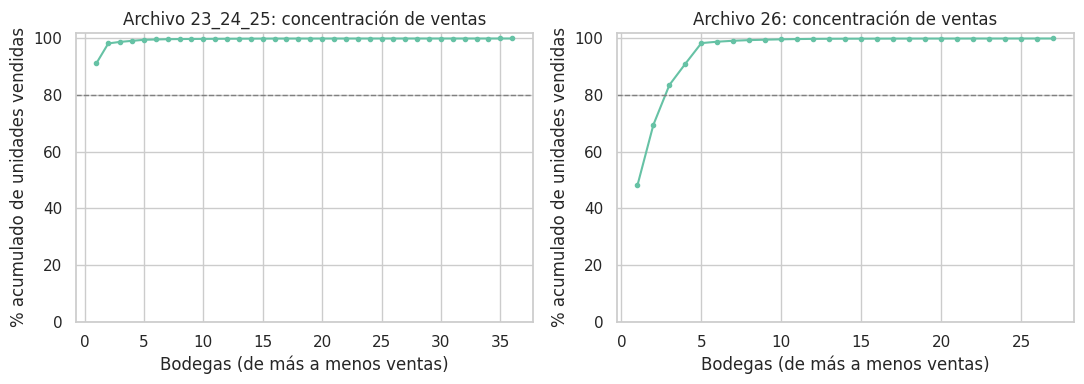

In [190]:

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, arch in zip(ax, ["23_24_25", "26"]):
    p = perfil_bodegas(arch)
    p = p[p["ventas_u"] > 0]                                   # solo bodegas que venden
    acum = 100 * p["ventas_u"].cumsum() / p["ventas_u"].sum()  # % acumulado de ventas
    a.plot(range(1, len(p) + 1), acum.values, marker="o", ms=3)
    a.axhline(80, ls="--", lw=1, color="gray")                 # referencia del 80 %
    a.set_title(f"Archivo {arch}: concentración de ventas")
    a.set_xlabel("Bodegas (de más a menos ventas)")
    a.set_ylabel("% acumulado de unidades vendidas")
    a.set_ylim(0, 102)
plt.tight_layout()
plt.show()

#### 6 C — Stock al cierre de cada archivo, por bodega
Último saldo de cada par bodega-producto en cada archivo: dónde queda el inventario, dónde quedan
saldos negativos que nunca se corrigieron y cómo cierran las bodegas de dropshipping.

In [191]:
# 6 C — Saldo al cierre de cada archivo, por bodega (último saldo de cada par bodega-producto)
TOL = 1e-6
llave = ["archivo", "bodega", "producto"]

# 1) Última fila de cada par bodega-producto = su saldo al cierre del archivo
ult = (df[merc].sort_values(llave + ["fecha", "orden_original"], kind="mergesort")
               .groupby(llave).tail(1))

# 2) Resumen por bodega
stock = ult.groupby(["archivo", "bodega"]).agg(
            pares=("producto", "size"),
            con_stock=("saldo_cant", lambda s: (s > TOL).sum()),
            negativos=("saldo_cant", lambda s: (s < -TOL).sum()),
            unidades=("saldo_cant", lambda s: s[s > 0].sum()))

for arch in ["23_24_25", "26"]:
    s = stock.loc[arch].sort_values("unidades", ascending=False)
    print(f"\n=== Saldo al cierre de {arch}: bodegas con stock: {(s['con_stock'] > 0).sum()} de {len(s)} | "
          f"pares con saldo negativo: {s['negativos'].sum()}")
    print(s.head(10).to_string())
    neg = s[s["negativos"] > 0].sort_values("negativos", ascending=False)
    print(f"\n   Bodegas con pares en negativo ({len(neg)}):")
    print(neg[["pares", "negativos"]].head(10).to_string())

# 3) Complemento: ¿cómo cierran las bodegas de dropshipping? (evidencia del S15)
print("\n=== Bodegas de dropshipping al cierre:")
print(stock[stock.index.get_level_values("bodega").str.contains("dropshipping")].to_string())


=== Saldo al cierre de 23_24_25: bodegas con stock: 21 de 95 | pares con saldo negativo: 4
                      pares  con_stock  negativos  unidades
bodega                                                     
principal              7836       1130          3   15770.0
construequipo_franco     44         17          0     236.0
pedrollo                  4          1          0      69.0
norte-128                65         23          1      53.0
casa_james              114          1          0      45.0
equipamex                53         16          0      27.0
inconformes             145         12          0      15.0
metalworks               42          1          0      15.0
mercado_full             49          2          0      14.0
maqimport                15          5          0      11.0

   Bodegas con pares en negativo (2):
           pares  negativos
bodega                     
principal   7836          3
norte-128     65          1

=== Saldo al cierre de 26: bodegas c

**Lectura 6 C — Stock al cierre:**
- **El inventario al cierre es confiable:** solo 4 pares (dic-2025) y 2 pares (sep-2026) cierran con
  saldo negativo; los negativos del 4.3 se corrigen con el tiempo. Están en las principales y en
  norte-128.
- **Dropshipping cierra sin stock:** de 1.629 productos que pasaron por bodegas de dropshipping
  (1.186 en 2023–2025 y 443 en 2026), solo 1 unidad queda en stock al cierre. Compra por pedido y
  despacha de inmediato: un saldo en 0 es su operación normal, no un quiebre (S15).
- **El stock se concentra en las principales:** al cierre de 2025, principal guarda 15.770 unidades
  en 1.130 de sus 7.836 productos (14 %); al cierre de sep-2026, las cuatro principales guardan
  12.138 unidades en 1.667 de 3.726 pares (45 %). La diferencia se explica porque la base 2026 solo
  incluye productos activos (S6).
- Solo 21 de 95 bodegas (2023–2025) y 24 de 37 (2026) cierran con stock.
- **Para el bloque E:** los productos con stock al cierre que no se venden hace meses son el
  inventario inmovilizado (E8).

#### 6 D — Ventas de 2026 por ciudad
En 2026 las bodegas llevan un prefijo de ciudad (baq_, bgt_, ctg_, nte_). Se agrupan las ventas
según ese prefijo para ver cómo se reparte la demanda entre ciudades.

In [192]:
# 6 D — 2026: ventas por ciudad (según el prefijo de la bodega)
CIUDADES = {"baq": "Barranquilla", "bgt": "Bogotá", "ctg": "Cartagena", "nte": "Norte"}

m26 = df[merc & df["archivo"].eq("26")]
m26 = m26.assign(
    u_venta=m26["sal_cant"].where(m26["tipo_mov"].eq("venta"), 0),          # unidades vendidas
    ciudad=m26["bodega"].str.split(r"[_-]", n=1, regex=True).str[0]         # prefijo antes de _ o -
                        .map(CIUDADES).fillna("otro"))

res = m26.groupby("ciudad").agg(bodegas=("bodega", "nunique"), productos=("producto", "nunique"),
                                ventas_u=("u_venta", "sum"))
res["%_ventas"] = (100 * res["ventas_u"] / res["ventas_u"].sum()).round(1)
print(res.sort_values("ventas_u", ascending=False).to_string())

# Bodegas sin prefijo de ciudad reconocido: revisar si alguna debería asignarse a una ciudad
otras = m26.loc[m26["ciudad"].eq("otro")].groupby("bodega")["u_venta"].sum().sort_values(ascending=False)
print(f"\nBodegas clasificadas como 'otro' ({len(otras)}):")
print(otras.to_string())

              bodegas  productos  ventas_u  %_ventas
ciudad                                              
Barranquilla       15       1380   26627.0      56.2
Cartagena           4        857   10233.0      21.6
Bogotá             11       1044    6697.0      14.1
Norte               5        720    3795.0       8.0
otro                2         15      18.0       0.0

Bodegas clasificadas como 'otro' (2):
bodega
miramar_principal     17.0
prestamos_bgta_nte     1.0


**Lectura 6 D — Ventas de 2026 por ciudad:** Barranquilla concentra el 56,2 % de las unidades
vendidas (15 bodegas, 1.380 productos), seguida de Cartagena (21,6 %), Bogotá (14,1 %) y Norte (8,0 %).
Dos bodegas sin prefijo de ciudad suman solo 18 unidades. Muchos productos se venden en varias
ciudades (la suma de productos por ciudad, 4.001, supera los 2.474 productos de 2026).
- La ciudad solo existe desde 2026 (9 meses); antes, la venta se registraba en una bodega única.
  Por eso el pronóstico se hace por producto; la ciudad podría usarse en el modelado para repartir
  el pronóstico según el peso reciente de cada ciudad.

#### 6 E — Bodegas de stock (S15): la bodega con más ventas de cada ciudad
 Regla del negocio: se compra y se factura en la bodega de cada ciudad (FC → FV, empresa 14-oct)

In [193]:

BODEGAS_STOCK = {}
for arch in ["23_24_25", "26"]:
    p = perfil_bodegas(arch)
    p = p[p["ventas_u"] > 0].copy()
    total = p["ventas_u"].sum()
    if arch == "26":
        p["ciudad"] = (p.index.str.split(r"[_-]", n=1, regex=True).str[0]
                         .map(CIUDADES).fillna("otro"))
        con_ciudad = p[p["ciudad"].ne("otro")]
        elegidas = con_ciudad.groupby("ciudad")["ventas_u"].idxmax()        # 1 por ciudad
        peso_en_ciudad = (con_ciudad.loc[elegidas.values, "ventas_u"].values
                          / con_ciudad.groupby("ciudad")["ventas_u"].sum().loc[elegidas.index].values)
        print(f"26: % de las ventas de su ciudad que hace la bodega elegida: "
              f"{', '.join(f'{c} {w:.1%}' for c, w in zip(elegidas.index, peso_en_ciudad))}")
    else:
        elegidas = pd.Series([p["ventas_u"].idxmax()])
    BODEGAS_STOCK[arch] = list(elegidas)
    resto = p.drop(index=BODEGAS_STOCK[arch])["ventas_u"]
    print(f"{arch}: {len(BODEGAS_STOCK[arch])} bodegas de stock | "
          f"{p.loc[BODEGAS_STOCK[arch], 'ventas_u'].sum() / total:.1%} de las ventas | "
          f"la mayor bodega NO elegida hace el {resto.max() / total:.1%}")

df["bodega_stock"] = [b in BODEGAS_STOCK[a] for a, b in zip(df["archivo"], df["bodega"])]

# 💾 PUNTO DE CONTROL — fin del Bloque C: df_limpio es la entrada del Bloque D
COLS_D = ["es_mercancia", "tipo_mov", "mov_fisico", "sal_cant_fisica", "dup_exacto",
          "mes_ajuste", "saldo_negativo", "costo_invalido", "orden_original", "bodega_stock"]
faltan = [c for c in COLS_D if c not in df.columns]
assert not faltan, f"Faltan columnas para el Bloque D: {faltan}"
assert len(df) == 162329, "Cambió el número de filas"
assert len(BODEGAS_STOCK["23_24_25"]) == 1 and len(BODEGAS_STOCK["26"]) == 4, \
    "No coincide con S15 (1 bodega en 23_24_25, 4 en 26): revisar"
df_limpio = df.copy()
print("df_limpio listo para el Bloque D ✔")

23_24_25: 1 bodegas de stock | 91.3% de las ventas | la mayor bodega NO elegida hace el 7.0%
26: % de las ventas de su ciudad que hace la bodega elegida: Barranquilla 85.6%, Bogotá 99.3%, Cartagena 99.2%, Norte 93.8%
26: 4 bodegas de stock | 91.1% de las ventas | la mayor bodega NO elegida hace el 7.3%
df_limpio listo para el Bloque D ✔


In [194]:
# 6 E (control) — ¿Qué es la mayor bodega NO elegida? ¿Guarda stock?
for arch in ["23_24_25", "26"]:
    p = perfil_bodegas(arch)
    p = p[p["ventas_u"] > 0]
    b = p.drop(index=BODEGAS_STOCK[arch])["ventas_u"].idxmax()
    st = stock.loc[arch]
    print(f"\n{arch}:")
    print(f"   es dropshipping: {'dropshipping' in b} | ciudad (prefijo): {b.split('_')[0].split('-')[0][:3]}")
    print(f"   % de las ventas: {100 * p.loc[b, 'ventas_u'] / p['ventas_u'].sum():.1f} | "
          f"% abastecimiento: {p.loc[b, '%_abastecimiento']} | % venta: {p.loc[b, '%_venta']}")
    print(f"   al cierre: pares {st.loc[b, 'pares']} | con stock {st.loc[b, 'con_stock']} | "
          f"unidades {st.loc[b, 'unidades']:.0f} "
          f"({100 * st.loc[b, 'unidades'] / st['unidades'].sum():.1f} % del stock total)")
    elegidas = st.loc[st.index.isin(BODEGAS_STOCK[arch]), "unidades"].sum()
    print(f"   bodegas de stock elegidas: {100 * elegidas / st['unidades'].sum():.1f} % del stock total al cierre")


23_24_25:
   es dropshipping: True | ciudad (prefijo): dro
   % de las ventas: 7.0 | % abastecimiento: 36.8 | % venta: 29.8
   al cierre: pares 1186 | con stock 0 | unidades 0 (0.0 % del stock total)
   bodegas de stock elegidas: 96.8 % del stock total al cierre

26:
   es dropshipping: True | ciudad (prefijo): baq
   % de las ventas: 7.3 | % abastecimiento: 41.1 | % venta: 33.5
   al cierre: pares 386 | con stock 1 | unidades 1 (0.0 % del stock total)
   bodegas de stock elegidas: 95.4 % del stock total al cierre


**Lectura 6 E — Bodegas de stock (S15):** se elige, en cada ciudad, la bodega con más ventas
(flujo FC → FV por ciudad, confirmado por la empresa). Resultado: 1 bodega en 2023–2025 (91,3 %
de las ventas) y 4 en 2026 (91,1 %); cada una hace entre el 85,6 % y el 99,3 % de las ventas de su
ciudad. La mayor bodega no elegida en cada archivo es de dropshipping (7,0 % y 7,3 % de las ventas)
y cierra sin stock (0 y 1 unidad). Las bodegas elegidas guardan el 96,8 % y el 95,4 % del inventario
al cierre. Los quiebres se evalúan solo en ellas; la demanda sigue sumando todas las bodegas.

#### **Conclusión 6 — Bodegas**
- **La venta está muy concentrada:** en 2023–2025 una sola bodega (principal) hizo el 91,3 % de las
  ventas; en 2026, las cuatro "principal" por ciudad suman el 91,0 %. La estructura del negocio se
  mantiene; cambió el registro de bodegas.
- **La mayoría de las bodegas no vende:** 59 de 95 (2023–2025) y 10 de 37 (2026). Son bodegas de paso
  (préstamos, consignación, proveedores).
- **Dropshipping compra por pedido y cierra sin stock** (1 unidad de 1.629 productos).
- **El inventario al cierre es confiable** (6 pares en negativo) y se concentra en las principales.
- **2026 por ciudad:** Barranquilla 56,2 %, Cartagena 21,6 %, Bogotá 14,1 %, Norte 8,0 %.
- **Decisiones:** la demanda se pronostica por producto, sumando bodegas; los quiebres se evalúan
  solo en las bodegas de stock (S15).

## Bloque D — Series de tiempo

- 7. Construcción de series (7.0 a 7.5)
- 8. Reposición y horizonte (8.1 y 8.2)

### 7. Construcción de series

**Lectura 7.0 — Días de facturación:** se factura de lunes a sábado; el sábado aporta el 11,8 % de
las unidades y el domingo es casi nulo (23 filas). Por eso la semana se define de lunes a domingo:
una semana de lunes a viernes perdería el 11,8 % de la demanda. El lunes vende menos (14,3 % frente a
≈ 18–19 % de martes a viernes); hipótesis: los festivos trasladados al lunes. Se revisará en el
Bloque E como posible efecto de las semanas con festivo.

In [195]:
# 7.0 — ¿En qué días de la semana se factura?
fv_m = df_limpio[df_limpio["es_mercancia"] & df_limpio["tipo_mov"].eq("venta")]
dias = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
r = (fv_m.groupby(fv_m["fecha"].dt.dayofweek)["sal_cant"].agg(filas="size", unidades="sum")
         .reindex(range(7), fill_value=0))
r.index = dias
r["% unidades"] = (100 * r["unidades"] / r["unidades"].sum()).round(1)
print(r.to_string())

           filas  unidades  % unidades
lunes       9515   34537.5        14.3
martes     12055   46782.0        19.3
miércoles  12471   45171.0        18.7
jueves     11842   42839.0        17.7
viernes    12237   44171.0        18.2
sábado      7190   28618.0        11.8
domingo       23      32.0         0.0


#### 7.1 — Rejilla semanal de demanda por producto (D1)
Una fila por producto y semana (lunes a domingo), desde el primer movimiento del producto hasta la
última semana de datos. Las semanas sin venta valen 0. Solo mercancía con al menos una fv (S14).
La demanda suma todas las bodegas (S4, NIVEL_DEMANDA = "producto").

In [196]:
# 7.1 — Rejilla semanal de demanda por producto (D1)
m = df_limpio[df_limpio["es_mercancia"] & ~df_limpio["dup_exacto"]].copy()
m["semana"]  = m["fecha"].dt.to_period("W-SUN").dt.start_time          # lunes de cada semana
m["u_venta"] = m["sal_cant"].where(m["tipo_mov"].eq("venta"), 0)
m["u_devol"] = m["ent_cant"].where(m["tipo_mov"].eq("devolucion_cliente"), 0)

In [197]:
# 1) Productos con al menos una venta (S14: los que solo salen por sa quedan fuera)
prod_venta = m.loc[m["u_venta"] > 0, "producto"].unique()
print(f"1) Productos de mercancía: {m['producto'].nunique()} | con al menos una fv: {len(prod_venta)} | "
      f"fuera (sin fv): {m['producto'].nunique() - len(prod_venta)}")
m = m[m["producto"].isin(prod_venta)]

1) Productos de mercancía: 8780 | con al menos una fv: 4765 | fuera (sin fv): 4015


In [198]:
# 2) Rango de cada producto: desde su primer movimiento hasta la última semana de datos
inicio     = m.groupby("producto")["semana"].min()
fin_global = m["semana"].max()
idx = pd.MultiIndex.from_tuples(
    [(p, s) for p, ini in inicio.items() for s in pd.date_range(ini, fin_global, freq="W-MON")],
    names=["producto", "semana"])

sem  = m.groupby(["producto", "semana"])[["u_venta", "u_devol"]].sum()
grid = sem.reindex(idx, fill_value=0).reset_index()
grid["u_neta"] = grid["u_venta"] - grid["u_devol"]

In [199]:
# 3) Semana final incompleta
ultimo_dia = df_limpio["fecha"].max()
dias_ult   = (ultimo_dia - fin_global).days + 1
grid["semana_parcial"] = grid["semana"].eq(fin_global) & (dias_ult < 7)
print(f"2) Semanas: {grid['semana'].min():%Y-%m-%d} a {fin_global:%Y-%m-%d} "
      f"({grid['semana'].nunique()} semanas) | la última tiene {dias_ult} de 7 días")

2) Semanas: 2022-12-26 a 2026-09-28 (197 semanas) | la última tiene 2 de 7 días


In [200]:
# 4) Validaciones
assert not grid.duplicated(["producto", "semana"]).any(), "Hay producto-semana repetidos"
esperado = ((fin_global - inicio).dt.days // 7 + 1)
assert grid.groupby("producto").size().sort_index().equals(esperado.sort_index()), "Faltan semanas en la rejilla"
total_fv = df_limpio.loc[df_limpio["es_mercancia"] & df_limpio["tipo_mov"].eq("venta"), "sal_cant"].sum()
assert abs(grid["u_venta"].sum() - total_fv) < 1e-6, "La rejilla no conserva las unidades vendidas"
print("3) Sin repetidos, semanas completas y unidades vendidas conservadas ✔")

3) Sin repetidos, semanas completas y unidades vendidas conservadas ✔


In [201]:
# 5) Resumen
print(f"4) Filas: {len(grid):,} | productos: {grid['producto'].nunique()} | "
      f"% de semanas con venta 0: {100 * grid['u_venta'].eq(0).mean():.1f} %")
sem_por_prod = grid.groupby("producto").size()
print("   Semanas de historia por producto:")
print(sem_por_prod.describe(percentiles=[.1, .25, .5, .75]).round(0).to_string())

4) Filas: 674,808 | productos: 4765 | % de semanas con venta 0: 93.5 %
   Semanas de historia por producto:
count    4765.0
mean      142.0
std        64.0
min         1.0
10%        37.0
25%        86.0
50%       173.0
75%       197.0
max       197.0


In [202]:
# 7.1 (ajuste) — La primera semana también es parcial (el 1-ene-2023 fue domingo)
primer_dia = df_limpio["fecha"].min()
ini_global = grid["semana"].min()
dias_prim  = 7 - (primer_dia - ini_global).days
grid["semana_parcial"] = grid["semana_parcial"] | (grid["semana"].eq(ini_global) & (dias_prim < 7))
print(f"Primera semana: {ini_global:%Y-%m-%d}, {dias_prim} de 7 días | "
      f"semanas parciales marcadas: {grid.loc[grid['semana_parcial'], 'semana'].dt.strftime('%Y-%m-%d').unique().tolist()}")

Primera semana: 2022-12-26, 2 de 7 días | semanas parciales marcadas: ['2026-09-28', '2022-12-26']


**Lectura 7.1 — Rejilla semanal:** 4.765 productos con al menos una fv, 197 semanas (26-dic-2022 a
28-sep-2026), 674.808 filas. La primera semana (2 de 7 días) y la última (2 de 7 días) se marcan como
parciales. El 93,5 % de las semanas-producto tiene venta 0: la demanda por producto y semana es muy
intermitente.

In [203]:
# 7.1 B — ¿Qué son los productos sin fv? ¿Cuántas semanas CON venta tiene cada producto?
mm = df_limpio[df_limpio["es_mercancia"]]

# 1) Productos sin fv: ¿qué movimientos tienen?
sin_fv = mm[~mm["producto"].isin(prod_venta)]
combo = sin_fv.groupby("producto")["tipo_mov"].agg(lambda s: " + ".join(sorted(set(s))))
print(f"1) Productos sin fv: {combo.size} — según los movimientos que tienen (top 8):")
print(combo.value_counts().head(8).to_string())

# 2) ¿Siguen en 2026 y con stock? (saldo al cierre = última fila de cada par bodega-producto)
ult = (mm.sort_values(["archivo", "bodega", "producto", "fecha", "orden_original"], kind="mergesort")
         .groupby(["archivo", "bodega", "producto"]).tail(1))
stock26 = ult[ult["archivo"].eq("26")].groupby("producto")["saldo_cant"].sum()
s_sin   = stock26.reindex(combo.index).fillna(0)
en26    = sin_fv.groupby("producto")["archivo"].agg(lambda s: "26" in set(s))
print(f"\n2) Productos sin fv que aparecen en 2026: {en26.sum()} | con stock > 0 al cierre 2026: {(s_sin > TOL).sum()}")
print(f"   Sus unidades en stock: {s_sin.clip(lower=0).sum():,.0f} de {stock26.clip(lower=0).sum():,.0f} "
      f"({100 * s_sin.clip(lower=0).sum() / stock26.clip(lower=0).sum():.1f} % del stock al cierre 2026)")

# 3) Productos con venta: semanas con venta y peso en la demanda
con_venta = grid[grid["u_venta"] > 0].groupby("producto").size()
u_total   = grid.groupby("producto")["u_venta"].sum()
tramo = pd.cut(con_venta, [0, 1, 4, 12, 26, 52, 1000],
               labels=["1", "2-4", "5-12", "13-26", "27-52", "> 52"])
t = pd.DataFrame({"productos": con_venta.groupby(tramo, observed=False).size(),
                  "% unidades vendidas": (100 * u_total.groupby(tramo, observed=False).sum() / u_total.sum()).round(1)})
print("\n3) Productos según cuántas semanas tuvieron venta:")
print(t.to_string())

# 4) Historia desde la PRIMERA VENTA (no desde el primer movimiento)
prim_venta = grid[grid["u_venta"] > 0].groupby("producto")["semana"].min()
hist_venta = (fin_global - prim_venta).dt.days // 7 + 1
print(f"\n4) Semanas desde la primera venta: mediana {hist_venta.median():.0f} | "
      f"productos con ≤ 52 semanas: {(hist_venta <= 52).sum()} | con ≤ 13: {(hist_venta <= 13).sum()}")

1) Productos sin fv: 4015 — según los movimientos que tienen (top 8):
tipo_mov
apertura                                              3572
apertura + interno                                      95
abastecimiento + interno                                84
abastecimiento + apertura + interno                     76
abastecimiento                                          55
abastecimiento + ajuste_valor + apertura + interno      50
abastecimiento + apertura                               48
abastecimiento + ajuste_valor + interno                 17

2) Productos sin fv que aparecen en 2026: 192 | con stock > 0 al cierre 2026: 141
   Sus unidades en stock: 426 de 12,728 (3.3 % del stock al cierre 2026)

3) Productos según cuántas semanas tuvieron venta:
       productos  % unidades vendidas
1           2099                  3.6
2-4         1216                  4.0
5-12         658                  5.2
13-26        361                  5.0
27-52        225                  9.9
> 52         

**Lectura 7.1 B — Productos sin venta y concentración de la demanda:**
- De 8.780 productos de mercancía, 4.015 nunca se vendieron; 3.572 de ellos solo aparecen en un saldo
  inicial, sin ningún movimiento posterior, y casi todos dejaron de existir en la base de 2026. Quedan
  fuera del pronóstico. En 2026 siguen 141 con stock (426 unidades, 3,3 % del inventario): son
  inventario inmovilizado.
- La demanda está muy concentrada: 206 productos (4 %) que venden en más de 52 semanas hacen el
  72,3 % de las unidades; 2.099 productos (44 %) vendieron en una sola semana y suman el 3,6 %.
- 867 productos tienen ≤ 52 semanas desde su primera venta (208 con ≤ 13): historia limitada (E5).

In [204]:
# 7.1 C — ¿La demanda son conteos enteros? (requisito de la verosimilitud negative-binomial)
fvm = df_limpio[df_limpio["es_mercancia"] & df_limpio["tipo_mov"].eq("venta")]
dec = (fvm["sal_cant"] % 1).abs().gt(1e-9)
print(f"1) Filas fv con cantidad decimal: {dec.sum()} de {len(fvm)} ({100 * dec.mean():.2f} %) | "
      f"unidades: {100 * fvm.loc[dec, 'sal_cant'].sum() / fvm['sal_cant'].sum():.2f} % del total")
print(f"   Productos con alguna venta decimal: {fvm.loc[dec, 'producto'].nunique()} de {fvm['producto'].nunique()}")
print("   Parte decimal más frecuente:", (fvm.loc[dec, 'sal_cant'] % 1).round(3).value_counts().head(5).to_dict())

no_ent = (grid["u_venta"] % 1).abs().gt(1e-9)
print(f"2) Semanas-producto con total no entero: {no_ent.sum()} de {grid['u_venta'].gt(0).sum()} con venta")

1) Filas fv con cantidad decimal: 1 de 65333 (0.00 %) | unidades: 0.00 % del total
   Productos con alguna venta decimal: 1 de 4765
   Parte decimal más frecuente: {0.5: 1}
2) Semanas-producto con total no entero: 1 de 43774 con venta


**Lectura 7.1 C — Demanda en unidades enteras:** de 65.333 filas de fv de mercancía, solo 1 tiene
cantidad decimal (0,5), en 1 producto. La demanda es un conteo entero, compatible con la verosimilitud
negative-binomial de DeepAR. Ese único valor se redondea hacia arriba en la serie que se entrega al
modelo; la rejilla original no se modifica.

#### 7.2 — Stock semanal en las bodegas de stock (D2)
Para cada producto y semana: saldo al cierre y saldo mínimo, solo en las bodegas de stock (S15).
Se mide con el saldo al cierre de cada día (S10: los negativos dentro del día no cuentan).
El saldo se lleva por bodega-producto (4.5) y luego se suma por producto (S4). Un saldo negativo
cuenta como 0 disponible. Cada semana pertenece al archivo que contiene su domingo: la semana
del 29-dic-2025 se mide con 2026.

In [205]:
# 7.2 — Stock semanal por producto en las bodegas de stock (D2) — usa grid y fin_global de la 7.1
FIN_23 = pd.Timestamp("2025-12-31")
llave  = ["archivo", "bodega", "producto"]
s = (df_limpio[df_limpio["es_mercancia"] & df_limpio["bodega_stock"]]
       .sort_values(llave + ["fecha", "orden_original"], kind="mergesort"))

# 1) Saldo al cierre de cada día por bodega-producto
dia = s.groupby(llave + ["fecha"], sort=False)["saldo_cant"].last().reset_index()
dia["semana"] = dia["fecha"].dt.to_period("W-SUN").dt.start_time
arch_sem = np.where(dia["semana"] + pd.Timedelta(days=6) > FIN_23, "26", "23_24_25")
dia = dia[dia["archivo"].eq(arch_sem)]                       # cada semana, en el archivo de su domingo

sem = (dia.groupby(llave + ["semana"])["saldo_cant"]
          .agg(cierre="last", min_dia="min").reset_index())

# 2) Rejilla semanal por bodega-producto: desde su primer movimiento hasta el fin de su archivo
ult_sem = {"23_24_25": FIN_23.to_period("W-SUN").start_time - pd.Timedelta(days=7),   # 22-dic-2025
           "26": fin_global}
ini = sem.groupby(llave)["semana"].min()
idx = pd.MultiIndex.from_tuples(
    [(a, b, p, w) for (a, b, p), w0 in ini.items() for w in pd.date_range(w0, ult_sem[a], freq="W-MON")],
    names=llave + ["semana"])
st = sem.set_index(llave + ["semana"]).reindex(idx).reset_index()
st["cierre"] = st.groupby(llave)["cierre"].ffill()           # semana sin movimiento: sigue el saldo anterior
prev = st.groupby(llave)["cierre"].shift()
st["minimo"] = pd.concat([st["min_dia"], prev], axis=1).min(axis=1)   # incluye el saldo con que abrió la semana
assert not st.duplicated(llave + ["semana"]).any(), "Hay bodega-producto-semana repetidos"

# 3) Suma por producto (negativo = 0 disponible) y cuántas bodegas están en 0
st = st.assign(c_disp=st["cierre"].clip(lower=0), m_disp=st["minimo"].clip(lower=0),
               c0=st["cierre"].le(TOL), m0=st["minimo"].le(TOL))
prod_sem = (st.groupby(["producto", "semana"])
              .agg(stock_cierre=("c_disp", "sum"), stock_min=("m_disp", "sum"),
                   bodegas=("bodega", "size"), bod_cierre_0=("c0", "sum"), bod_min_0=("m0", "sum"))
              .reset_index())
serie = grid.merge(prod_sem, on=["producto", "semana"], how="left")

# 4) Validación: el cierre de 2026 debe coincidir con el stock del 6 C
esperado = stock.loc["26"].loc[BODEGAS_STOCK["26"], "unidades"].sum()
obtenido = st.loc[st["archivo"].eq("26") & st["semana"].eq(fin_global), "c_disp"].sum()
assert abs(esperado - obtenido) < 1e-6, f"Stock al cierre 2026: {obtenido} ≠ {esperado} del 6 C"
assert len(serie) == len(grid), "La unión cambió el número de filas de la rejilla"
print(f"1) Validación: stock al cierre 2026 = {obtenido:,.0f} unidades, igual que el 6 C ✔")

# 5) Resumen
con_info = serie["stock_cierre"].notna()
sin_bod = serie.groupby("producto")["stock_cierre"].apply(lambda x: x.isna().all())
print(f"2) Bodega-producto-semana: {len(st):,} | semanas-producto con dato de stock: {con_info.mean():.1%}")
print(f"   Productos con venta SIN ningún registro en bodegas de stock: {sin_bod.sum()} de {len(sin_bod)}")
x = serie[con_info]
print(f"3) Semanas-producto (con dato) con stock al cierre = 0: {x['stock_cierre'].le(TOL).mean():.1%} | "
      f"con stock mínimo = 0: {x['stock_min'].le(TOL).mean():.1%}")

seg_s = pd.cut(con_venta, [0, 12, 52, 1000], labels=["≤ 12 sem", "13-52 sem", "> 52 sem"])
x = x.assign(seg=x["producto"].map(seg_s))
print("\n4) % de semanas con stock al cierre = 0, por segmento:")
print((100 * x.groupby("seg", observed=False)["stock_cierre"].apply(lambda v: v.le(TOL).mean())).round(1).to_string())

v26 = x[x["semana"] > FIN_23]
print(f"\n5) 2026: semanas-producto con stock total > 0 pero alguna bodega en 0: "
      f"{(v26['stock_cierre'].gt(TOL) & v26['bod_cierre_0'].gt(0)).sum():,} de {len(v26):,}")

1) Validación: stock al cierre 2026 = 12,138 unidades, igual que el 6 C ✔
2) Bodega-producto-semana: 1,183,830 | semanas-producto con dato de stock: 79.3%
   Productos con venta SIN ningún registro en bodegas de stock: 350 de 4765
3) Semanas-producto (con dato) con stock al cierre = 0: 62.7% | con stock mínimo = 0: 63.6%

4) % de semanas con stock al cierre = 0, por segmento:
seg
≤ 12 sem     76.0
13-52 sem    29.7
> 52 sem     12.1

5) 2026: semanas-producto con stock total > 0 pero alguna bodega en 0: 10,110 de 65,419


**Lectura 7.2 — Stock semanal:** se reconstruyó el saldo semanal de 1.183.830 bodega-producto-semana
en las bodegas de stock; el cierre de 2026 coincide con el 6 C (12.138 unidades). El 62,7 % de las
semanas-producto con dato cierra con stock 0, y con el mínimo semanal la cifra casi no cambia (63,6 %):
el quiebre se define con el cierre. El stock en 0 depende del segmento: 12,1 % de las semanas en los
productos regulares (> 52 semanas con venta), 29,7 % en los intermedios y 76,0 % en los esporádicos.
350 productos con venta nunca pasan por una bodega de stock. En 2026, el 15,5 % de las semanas con
stock total tiene alguna ciudad en 0.

In [206]:
# 7.2 B — ¿Qué productos se manejan bajo pedido? (S24) — usa serie de la 7.2
s2 = serie.sort_values(["producto", "semana"]).copy()
s2["abre"] = s2.groupby("producto")["stock_cierre"].shift()        # stock con que abre la semana
v = s2[s2["u_venta"].gt(0)].assign(a0=lambda t: t["abre"].le(TOL), an=lambda t: t["abre"].isna())

pedido = v.groupby("producto").agg(sem_venta=("u_venta", "size"), abre_0=("a0", "sum"), sin_dato=("an", "sum"))
pedido["con_dato"]   = pedido["sem_venta"] - pedido["sin_dato"]
pedido["pct_abre_0"] = pedido["abre_0"] / pedido["con_dato"].where(pedido["con_dato"] > 0)
pedido["unidades"]   = u_total.reindex(pedido.index)

# 1) Distribución: % de semanas con venta que empezaron sin stock
tramo = pd.cut(pedido["pct_abre_0"], [-0.01, 0.1, 0.25, 0.5, 0.75, 1.0],
               labels=["0-10 %", "10-25 %", "25-50 %", "50-75 %", "75-100 %"])
t = pd.DataFrame({"productos": pedido.groupby(tramo, observed=False).size(),
                  "% unidades": (100 * pedido.groupby(tramo, observed=False)["unidades"].sum() / u_total.sum()).round(1)})
print("1) Productos según el % de sus semanas con venta que empezaron con stock 0:")
print(t.to_string())
sd = pedido["pct_abre_0"].isna()
print(f"   Sin dato de stock en ninguna semana con venta: {sd.sum()} productos "
      f"({100 * pedido.loc[sd, 'unidades'].sum() / u_total.sum():.1f} % de las unidades)")

# 2) Cruce con los segmentos de venta
print("\n2) Mediana del % de semanas con venta que empezaron sin stock, por segmento:")
print((100 * pedido["pct_abre_0"].groupby(seg_s.reindex(pedido.index), observed=False).median()).round(1).to_string())

# 3) La misma distribución, solo con los productos que se pueden clasificar (≥ 4 semanas con dato, S24)
ok4 = pedido["con_dato"].ge(4)
t4 = pd.DataFrame({"productos": pedido[ok4].groupby(tramo[ok4], observed=False).size(),
                   "% unidades": (100 * pedido[ok4].groupby(tramo[ok4], observed=False)["unidades"].sum()
                                  / u_total.sum()).round(1)})
print(f"\n3) Solo productos con ≥ 4 semanas con dato ({ok4.sum()}):")
print(t4.to_string())

1) Productos según el % de sus semanas con venta que empezaron con stock 0:
            productos  % unidades
pct_abre_0                       
0-10 %           1793        84.7
10-25 %           242         3.3
25-50 %           357         2.8
50-75 %           156         1.8
75-100 %          921         4.8
   Sin dato de stock en ninguna semana con venta: 1296 productos (2.6 % de las unidades)

2) Mediana del % de semanas con venta que empezaron sin stock, por segmento:
≤ 12 sem     25.0
13-52 sem     5.9
> 52 sem      0.9

3) Solo productos con ≥ 4 semanas con dato (1547):
            productos  % unidades
pct_abre_0                       
0-10 %            850        83.1
10-25 %           242         3.3
25-50 %           160         2.2
50-75 %           108         1.5
75-100 %          187         2.8


**Lectura 7.2 B — Productos bajo pedido (S24):** para cada producto se midió qué parte de sus semanas
con venta empezó con stock 0. Con todos los productos, la distribución parece tener dos grupos (1.793 en
0–10 % y 921 en 75–100 %), pero buena parte del segundo son productos con 1 a 3 semanas de venta, cuyo
porcentaje no es confiable. Con los 1.547 productos que tienen al menos 4 semanas con dato, 850 (83,1 % de
las unidades) casi nunca venden sin stock y solo 187 (2,8 %) casi siempre lo hacen. La demanda está, por
tanto, en productos que se manejan con stock; el grupo bajo pedido existe, pero es pequeño. La mediana es
de 0,9 % en los productos regulares y de 25 % en los esporádicos. Con un umbral de 50 % y un mínimo de 4
semanas con dato, 1.215 productos (88,2 % de las unidades) se manejan con stock, 332 (4,5 %) bajo pedido y
3.218 (7,3 %) no se pueden clasificar. Cambiar el umbral a 25 % o 75 % solo mueve el 3,7 % de las unidades.

#### 7.3 — Quiebres de stock (D3)
Solo en los productos con stock (S24) y entre su primera y su última venta (los ceros posteriores son
inactividad y se tratan en la D5). Una semana es **quiebre** si no hubo venta y el stock total al cierre
fue 0 (7.2: cierre y mínimo dan casi lo mismo; S4: stock total, no por ciudad). Los quiebres pasan a
`NaN` en la serie para DeepAR. La regla se valida con sensibilidad (mínimo, por ciudad), con la
compra que debería cerrar cada quiebre y con los meses de ajuste (S21).

In [207]:
# 7.3 — Quiebres de stock (D3) — usa serie (7.2), pedido y seg_s (7.2 B), u_total (7.1 B), meses_ajuste (5.2 D)
UMBRAL_PEDIDO = 0.5     # S24: ≥ 50 % de las semanas con venta empezaron sin stock → bajo pedido
MIN_SEM_DATO  = 4       # S24: con menos semanas con dato no se puede clasificar
LARGO_MAX     = 13      # S26: más de 13 semanas (≈ 4 ciclos de reposición) = periodo sin surtido

manejo = pd.Series("con_stock", index=pedido.index)
manejo[pedido["pct_abre_0"].ge(UMBRAL_PEDIDO)] = "bajo_pedido"
manejo[pedido["con_dato"].lt(MIN_SEM_DATO)] = "sin_dato"

q = serie.sort_values(["producto", "semana"]).copy()
q["manejo"] = q["producto"].map(manejo)
ventas = q.loc[q["u_venta"].gt(0)].groupby("producto")["semana"].agg(prim="min", ult="max")
q = q.join(ventas, on="producto")
base = q["manejo"].eq("con_stock") & q["semana"].between(q["prim"], q["ult"])   # semanas evaluables

# Regla principal, censura parcial (S25) y episodios
q["quiebre"] = base & q["u_venta"].eq(0) & q["stock_cierre"].le(TOL)
q["censura"] = base & q["u_venta"].gt(0) & q["stock_cierre"].le(TOL)     # vendió y cerró en 0: se deja observada
prev = q.groupby("producto")["quiebre"].shift().eq(True)
q["ep"] = (q["quiebre"] & ~prev).groupby(q["producto"]).cumsum()
q["largo_ep"]      = q.groupby(["producto", "ep"])["quiebre"].transform("sum").where(q["quiebre"])
q["sin_surtido"]   = q["quiebre"] & q["largo_ep"].gt(LARGO_MAX)
q["quiebre_corto"] = q["quiebre"] & ~q["sin_surtido"]
q["y_deepar"]      = q["u_venta"].where(~q["quiebre"])                     # demanda no observable → NaN

# 1) Productos por manejo
print("1) Productos según manejo (S24):")
print(pd.DataFrame({"productos": manejo.value_counts(),
                    "% unidades": (100 * u_total.groupby(manejo).sum() / u_total.sum()).round(1)}).to_string())

# 2) Quiebres cortos y periodos sin surtido
ev = base.sum()
print(f"\n2) Semanas evaluables: {ev:,} | quiebres cortos: {q['quiebre_corto'].sum():,} "
      f"({100 * q['quiebre_corto'].sum() / ev:.1f} %) | sin surtido (> {LARGO_MAX} sem): {q['sin_surtido'].sum():,} | "
      f"censura parcial: {q['censura'].sum():,}")
seg_q = q["producto"].map(seg_s)
print("   % de semanas evaluables en quiebre corto, por segmento:")
print((100 * q.loc[base, "quiebre_corto"].groupby(seg_q[base], observed=False).mean()).round(1).to_string())

# 3) Sensibilidad (decisiones a y c)
alt_min    = base & q["u_venta"].eq(0) & q["stock_min"].le(TOL)
alt_ciudad = base & q["u_venta"].eq(0) & q["bod_cierre_0"].gt(0)
print(f"\n3) Sensibilidad — regla principal: {q['quiebre'].sum():,} | con el mínimo: {alt_min.sum():,} | "
      f"con 'alguna bodega en 0': {alt_ciudad.sum():,}")

# 4) ¿Los quiebres terminan con una compra?
eps = q[q["quiebre"]].groupby(["producto", "ep"])["semana"].agg(fin="max", largo="size").reset_index()
mstk = df_limpio[df_limpio["es_mercancia"] & df_limpio["bodega_stock"] & df_limpio["ent_cant"].gt(0)
                 & df_limpio["doc"].isin(["fc", "remc"])]
cs = (mstk.assign(semana=mstk["fecha"].dt.to_period("W-SUN").dt.start_time)[["producto", "semana"]]
          .drop_duplicates())
mm = eps.merge(cs, on="producto", how="left")
mm["ok"] = mm["semana"].between(mm["fin"], mm["fin"] + pd.Timedelta(days=14))
resuelto = mm.groupby(["producto", "ep"])["ok"].any()
eps = eps.merge(resuelto.rename("resuelto").reset_index(), on=["producto", "ep"])
eps["tipo"] = np.where(eps["largo"].gt(LARGO_MAX), "sin surtido", "quiebre corto")
print(f"\n4) Episodios: {len(eps):,} — terminan con una compra (fc/remc) en ≤ 2 semanas:")
print(eps.groupby("tipo").agg(episodios=("largo", "size"), semanas=("largo", "sum"),
                              mediana_sem=("largo", "median"), con_compra=("resuelto", "mean")).round(2).to_string())

# 5) S21: ¿los quiebres cortos se concentran en los meses de ajuste?
aj = q["semana"].dt.to_period("M").isin(meses_ajuste)
print(f"\n5) S21 — semanas evaluables en meses de ajuste: {100 * aj[base].mean():.1f} % | "
      f"quiebres cortos en meses de ajuste: {100 * aj[q['quiebre_corto']].mean():.1f} %")

# 6) Serie para DeepAR
print(f"\n6) y_deepar: {q['y_deepar'].isna().sum():,} semanas en NaN ({100 * q['y_deepar'].isna().mean():.1f} % de la rejilla)")
serie_d3 = q

1) Productos según manejo (S24):
             productos  % unidades
bajo_pedido        332         4.5
con_stock         1215        88.2
sin_dato          3218         7.3

2) Semanas evaluables: 161,805 | quiebres cortos: 8,436 (5.2 %) | sin surtido (> 13 sem): 17,123 | censura parcial: 4,194
   % de semanas evaluables en quiebre corto, por segmento:
producto
≤ 12 sem     4.8
13-52 sem    6.5
> 52 sem     2.9

3) Sensibilidad — regla principal: 25,559 | con el mínimo: 27,714 | con 'alguna bodega en 0': 29,695

4) Episodios: 2,842 — terminan con una compra (fc/remc) en ≤ 2 semanas:
               episodios  semanas  mediana_sem  con_compra
tipo                                                      
quiebre corto       2326     8436          2.0        0.85
sin surtido          516    17123         24.0        0.81

5) S21 — semanas evaluables en meses de ajuste: 17.8 % | quiebres cortos en meses de ajuste: 19.1 %

6) y_deepar: 25,559 semanas en NaN (3.8 % de la rejilla)


**Lectura 7.3 — Quiebres de stock (E3):** en los 2.222 productos con stock (90,1 % de las unidades),
entre su primera y última venta, 34.141 de 185.677 semanas (18,4 %) son quiebres: venta 0 y stock total
al cierre 0. Se concentran en los productos de baja rotación (29,1 % de las semanas en los esporádicos
frente a 3,9 % en los regulares). La regla es robusta: con el mínimo semanal da 6,9 % más quiebres y con
"alguna bodega en 0" un 12,8 % más. El 82,7 % de los 3.130 episodios termina con una compra en ≤ 2
semanas, como se espera de un quiebre real. Los quiebres no se concentran en los meses de ajuste (19,5 %
frente a 17,8 % de las semanas), así que no son quiebres de papel (S21). Hay además 6.251 semanas con
censura parcial (vendió hasta agotar), que se dejan como observadas. Los quiebres pasan a NaN en
y_deepar: 5,1 % de la rejilla. Los episodios son de 4 semanas en la mediana, pero el 10 % dura 28 o más.

In [208]:
# 7.3 B — Revisión de la regla de quiebres — usa q, base, eps, resuelto, cs (7.3), r y manejo (7.3), seg_s (7.2 B)
seg_ep = eps["producto"].map(seg_s)

# A) Control: ¿una compra en ≤ 2 semanas es más frecuente después de un quiebre que después de una semana con stock?
ctrl = (q.loc[base & ~q["quiebre"] & q["stock_cierre"].gt(TOL), ["producto", "semana"]]
          .rename(columns={"semana": "fin"}).sample(20000, random_state=0).reset_index(drop=True))
ctrl["id"] = ctrl.index
mc = ctrl.merge(cs, on="producto", how="left")
mc["ok"] = mc["semana"].between(mc["fin"], mc["fin"] + pd.Timedelta(days=14))
rc = mc.groupby(["id", "producto"])["ok"].any().reset_index()
re_ = resuelto.reset_index()
tabA = pd.DataFrame({"después de un quiebre": re_.groupby(re_["producto"].map(seg_s), observed=False)["ok"].mean(),
                     "control (semana con stock)": rc.groupby(rc["producto"].map(seg_s), observed=False)["ok"].mean()})
print(f"A) Compra (fc/remc) en ≤ 2 semanas — después de un quiebre: {resuelto.mean():.1%} | "
      f"control: {rc['ok'].mean():.1%}")
print((100 * tabA).round(1).to_string())

# B) ¿Cuántos productos 'con_stock' se clasificaron con muy pocas semanas de dato?
pocos = manejo.eq("con_stock") & pedido["con_dato"].lt(4)

prod_pocos = pocos[pocos].index
print(f"\nB) Productos 'con_stock' clasificados con < 4 semanas de dato: {pocos.sum()} "
      f"({100 * u_total.reindex(prod_pocos).sum() / u_total.sum():.1f} % de las unidades) | "
      f"sus semanas en quiebre: {q['quiebre'][q['producto'].isin(prod_pocos)].sum():,} de {q['quiebre'].sum():,}")

# C) Episodios que NO terminan con compra: ¿cómo vuelve el stock? (ea = posible quiebre de papel)
ent = df_limpio[df_limpio["es_mercancia"] & df_limpio["bodega_stock"] & df_limpio["ent_cant"].gt(0)]
es = ent.assign(semana=ent["fecha"].dt.to_period("W-SUN").dt.start_time)[["producto", "semana", "doc"]].drop_duplicates()
no_res = resuelto[~resuelto].reset_index()[["producto", "ep"]].merge(eps, on=["producto", "ep"])
mn = no_res.merge(es, on="producto", how="left")
mn = mn[mn["semana"].between(mn["fin"], mn["fin"] + pd.Timedelta(days=14))]
print(f"\nC) Episodios que NO terminan con compra: {len(no_res)} — entradas en ≤ 2 semanas, por documento:")
print(mn.drop_duplicates(["producto", "ep", "doc"])["doc"].value_counts().to_string())
print(f"   Sin ninguna entrada: {len(no_res) - mn[['producto', 'ep']].drop_duplicates().shape[0]}")
sig = (no_res.assign(semana=no_res["fin"] + pd.Timedelta(days=7))
             .merge(q[["producto", "semana", "u_venta", "stock_cierre"]], on=["producto", "semana"], how="left"))
print(f"   La semana siguiente vende y cierra con stock 0 (venta sin stock): "
      f"{(sig['u_venta'].gt(0) & sig['stock_cierre'].le(TOL)).sum()}")

# D) Episodios largos
largo = eps["largo"]
print(f"\nD) Episodios > 13 semanas: {(largo > 13).sum()} de {len(eps)} | sus semanas: "
      f"{largo[largo > 13].sum():,} de {largo.sum():,} ({100 * largo[largo > 13].sum() / largo.sum():.1f} %)")
print("   Por segmento:"); print(seg_ep[largo > 13].value_counts().to_string())

# E) Censura parcial bien definida: vendió y CERRÓ en 0
cens2 = base & q["u_venta"].gt(0) & q["stock_cierre"].le(TOL)
print(f"\nE) Censura parcial — definición anterior (mínimo): {q['censura'].sum():,} | vendió y cerró en 0: {cens2.sum():,}")

# F) Semanas antes de la primera venta (insumo de la D5)
antes = q["semana"].lt(q["prim"])
print(f"\nF) Semanas antes de la primera venta: {antes.sum():,} ({100 * antes.mean():.1f} % de la rejilla) | "
      f"con stock 0 o sin dato: {(antes & ~q['stock_cierre'].gt(TOL)).sum():,}")

A) Compra (fc/remc) en ≤ 2 semanas — después de un quiebre: 84.3% | control: 27.2%
           después de un quiebre  control (semana con stock)
producto                                                    
≤ 12 sem                    82.9                        12.8
13-52 sem                   85.0                        24.6
> 52 sem                    85.1                        46.8

B) Productos 'con_stock' clasificados con < 4 semanas de dato: 0 (0.0 % de las unidades) | sus semanas en quiebre: 0 de 25,559

C) Episodios que NO terminan con compra: 445 — entradas en ≤ 2 semanas, por documento:
doc
drem    54
ea      51
dmc     47
ept     26
imp     21
   Sin ninguna entrada: 257
   La semana siguiente vende y cierra con stock 0 (venta sin stock): 231

D) Episodios > 13 semanas: 516 de 2842 | sus semanas: 17,123 de 25,559 (67.0 %)
   Por segmento:
producto
≤ 12 sem     287
13-52 sem    214
> 52 sem      15

E) Censura parcial — definición anterior (mínimo): 4,194 | vendió y cerró en 

**Lectura 7.3 — Quiebres de stock (E3):** la regla se aplica a los 1.215 productos con stock (88,2 %
de las unidades), entre su primera y su última venta: 161.805 semanas evaluables. Los productos bajo
pedido (332; 4,5 %) y los que tienen menos de 4 semanas con dato de stock (3.218; 7,3 %) no se evalúan
(S24).
- **Quiebres cortos (≤ 13 semanas):** 8.436 semanas (5,2 %) en 2.326 episodios de 2 semanas de mediana;
  2,9 % de las semanas en los productos regulares.
- **Periodos sin surtido (> 13 semanas, S26):** 516 episodios, 17.123 semanas, 24 semanas de mediana;
  501 de ellos en productos esporádicos o intermedios. No se cuentan como quiebres.
- **Validación (7.3 B):** el 85 % de los quiebres cortos termina con una compra en ≤ 2 semanas, frente al
  27,2 % de las semanas con stock (control); la diferencia se mantiene en cada segmento (regulares: 85,1 %
  frente a 46,8 %). Solo 51 episodios (1,8 %) se resuelven con una ea, y los quiebres cortos no se
  concentran en los meses de ajuste (19,1 % frente a 17,8 %): no hay quiebres de papel (S21).
- **Sensibilidad:** con el mínimo semanal hay un 8,4 % más de quiebres; con "alguna bodega en 0", un
  16,2 % más.
- **Censura parcial:** 4.194 semanas vendieron y cerraron en 0; se dejan como venta observada (S25).
- **Serie para DeepAR:** quiebres cortos y periodos sin surtido pasan a NaN en y_deepar: 25.559 semanas
  (3,8 % de la rejilla).
- **Para la D5:** 99.205 semanas (14,7 % de la rejilla) son anteriores a la primera venta; 74.173 de ellas
  sin stock o sin dato. La serie del modelo debería empezar en la primera venta.

#### 7.4 — Rejilla mensual y comparación de la intermitencia (D4)
Se compara la intermitencia de la demanda en tres niveles: semana por producto (la serie de DeepAR),
mes por producto (agregación temporal) y semana por grupo2 (agregación por grupo de productos). Los
meses con la mitad o más de sus días en quiebre (7.3) se consideran no observables. Ventana común:
desde la primera venta hasta el 31-ago-2026 (septiembre está incompleto). La intermitencia se mide con
ADI (cada cuántos periodos hay venta) y CV² (variabilidad de la cantidad cuando hay venta), con los
cortes de Syntetos y Boylan (ADI = 1,32; CV² = 0,49).

In [209]:
# 7.4 — Rejilla mensual y comparación de la intermitencia (D4) — usa serie_d3 (7.3), u_total (7.1 B), seg_s (7.2)
FIN_VENTANA = pd.Timestamp("2026-08-31")
ULT_MES     = pd.Period("2026-08", "M")
CUAD = ["suave", "errática", "intermitente", "irregular", "insuficiente"]
q4 = serie_d3

# 1) Días en quiebre (cortos o sin surtido), por producto y mes
dq = q4.loc[q4["quiebre"], ["producto", "semana"]]
dias_q = dq.loc[dq.index.repeat(7)].copy()
dias_q["fecha"] = dias_q["semana"] + pd.to_timedelta(np.tile(np.arange(7), len(dq)), unit="D")
dq_mes = dias_q.groupby(["producto", dias_q["fecha"].dt.to_period("M").rename("mes")]).size().rename("dias_quiebre")

# 2) Rejilla mensual desde las facturas diarias
fvm = df_limpio[df_limpio["es_mercancia"] & df_limpio["tipo_mov"].eq("venta")]
ven_mes = fvm.groupby(["producto", fvm["fecha"].dt.to_period("M").rename("mes")])["sal_cant"].sum()
prim_mes = ven_mes[ven_mes > 0].reset_index().groupby("producto")["mes"].min()
idx = pd.MultiIndex.from_tuples(
    [(p, m) for p, m0 in prim_mes.items() for m in pd.period_range(m0, ULT_MES, freq="M")],
    names=["producto", "mes"])
mes = ven_mes.reindex(idx, fill_value=0).rename("u_venta").to_frame().join(dq_mes)
mes["dias_quiebre"] = mes["dias_quiebre"].fillna(0)
mes["dias_mes"] = mes.index.get_level_values("mes").days_in_month
mes["y_mes"] = mes["u_venta"].where(mes["dias_quiebre"] < mes["dias_mes"] / 2)   # mes en quiebre = NaN
mes = mes.reset_index()

en_rango = fvm["fecha"].dt.to_period("M").le(ULT_MES)
assert abs(mes["u_venta"].sum() - fvm.loc[en_rango, "sal_cant"].sum()) < 1e-6, "La rejilla mensual no conserva las ventas"
print(f"1) Rejilla mensual: {len(mes):,} filas | {mes['producto'].nunique()} productos | "
      f"meses no observables (quiebre): {mes['y_mes'].isna().sum():,} ({100 * mes['y_mes'].isna().mean():.1f} %) ✔")

# 3) Indicadores de intermitencia por serie
def intermitencia(df, col, nivel):
    obs = df[df[col].notna()].assign(nz=lambda t: t[col].gt(0))
    res = obs.groupby(nivel).agg(n=(col, "size"), nz=("nz", "sum"))
    pos = obs[obs["nz"]].groupby(nivel)[col].agg(["mean", "std"])
    res["ADI"] = res["n"] / res["nz"].where(res["nz"] > 0)
    res["CV2"] = (pos["std"] / pos["mean"]) ** 2
    res["cuadrante"] = np.select(
        [res["CV2"].isna() | res["ADI"].isna(),
         res["ADI"].lt(1.32) & res["CV2"].lt(0.49), res["ADI"].lt(1.32), res["CV2"].lt(0.49)],
        ["insuficiente", "suave", "errática", "intermitente"], "irregular")
    return res

sem = q4[q4["semana"].ge(q4["prim"]) & ~q4["semana_parcial"]
         & (q4["semana"] + pd.Timedelta(days=6)).le(FIN_VENTANA)]
i_sem = intermitencia(sem, "y_deepar", "producto")
i_mes = intermitencia(mes, "y_mes", "producto")
g2 = df_limpio[df_limpio["es_mercancia"]].groupby("producto")["grupo2"].first()
sg = sem.assign(g2=sem["producto"].map(g2)).groupby(["g2", "semana"])["u_venta"].sum().reset_index()
i_g2 = intermitencia(sg, "u_venta", "g2")

# 4) Comparación de los tres niveles
def resumen(res, nombre):
    fila = {"series": len(res),
            "% periodos con venta 0": round(100 * (1 - res["nz"].sum() / res["n"].sum()), 1),
            "ADI mediano": round(res["ADI"].median(), 2)}
    pct = (100 * res["cuadrante"].value_counts(normalize=True)).reindex(CUAD, fill_value=0).round(1)
    fila.update({f"% {c}": v for c, v in pct.items()})
    return pd.Series(fila, name=nombre)
print("\n2) Intermitencia según el nivel de agregación (% de series por cuadrante):")
print(pd.concat([resumen(i_sem, "semana / producto"), resumen(i_mes, "mes / producto"),
                 resumen(i_g2, "semana / grupo2")], axis=1).to_string())

# 5) Peso en la demanda de cada cuadrante (por producto)
uw = pd.DataFrame({n: (100 * u_total.groupby(r_["cuadrante"].reindex(u_total.index).fillna("sin serie")).sum()
                       / u_total.sum()).round(1)
                   for n, r_ in [("semana", i_sem), ("mes", i_mes)]})
print("\n3) % de las unidades vendidas según el cuadrante del producto:")
print(uw.reindex(CUAD + ["sin serie"]).fillna(0).to_string())

# 6) ¿Cómo cambia de cuadrante cada producto al pasar de semana a mes?
print("\n4) Cuadrante semanal (filas) frente a mensual (columnas), en productos:")
print(pd.crosstab(i_sem["cuadrante"], i_mes["cuadrante"].reindex(i_sem.index).fillna("sin serie"), margins=True).to_string())

# 7) % de periodos con venta 0 por segmento
def ceros_seg(res):
    g = res.groupby(seg_s.reindex(res.index), observed=False)
    return (100 * (1 - g["nz"].sum() / g["n"].sum())).round(1)
print("\n5) % de periodos con venta 0, por segmento:")
print(pd.DataFrame({"semana": ceros_seg(i_sem), "mes": ceros_seg(i_mes)}).to_string())

1) Rejilla mensual: 129,329 filas | 4699 productos | meses no observables (quiebre): 5,752 (4.4 %) ✔

2) Intermitencia según el nivel de agregación (% de series por cuadrante):
                        semana / producto  mes / producto  semana / grupo2
series                             4691.0          4699.0            15.00
% periodos con venta 0               91.9            79.0             9.30
ADI mediano                          37.5             9.5             1.02
% suave                               0.2             3.9            33.30
% errática                            0.4             1.7            46.70
% intermitente                       44.3            39.0             6.70
% irregular                          11.0            10.2            13.30
% insuficiente                       44.0            45.1             0.00

3) % de las unidades vendidas según el cuadrante del producto:
              semana   mes
cuadrante                 
suave            1.2  49.8
err

**Lectura 7.4 — Intermitencia según el nivel de agregación:** por semana, el 91,9 % de las
semanas-producto tiene venta 0 e incluso los productos regulares no venden en la mitad de sus semanas;
solo el 1,2 % de las unidades está en productos de demanda suave. Al agregar por mes, los periodos con
venta 0 bajan al 79,0 % y la mitad de la demanda (49,8 % de las unidades) pasa a ser suave. El efecto se
concentra en los productos regulares (50,0 % → 12,8 % de periodos sin venta) y es mínimo en los
esporádicos (97,5 % → 90,6 %). Por grupo2 (15 grupos), la demanda semanal es casi continua (9,3 % de
semanas sin venta). El 44 % de los productos vendió en un solo periodo y no puede clasificarse (3,8 % de
las unidades). Solo el 4,4 % de los meses queda no observable por quiebre.

#### 7.5 — Clasificación de productos y serie para el modelo (D5)
La serie de cada producto empieza en su primera venta y termina en la última semana completa
(21-sep-2026). Las semanas en quiebre (7.3) quedan con available_mask = 0 y y = 0, como pide
NeuralForecast (S28). Cada producto se clasifica por historia (E5: nuevo ≤ 13 semanas, historia
limitada 14–52, madura > 52) y por actividad (activo si vendió en las últimas 26 semanas). Es
inventario inmovilizado el stock al cierre de 2026 de productos sin venta en 26 semanas, más el de
los que nunca vendieron (S17); se valoriza con el costo promedio, sin las filas con costo_invalido
(S11). Un producto es evaluable individualmente si tiene al menos 8 semanas observadas (E1: 2 × H).

In [210]:
# 7.5 — Clasificación de productos y serie para el modelo (D5)
# usa serie_d3 y manejo (7.3), i_mes (7.4), seg_s (7.2), u_total (7.1 B)
VENTANA_ACTIVO = 26     # semanas sin venta para considerar inactivo (≈ 6 meses)
NUEVO_MAX      = 13     # E5: nuevo
LIMITADA_MAX   = 52     # E5: historia limitada
MIN_OBS        = 8      # E1: 2 × H semanas observadas para evaluar el pronóstico individual

q5 = serie_d3
fin_completa = q5.loc[~q5["semana_parcial"], "semana"].max()          # 21-sep-2026

# 1) Serie para el modelo (formato Nixtla): desde la primera venta hasta la última semana completa
m5 = q5[q5["semana"].between(q5["prim"], fin_completa) & ~q5["semana_parcial"]].copy()
m5["available_mask"] = m5["y_deepar"].notna().astype(int)
m5["y"] = np.ceil(m5["y_deepar"].fillna(0))                            # S18: el único 0,5 → 1
serie_modelo = (m5[["producto", "semana", "y", "available_mask"]]
                  .rename(columns={"producto": "unique_id", "semana": "ds"}).reset_index(drop=True))
assert not serie_modelo.duplicated(["unique_id", "ds"]).any(), "Hay producto-semana repetidos"
assert m5.loc[m5["available_mask"].eq(0), "u_venta"].eq(0).all(), "Se enmascaró una semana con venta"
fuera = q5.loc[q5["prim"].gt(fin_completa), "producto"].nunique()
print(f"1) Serie para el modelo: {len(serie_modelo):,} filas | {serie_modelo['unique_id'].nunique()} productos | "
      f"enmascaradas: {(m5['available_mask'] == 0).sum():,} ({100 * (m5['available_mask'] == 0).mean():.1f} %)")
print(f"   Filas de la rejilla que quedan fuera (antes de la primera venta o parciales): {len(q5) - len(m5):,} | "
      f"productos con primera venta en la última semana parcial: {fuera}")

# 2) Tabla de productos
prod = m5.groupby("producto").agg(prim=("prim", "first"), ult=("ult", "first"),
                                  sem_hist=("semana", "size"), n_obs=("available_mask", "sum"))
prod["sem_sin_venta"] = ((fin_completa - prod["ult"]).dt.days // 7).clip(lower=0)
prod["clase_hist"] = pd.cut(prod["sem_hist"], [0, NUEVO_MAX, LIMITADA_MAX, 10_000],
                            labels=["nuevo", "historia limitada", "madura"])
prod["actividad"] = np.where(prod["sem_sin_venta"].lt(VENTANA_ACTIVO), "activo", "inactivo")
prod["evaluable"] = prod["n_obs"].ge(MIN_OBS)
prod["manejo"] = manejo.reindex(prod.index)
prod["segmento"] = seg_s.reindex(prod.index)
prod["cuadrante_mes"] = i_mes["cuadrante"].reindex(prod.index).fillna("sin serie mensual")
prod["unidades"] = u_total.reindex(prod.index)

print("\n2) Productos por historia (filas) y actividad (columnas):")
print(pd.crosstab(prod["clase_hist"], prod["actividad"], margins=True).to_string())
print("   % de las unidades vendidas:")
print((100 * pd.crosstab(prod["clase_hist"], prod["actividad"], values=prod["unidades"],
                         aggfunc="sum", margins=True) / u_total.sum()).round(1).to_string())

# 3) Stock y valor al cierre de 2026 (todas las bodegas; sin costo_invalido, S11)
c26 = (df_limpio[df_limpio["es_mercancia"] & df_limpio["archivo"].eq("26")]
         .sort_values(["bodega", "producto", "fecha", "orden_original"], kind="mergesort")
         .groupby(["bodega", "producto"]).tail(1))
c26 = c26.assign(u=c26["saldo_cant"].clip(lower=0))
c26["valor"] = c26["u"] * c26["saldo_prom"].where(~c26["costo_invalido"] & c26["saldo_prom"].gt(0))
st26 = c26.groupby("producto")[["u", "valor"]].sum()
prod["stock_26"] = st26["u"].reindex(prod.index).fillna(0)
prod["valor_26"] = st26["valor"].reindex(prod.index).fillna(0)
tot_u, tot_v = st26["u"].sum(), st26["valor"].sum()

inm   = prod[prod["actividad"].eq("inactivo") & prod["stock_26"].gt(TOL)]
nunca = st26.loc[st26.index.difference(q5["producto"].unique())]
nunca = nunca[nunca["u"].gt(TOL)]
print(f"\n3) Inventario inmovilizado al cierre de 2026 (stock > 0 y sin venta en {VENTANA_ACTIVO} semanas):")
for nombre, u_, v_, n_ in [("vendieron antes, hoy inactivos", inm["stock_26"], inm["valor_26"], len(inm)),
                           ("nunca vendieron (S17)", nunca["u"], nunca["valor"], len(nunca))]:
    print(f"   {nombre}: {n_} productos | {u_.sum():,.0f} unidades ({100 * u_.sum() / tot_u:.1f} % del stock) | "
          f"{100 * v_.sum() / tot_v:.1f} % del valor del inventario")
sin_costo = c26.loc[c26["u"].gt(TOL) & c26["valor"].isna(), "u"].sum()
print(f"   Unidades en stock sin costo válido (no valorizadas): {sin_costo:,.0f} ({100 * sin_costo / tot_u:.1f} % del stock)")
inm52 = prod["sem_sin_venta"].ge(52) & prod["stock_26"].gt(TOL)
print(f"   Sensibilidad — con 52 semanas sin venta: {inm52.sum()} productos | "
      f"{100 * prod.loc[inm52, 'valor_26'].sum() / tot_v:.1f} % del valor")

# 4) ¿Los "insuficientes" de la 7.4 son nuevos o productos esporádicos?
print("\n4) Clasificación mensual (7.4) frente a historia:")
print(pd.crosstab(prod["cuadrante_mes"].eq("insuficiente").map({True: "insuficiente", False: "clasificable"}),
                  prod["clase_hist"], margins=True).to_string())

# 5) E1 — ¿Cuántos productos se pueden evaluar individualmente?
ev5 = prod["evaluable"]
print(f"\n5) E1 — productos con ≥ {MIN_OBS} semanas observadas: {ev5.sum()} de {len(prod)} "
      f"({100 * prod.loc[ev5, 'unidades'].sum() / u_total.sum():.1f} % de las unidades)")
print(pd.crosstab(prod["clase_hist"], ev5.map({True: "evaluable", False: "no evaluable"}), margins=True).to_string())

1) Serie para el modelo: 570,838 filas | 4761 productos | enmascaradas: 25,559 (4.5 %)
   Filas de la rejilla que quedan fuera (antes de la primera venta o parciales): 103,970 | productos con primera venta en la última semana parcial: 4

2) Productos por historia (filas) y actividad (columnas):
actividad          activo  inactivo   All
clase_hist                               
nuevo                 228         0   228
historia limitada     327       324   651
madura               1114      2768  3882
All                  1669      3092  4761
   % de las unidades vendidas:
actividad          activo  inactivo    All
clase_hist                                
nuevo                 0.7       0.0    0.7
historia limitada     0.9       0.6    1.5
madura               86.2      11.7   97.8
All                  87.8      12.2  100.0

3) Inventario inmovilizado al cierre de 2026 (stock > 0 y sin venta en 26 semanas):
   vendieron antes, hoy inactivos: 288 productos | 1,758 unidades (13.8 % del 

**Lectura 7.5 — Clasificación de productos (E1, E5):** la serie para el modelo tiene 570.838 filas y
4.761 productos, desde la primera venta hasta el 21-sep-2026; el 4,5 % de las semanas queda enmascarado
por quiebre (available_mask = 0) y ninguna semana con venta se enmascaró.
- **Catálogo activo:** 1.669 productos vendieron en las últimas 26 semanas y concentran el 87,8 % de
  las unidades; 3.092 están inactivos (2.768 de ellos con historia madura). La 7.5 C reclasifica 70 de
  esos inactivos como productos de temporada.
- **Historia (E5):** 228 productos son nuevos (≤ 13 semanas; 0,7 % de las unidades), 651 tienen historia
  limitada (14–52) y 3.882 historia madura (97,8 % de las unidades).
- **Umbral de historia (E1):** con 8 semanas observadas (2 × H), el 99,8 % de las unidades es evaluable;
  solo quedan fuera 125 productos nuevos. La longitud de la historia no limita el modelado: lo limita la
  escasez de ventas. De los 2.121 productos que vendieron en un solo mes, 154 son nuevos y 464 tienen
  historia limitada, por lo que no pueden tratarse todos como esporádicos.
- **Inventario inmovilizado (E8):** con el ajuste de temporada (7.5 C), 277 productos sin venta en 26
  semanas y 141 que nunca vendieron tienen el 16,0 % del valor del inventario al cierre de 2026. Con un
  criterio de 52 semanas, la cifra baja al 10,0 %.

In [211]:
# 7.5 B — Destino de cada producto en el modelado (propuesta para T-17) — usa prod y m5 de la 7.5
clas = ~prod["cuadrante_mes"].isin(["insuficiente", "sin serie mensual"])
prod["destino"] = np.select(
    [prod["actividad"].eq("inactivo"), prod["clase_hist"].eq("nuevo"), clas],
    ["sin pronóstico (inactivo)", "nuevo (aprende de productos parecidos)", "pronóstico individual"],
    "contra pedido / agregado por grupo2")

rec = m5[m5["semana"] > fin_completa - pd.Timedelta(weeks=52)].groupby("producto")["u_venta"].sum()
prod["u_ultimo_año"] = rec.reindex(prod.index).fillna(0)
t = pd.DataFrame({
    "productos":        prod["destino"].value_counts(),
    "% unidades (4 años)":   (100 * prod.groupby("destino")["unidades"].sum() / prod["unidades"].sum()).round(1),
    "% unidades (último año)": (100 * prod.groupby("destino")["u_ultimo_año"].sum() / prod["u_ultimo_año"].sum()).round(1),
    "con stock 2026":   prod[prod["stock_26"].gt(TOL)].groupby("destino").size(),
}).fillna(0)
print("1) Destino propuesto por producto:")
print(t.to_string())
print("\n2) Cuadrante mensual de los productos con pronóstico individual:")
print(prod.loc[prod["destino"].eq("pronóstico individual"), "cuadrante_mes"].value_counts().to_string())

1) Destino propuesto por producto:
                                        productos  % unidades (4 años)  % unidades (último año)  con stock 2026
destino                                                                                                        
contra pedido / agregado por grupo2           182                  0.4                      1.1              17
nuevo (aprende de productos parecidos)        228                  0.7                      2.4              28
pronóstico individual                        1259                 86.7                     90.9             668
sin pronóstico (inactivo)                    3092                 12.2                      5.6             288

2) Cuadrante mensual de los productos con pronóstico individual:
cuadrante_mes
intermitente    750
irregular       258
suave           174
errática         77


**Lectura 7.5 — Clasificación de productos (E1, E5):** la serie para el modelo tiene 570.838 filas y
4.761 productos, desde la primera venta hasta el 21-sep-2026; el 4,5 % de las semanas queda enmascarado
por quiebre (available_mask = 0) y ninguna semana con venta se enmascaró.
- **Catálogo activo:** 1.669 productos vendieron en las últimas 26 semanas y concentran el 87,8 % de
  las unidades; 3.092 están inactivos (2.768 de ellos con historia madura). La 7.5 C reclasifica 70 de
  esos inactivos como productos de temporada.
- **Historia (E5):** 228 productos son nuevos (≤ 13 semanas; 0,7 % de las unidades), 651 tienen historia
  limitada (14–52) y 3.882 historia madura (97,8 % de las unidades).
- **Umbral de historia (E1):** con 8 semanas observadas (2 × H), el 99,8 % de las unidades es evaluable;
  solo quedan fuera 125 productos nuevos. La longitud de la historia no limita el modelado: lo limita la
  escasez de ventas. De los 2.121 productos que vendieron en un solo mes, 154 son nuevos y 464 tienen
  historia limitada, por lo que no pueden tratarse todos como esporádicos.
- **Inventario inmovilizado (E8):** con el ajuste de temporada (7.5 C), 277 productos sin venta en 26
  semanas y 141 que nunca vendieron tienen el 16,0 % del valor del inventario al cierre de 2026. Con un
  criterio de 52 semanas, la cifra baja al 10,0 %.

In [212]:
# 7.5 C — ¿Hay "inactivos" que en realidad son de temporada (oct–dic)? — usa fvm (7.4) y prod (7.5)
ina = prod.index[prod["actividad"].eq("inactivo")]
v = fvm[fvm["producto"].isin(ina)].assign(año=lambda t: t["fecha"].dt.year, mes=lambda t: t["fecha"].dt.month)
q4 = v[v["mes"].isin([10, 11, 12])]
años_q4 = q4.groupby("producto")["año"].nunique()
pct_q4  = (q4.groupby("producto")["sal_cant"].sum() / v.groupby("producto")["sal_cant"].sum()).reindex(años_q4.index)
temporada = años_q4.index[años_q4.ge(2) & pct_q4.ge(0.5)]
print(f"Inactivos que vendieron en oct–dic en al menos 2 años y hacen ahí ≥ 50 % de sus ventas: {len(temporada)} de {len(ina)}")
print(f"   % de la demanda del último año: {100 * prod.loc[temporada, 'u_ultimo_año'].sum() / prod['u_ultimo_año'].sum():.1f} % | "
      f"con stock 2026: {prod.loc[temporada, 'stock_26'].gt(TOL).sum()} productos | "
      f"% del valor del inventario: {100 * prod.loc[temporada, 'valor_26'].sum() / tot_v:.1f} %")

# Reclasificación: los productos de temporada reciben pronóstico individual y no cuentan como inmovilizados
prod["temporada"] = prod.index.isin(temporada)
prod.loc[prod["temporada"], "destino"] = "pronóstico individual"
inm_f = prod["actividad"].eq("inactivo") & ~prod["temporada"] & prod["stock_26"].gt(TOL)
print(f"Inmovilizado final (26 semanas, sin temporada): {inm_f.sum()} productos con venta previa + {len(nunca)} que nunca vendieron | "
      f"{100 * (prod.loc[inm_f, 'valor_26'].sum() + nunca['valor'].sum()) / tot_v:.1f} % del valor del inventario")
print(prod["destino"].value_counts().to_string())


prod.loc[prod["temporada"], "actividad"] = "activo (temporada)"

Inactivos que vendieron en oct–dic en al menos 2 años y hacen ahí ≥ 50 % de sus ventas: 70 de 3092
   % de la demanda del último año: 1.0 % | con stock 2026: 11 productos | % del valor del inventario: 0.3 %
Inmovilizado final (26 semanas, sin temporada): 277 productos con venta previa + 141 que nunca vendieron | 16.0 % del valor del inventario
destino
sin pronóstico (inactivo)                 3022
pronóstico individual                     1329
nuevo (aprende de productos parecidos)     228
contra pedido / agregado por grupo2        182


**Lectura 7.5 C — Productos de temporada:** como los datos terminan en septiembre, un producto que solo
se vende en octubre–diciembre aparecería como inactivo justo antes de su temporada. Solo 70 de los 3.092
inactivos vendieron en ese trimestre en al menos dos años y hacen ahí la mitad o más de sus ventas: 1,0 %
de la demanda del último año, 11 de ellos con stock en 2026 (0,3 % del valor del inventario). Se
reclasifican a pronóstico individual con la marca `temporada` y se excluyen del inventario inmovilizado.
Con este ajuste:
- **Pronóstico individual:** 1.329 productos (≈ 92 % de la demanda del último año).
- **Inactivos sin pronóstico:** 3.022 productos.
- **Inventario inmovilizado (26 semanas):** 277 productos con venta previa y 141 que nunca vendieron, con
  el 16,0 % del valor del inventario al cierre de 2026 (10,0 % con el criterio de 52 semanas).
La regla de 26 semanas se mantiene: el riesgo de confundir productos de temporada con inactivos es bajo.

In [213]:
# 7.5 D — ¿Cómo se reparten los 182 de "contra pedido" según su historia? (respuesta del equipo)
cp = prod["destino"].eq("contra pedido / agregado por grupo2")
print(pd.DataFrame({"productos": prod.loc[cp, "clase_hist"].value_counts(),
                    "% demanda último año": (100 * prod.loc[cp].groupby("clase_hist", observed=False)["u_ultimo_año"].sum()
                                             / prod["u_ultimo_año"].sum()).round(2)}).to_string())

# Regla acordada con el equipo: los activos de historia limitada van a DeepAR (como los nuevos)
mover = cp & prod["clase_hist"].eq("historia limitada")
prod.loc[mover, "destino"] = "nuevo (aprende de productos parecidos)"
print(f"\nReasignados de 'contra pedido' a DeepAR por historia limitada: {mover.sum()}")
print(prod["destino"].value_counts().to_string())

# Nombre del destino y tabla final
prod["destino"] = prod["destino"].replace(
    {"nuevo (aprende de productos parecidos)": "historia corta (DeepAR, aprende de productos parecidos)"})
t = pd.DataFrame({
    "productos":            prod["destino"].value_counts(),
    "% demanda último año": (100 * prod.groupby("destino")["u_ultimo_año"].sum() / prod["u_ultimo_año"].sum()).round(1),
    "con stock 2026":       prod[prod["stock_26"].gt(TOL)].groupby("destino").size(),
}).fillna(0)
print(t.to_string())

                   productos  % demanda último año
clase_hist                                        
nuevo                      0                  0.00
historia limitada        169                  0.82
madura                    13                  0.28

Reasignados de 'contra pedido' a DeepAR por historia limitada: 169
destino
sin pronóstico (inactivo)                 3022
pronóstico individual                     1329
nuevo (aprende de productos parecidos)     397
contra pedido / agregado por grupo2         13
                                                         productos  % demanda último año  con stock 2026
destino                                                                                                 
contra pedido / agregado por grupo2                             13                   0.3               7
historia corta (DeepAR, aprende de productos parecidos)        397                   3.3              38
pronóstico individual                                        

**Lectura 7.5 D — Reasignación acordada con el equipo:** de los 182 productos activos que vendieron en un
solo mes, 169 tienen historia limitada (14–52 semanas; 0,82 % de la demanda del último año) y solo 13 son
maduros (0,28 %). Como los primeros pueden estar empezando a venderse, pasan a DeepAR junto con los nuevos,
en un grupo de "historia corta" de 397 productos. La compra contra pedido con plan por grupo2 queda para
los 13 maduros. Con esto, todo el catálogo activo recibe algún pronóstico. Destino final: 1.329 productos
con pronóstico individual, 397 de historia corta, 13 contra pedido y 3.022 inactivos.

### 8. Reposición y horizonte
El horizonte de pronóstico cubre el tiempo entre una compra y la llegada de la siguiente:
**H = R + L**, donde R es cada cuánto se compra y L el plazo de entrega (3 a 5 días, S19).
R se estima con los datos (S20), solo con compras nacionales (fc, S22) y solo en las bodegas
de stock (S15), porque el dropshipping compra por pedido y distorsionaría la frecuencia.

#### 8.1 — Frecuencia de compra (R)

In [214]:
# 8.1 — Frecuencia de compra (R) — usa df_limpio y con_venta / u_total de la 7.1 B
DOCS_COMPRA = ["fc"]          # S22: abastecimiento nacional
L_DIAS      = (3, 5)          # S19: plazo de entrega confirmado por la empresa
base = df_limpio[df_limpio["es_mercancia"] & df_limpio["bodega_stock"] & df_limpio["ent_cant"].gt(0)]

# 0) Control: ¿por qué documentos entra la mercancía a las bodegas de stock?
ent = base[base["tipo_mov"].eq("abastecimiento")].groupby("doc")["ent_cant"].sum()
print("0) Unidades que entran por abastecimiento (bodegas de stock):")
print((100 * ent / ent.sum()).round(1).sort_values(ascending=False).astype(str).add(" %").to_string())

comp = base[base["doc"].isin(DOCS_COMPRA)]

# 1) Empresa: ¿cada cuánto hay compras?
semanas  = comp["fecha"].dt.to_period("W-SUN")
docs_sem = comp.assign(d=comp["archivo"] + "|" + comp["num_doc"].astype(str)).groupby(semanas)["d"].nunique()
n_sem    = df_limpio["fecha"].dt.to_period("W-SUN").nunique()
dias_compra = comp["fecha"].drop_duplicates().sort_values()
print(f"\n1) Empresa: semanas con alguna fc: {len(docs_sem)} de {n_sem} "
      f"({100 * len(docs_sem) / n_sem:.0f} %) | fc por semana (mediana): {docs_sem.median():.0f} | "
      f"días entre fechas de compra (mediana): {dias_compra.diff().dt.days.median():.0f}")

# 2) Producto: días entre compras consecutivas del mismo producto en la misma bodega
llave = ["archivo", "bodega", "producto"]
f = comp[llave + ["fecha"]].drop_duplicates().sort_values(llave + ["fecha"])
f["dias"] = f.groupby(llave)["fecha"].diff().dt.days
inter = f["dias"].dropna()
print(f"\n2) Intervalos entre compras del mismo producto: {len(inter):,}")
print(inter.describe(percentiles=[.25, .5, .75, .9]).round(0).to_string())

# 3) R típico de cada producto (mediana de sus intervalos), por segmento de ventas (7.1 B)
r_prod = f.dropna(subset=["dias"]).groupby("producto")["dias"].median()
seg = pd.cut(con_venta, [0, 12, 52, 1000], labels=["≤ 12 sem", "13-52 sem", "> 52 sem"])
tab = (r_prod.groupby(seg.reindex(r_prod.index), observed=False)
             .describe(percentiles=[.25, .5, .75])[["count", "25%", "50%", "75%"]].round(0))
print("\n3) R por producto (días), según semanas con venta:")
print(tab.to_string())

w  = u_total.reindex(r_prod.index).fillna(0)
o  = r_prod.sort_values()
cw = w[o.index].cumsum() / w.sum()
r_pond = o[cw >= 0.5].iloc[0]
cubre  = 100 * w.sum() / u_total.sum()
print(f"   R ponderado por unidades vendidas (mediana): {r_pond:.0f} días | "
      f"productos con ≥ 2 compras cubren el {cubre:.1f} % de las ventas")

# 4) Importaciones (S22): ¿cuánto pesan?
imp = df_limpio[df_limpio["es_mercancia"] & df_limpio["doc"].eq("imp") & df_limpio["ent_cant"].gt(0)]
print(f"\n4) imp: filas {len(imp)} | productos {imp['producto'].nunique()} | "
      f"unidades {imp['ent_cant'].sum():,.0f} frente a fc {comp['ent_cant'].sum():,.0f}")

0) Unidades que entran por abastecimiento (bodegas de stock):
doc
fc      87.8 %
remc    12.0 %
imp      0.2 %

1) Empresa: semanas con alguna fc: 194 de 196 (99 %) | fc por semana (mediana): 67 | días entre fechas de compra (mediana): 1

2) Intervalos entre compras del mismo producto: 18,487
count    18487.0
mean        59.0
std         91.0
min          1.0
25%         10.0
50%         28.0
75%         68.0
90%        141.0
max        989.0

3) R por producto (días), según semanas con venta:
            count   25%   50%    75%
≤ 12 sem   1140.0  40.0  97.0  192.0
13-52 sem   534.0  31.0  46.0   81.0
> 52 sem    196.0  18.0  26.0   40.0
   R ponderado por unidades vendidas (mediana): 20 días | productos con ≥ 2 compras cubren el 92.1 % de las ventas

4) imp: filas 97 | productos 39 | unidades 484 frente a fc 203,916


In [215]:
# 8.1 A — Perfil de remc y drc: ¿en qué sentido mueven el inventario? (sin suponer su función)
m = df_limpio[df_limpio["es_mercancia"]]
for d in ["remc", "drc"]:
    x = m[m["doc"].eq(d)]
    print(f"\n=== {d}: filas {len(x)} | productos {x['producto'].nunique()} | "
          f"por archivo {x['archivo'].value_counts().to_dict()}")
    print(f"   con entrada (ent_cant > 0): {x['ent_cant'].gt(0).sum()} | "
          f"con salida (sal_cant > 0): {x['sal_cant'].gt(0).sum()} | "
          f"sin cantidad: {(x['ent_cant'].eq(0) & x['sal_cant'].eq(0)).sum()}")
    print(f"   unidades: entrada {x['ent_cant'].sum():,.0f} | salida {x['sal_cant'].sum():,.0f}")
    print(f"   filas en bodegas de stock: {100 * x['bodega_stock'].mean():.1f} %")
    print(f"   filas por año: {x['fecha'].dt.year.value_counts().sort_index().to_dict()}")


=== remc: filas 4806 | productos 1775 | por archivo {'23_24_25': 3600, '26': 1206}
   con entrada (ent_cant > 0): 4800 | con salida (sal_cant > 0): 0 | sin cantidad: 6
   unidades: entrada 30,378 | salida 0
   filas en bodegas de stock: 85.3 %
   filas por año: {2023: 914, 2024: 1101, 2025: 1585, 2026: 1206}

=== drc: filas 1011 | productos 541 | por archivo {'23_24_25': 931, '26': 80}
   con entrada (ent_cant > 0): 0 | con salida (sal_cant > 0): 1010 | sin cantidad: 1
   unidades: entrada 0 | salida 4,029
   filas en bodegas de stock: 79.8 %
   filas por año: {2023: 301, 2024: 241, 2025: 389, 2026: 80}


In [216]:
# 8.1 B — ¿La remc es una compra distinta de la fc, o la misma mercancía registrada dos veces?
m = df_limpio[df_limpio["es_mercancia"] & df_limpio["bodega_stock"]]
llave = ["archivo", "bodega", "producto"]
remc = m[m["doc"].eq("remc") & m["ent_cant"].gt(0)][llave + ["fecha", "ent_cant"]].sort_values("fecha")
drc  = m[m["doc"].eq("drc")  & m["sal_cant"].gt(0)][llave + ["fecha", "sal_cant"]].sort_values("fecha")
fc   = m[m["doc"].eq("fc")   & m["ent_cant"].gt(0)][llave + ["fecha", "ent_cant"]].sort_values("fecha")

def siguiente(izq, der, desde_dia=0):
    """Para cada fila de izq, la primera fila de der del mismo par en o después de fecha + desde_dia."""
    a = izq.assign(f_ref=izq["fecha"] + pd.Timedelta(days=desde_dia)).sort_values("f_ref")
    b = der.rename(columns={"fecha": "f_sig", der.columns[-1]: "q_sig"}).sort_values("f_sig")
    r = pd.merge_asof(a, b, left_on="f_ref", right_on="f_sig", by=llave, direction="forward")
    q = r.columns[len(llave) + 1]                         # cantidad de la fila de izq
    dias  = (r["f_sig"] - r["fecha"]).dt.days
    igual = r["q_sig"].sub(r[q]).abs().le(TOL)
    return dias, igual

# 1) ¿La remc se devuelve con una drc de la misma cantidad?
d1, i1 = siguiente(remc, drc)
print(f"1) remc seguida de una drc del mismo par: {d1.notna().mean():.1%} | "
      f"con la MISMA cantidad: {i1.mean():.1%}")

# 2) ¿Después de la remc llega una fc del mismo par, con la misma cantidad, en ≤ 30 días?
d2, i2 = siguiente(remc, fc)
print(f"2) remc → fc del mismo par: {d2.notna().mean():.1%} | "
      f"en ≤ 30 días y con la MISMA cantidad: {(i2 & d2.le(30)).mean():.1%} | "
      f"días hasta esa fc (mediana): {d2[i2 & d2.le(30)].median():.0f}")

# Control: una fc seguida de OTRA fc (desde el día siguiente) con la misma cantidad en ≤ 30 días
d3, i3 = siguiente(fc, fc, desde_dia=1)
print(f"   Control fc → otra fc: en ≤ 30 días y con la MISMA cantidad: {(i3 & d3.le(30)).mean():.1%}")

# 3) ¿remc y fc se usan para los mismos productos?
p_remc, p_fc = set(remc["producto"]), set(fc["producto"])
print(f"\n3) Productos con remc: {len(p_remc)} | también con fc: {len(p_remc & p_fc)} | "
      f"solo con remc: {len(p_remc - p_fc)}")

1) remc seguida de una drc del mismo par: 31.4% | con la MISMA cantidad: 22.1%
2) remc → fc del mismo par: 67.8% | en ≤ 30 días y con la MISMA cantidad: 16.0% | días hasta esa fc (mediana): 7
   Control fc → otra fc: en ≤ 30 días y con la MISMA cantidad: 15.4%

3) Productos con remc: 1616 | también con fc: 1234 | solo con remc: 382


**Lectura 8.1 A–B — remc es una compra real:** remc solo registra entradas (30.378 unidades) y drc,
la "devolución de remisión de compra", solo salidas (4.029 unidades, 13,3 % de lo recibido por remc).
A diferencia de rem → drem en las ventas (99,7 %), la remc no se reversa al facturar: el 87 % de sus
unidades queda en inventario. Tampoco es un doble registro de la fc: una remc va seguida de una fc del
mismo producto y cantidad en ≤ 30 días en el 16,0 % de los casos, igual que una fc seguida de otra fc
(15,4 %, control). Además, 382 productos solo se compran con remc. Por eso R se estima con fc + remc,
excluyendo las remc devueltas completas con drc (22,1 % tienen una drc posterior de la misma cantidad).

In [217]:
# 8.1 C — R con todas las compras reales: fc + remc (sin las remc devueltas completas con drc)
# usa remc, drc, fc y llave de la 8.1 B; con_venta y u_total de la 7.1 B

# 1) remc devueltas completas: drc del mismo par, misma cantidad, en ≤ 30 días
a = remc.reset_index().rename(columns={"index": "fila"}).sort_values("fecha")
b = drc.rename(columns={"fecha": "f_drc", "sal_cant": "q_drc"}).sort_values("f_drc")
r = pd.merge_asof(a, b, left_on="fecha", right_on="f_drc", by=llave, direction="forward")
devuelta = r["q_drc"].sub(r["ent_cant"]).abs().le(TOL) & (r["f_drc"] - r["fecha"]).dt.days.le(30)
remc_real = remc.drop(index=r.loc[devuelta, "fila"])
print(f"1) remc: {len(remc)} | devueltas completas (≤ 30 días): {devuelta.sum()} | remc reales: {len(remc_real)}")

# 2) Estimar R con un conjunto de compras
seg = pd.cut(con_venta, [0, 12, 52, 1000], labels=["≤ 12 sem", "13-52 sem", "> 52 sem"])
def estimar_R(eventos):
    f = eventos[llave + ["fecha"]].drop_duplicates().sort_values(llave + ["fecha"])
    f["dias"] = f.groupby(llave)["fecha"].diff().dt.days
    r_prod = f.dropna(subset=["dias"]).groupby("producto")["dias"].median()
    g = r_prod.groupby(seg.reindex(r_prod.index), observed=False)
    res = pd.DataFrame({"productos": g.size(), "R_mediana": g.median(),
                        "P25": g.quantile(.25), "P75": g.quantile(.75)})
    w  = u_total.reindex(r_prod.index).fillna(0)
    o  = r_prod.sort_values()
    cw = w[o.index].cumsum() / w.sum()
    return res, o[cw >= 0.5].iloc[0], 100 * w.sum() / u_total.sum()

for nombre, ev in [("Solo fc", fc), ("fc + remc reales", pd.concat([fc, remc_real]))]:
    res, r_p, cubre = estimar_R(ev)
    print(f"\n=== {nombre}: R ponderado por ventas = {r_p:.0f} días | cubre el {cubre:.1f} % de las ventas")
    print(res.round(0).to_string())

1) remc: 4094 | devueltas completas (≤ 30 días): 583 | remc reales: 3511

=== Solo fc: R ponderado por ventas = 20 días | cubre el 92.1 % de las ventas
           productos  R_mediana   P25    P75
≤ 12 sem        1140       97.0  40.0  192.0
13-52 sem        534       46.0  31.0   81.0
> 52 sem         196       26.0  18.0   40.0

=== fc + remc reales: R ponderado por ventas = 19 días | cubre el 93.0 % de las ventas
           productos  R_mediana   P25    P75
≤ 12 sem        1306       90.0  36.0  192.0
13-52 sem        536       43.0  28.0   72.0
> 52 sem         196       24.0  16.0   34.0


**Lectura 8.1 C — Frecuencia de compra (R):** la empresa compra casi a diario (fc en 194 de 196 semanas),
pero cada producto se repone con un ciclo propio. Con fc + remc reales (sin 583 remc devueltas completas),
los productos regulares (> 52 semanas con venta) se reponen cada 24 días en la mediana (P25–P75: 16–34)
y el R ponderado por ventas es de 19 días; el cálculo cubre el 93,0 % de las ventas. Usar solo fc daría
20–26 días: el resultado no depende de incluir remc. Las importaciones son el 0,2 % de las unidades
(S22).


#### 8.2 — Horizonte de pronóstico (H = R + L)

In [218]:
# 8.2 — Horizonte de pronóstico (H = R + L) — parámetros para el modelo (T-17)
R_POND    = 19          # R ponderado por ventas, fc + remc reales (8.1 C)
R_REGULAR = 24          # R mediano de los productos con > 52 semanas con venta (8.1 C)
L_DIAS    = (3, 5)      # S19: plazo de entrega confirmado por la empresa
H_SEMANAS = 4           # prediction_length de DeepAR

h_min, h_max = R_POND + L_DIAS[0], R_REGULAR + L_DIAS[1]
print(f"H = R + L = {h_min}–{h_max} días = {h_min / 7:.1f}–{h_max / 7:.1f} semanas "
      f"→ prediction_length = {H_SEMANAS} semanas")
assert h_min / 7 <= H_SEMANAS <= np.ceil(h_max / 7), "El horizonte elegido no cubre H = R + L"

# AWS: el entrenamiento ignora las series más cortas que el horizonte (usa hist_venta de la 7.1 B)
print(f"Productos con historia desde la primera venta < {H_SEMANAS} semanas "
      f"(no entran al entrenamiento de DeepAR): {(hist_venta < H_SEMANAS).sum()} de {len(hist_venta)}")

H = R + L = 22–29 días = 3.1–4.1 semanas → prediction_length = 4 semanas
Productos con historia desde la primera venta < 4 semanas (no entran al entrenamiento de DeepAR): 37 de 4765



**Lectura 8.2 — Horizonte:** H = R + L = 22–29 días (3,1–4,1 semanas). Se fija prediction_length = 4
semanas: cubre el ciclo de reposición de los productos que concentran la demanda y equivale a un mes. Con este horizonte, 37 de 4.765 productos (0,8 %) tienen menos de 4 semanas desde su primera venta
y no entran al entrenamiento de DeepAR; se pronostican como productos nuevos (E5, D5).

### Conclusión del Bloque D — Series de tiempo
- **Semana de lunes a domingo (7.0):** se factura de lunes a sábado; el sábado aporta el 11,8 %.
- **Demanda concentrada e intermitente (7.1):** 206 productos hacen el 72 % de las unidades; el 93,5 % de
  las semanas-producto no tiene venta. La demanda es un conteo entero (binomial negativa, S18).
- **Stock y quiebres (7.2–7.3):** el saldo semanal se reconstruyó y cuadra con el cierre de 2026. Los
  quiebres reales son cortos (2 semanas de mediana) y se resuelven con una compra (85 % frente a 27 % del
  control). Se enmascaran como faltantes, no como ceros. Los periodos de más de 13 semanas sin stock son
  falta de surtido y no cuentan como quiebre. Los productos bajo pedido no se evalúan.
- **Agregación (7.4):** por mes, la mitad de la demanda es estable (frente a 1,2 % por semana); por eso la
  clasificación ADI/CV² se hace por mes y la evaluación sobre el total de 4 semanas (S27, propuesta).
- **Catálogo (7.5):** 1.329 productos reciben pronóstico individual (≈ 92 % de la demanda del último
  año), 228 son nuevos, 182 se compran contra pedido y el resto está inactivo. Entre el 10 % y el 16 % del
  valor del inventario está inmovilizado.
- **Horizonte (8):** la empresa compra casi a diario, pero cada producto se repone cada 19–24 días y el
  pedido tarda 3–5 días: el horizonte es de 4 semanas.
- **Entrega para T-17:** `serie_modelo` en formato Nixtla (unique_id, ds, y, available_mask) y `prod` con
  la clasificación de cada producto.
- **E1, E3, E5 resueltos; E2 con el horizonte definido** (falta el número de bloques de evaluación).
- **Catálogo (7.5):** 1.329 productos reciben pronóstico individual (≈ 92 % de la demanda del último
  año), 397 de historia corta se pronostican con DeepAR apoyándose en productos parecidos, 13 se compran
  contra pedido y 3.022 están inactivos. Entre el 10 % y el 16 % del valor del inventario está inmovilizado.

## Bloque E — Exploración y conclusiones

- 9. Segmentación por patrón de demanda (Opción B)
- 10. Descripción de la demanda
- 11. Estacionalidad y festivos
- 12. Indicadores para la empresa (E8)
- 13. Conclusiones del EDA

### 9. Segmentación por patrón de demanda

#### 9.1 — Cuadrantes ADI/CV² mensuales y su estabilidad
Se clasifican los 1.329 productos con pronóstico individual (7.5) según la clasificación de Syntetos y
Boylan, con la serie mensual (S27): ADI (cada cuántos meses hay venta) y CV² (cuánto varía la cantidad
cuando hay venta), con cortes en 1,32 y 0,49. Los meses en quiebre no se cuentan (7.4). Para saber si el
cuadrante es una característica estable del producto o cambia con el tiempo, se repite la clasificación
en dos mitades del periodo (ene-2023 a oct-2024 y nov-2024 a ago-2026, 22 meses cada una).

1) Productos con pronóstico individual: 1329
              productos  ADI_mediano  CV2_mediano  % demanda último año
cuadrante                                                              
suave             174.0         1.09         0.32                 53.06
errática           77.0         1.13         0.75                 26.02
intermitente      798.0         3.50         0.14                  6.83
irregular         280.0         2.39         0.91                 14.09


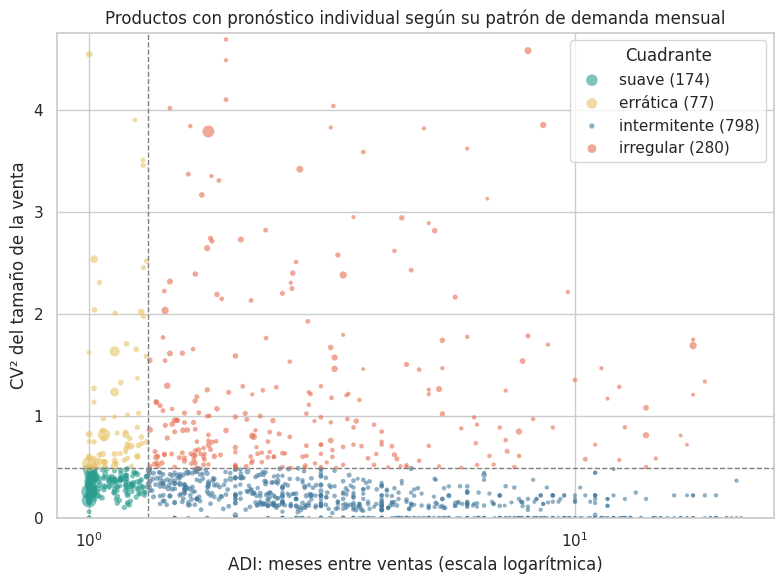

   (Se muestran hasta el percentil 99 de CV²; quedan fuera del gráfico 14 productos)

3) Cuadrante en ene-2023–oct-2024 (filas) frente a nov-2024–ago-2026 (columnas): 966 productos con venta en ambas mitades
cuadrante     errática  insuficiente  intermitente  irregular  suave  All
cuadrante                                                                
errática            22             0            23         15     25   85
insuficiente         1            51            99         27      2  180
intermitente         5            54           278         79     12  428
irregular            2            10            56         31      2  101
suave               25             3            49         15     80  172
All                 55           118           505        167    121  966
   Mismo cuadrante en ambas mitades (sin 'insuficiente'): 57.2% de 719 productos
   Solo con venta en la segunda mitad (productos más recientes): 363


In [219]:
# 9.1 — Cuadrantes ADI/CV² mensuales y su estabilidad — usa prod (7.5), i_mes, mes e intermitencia (7.4)
ORDEN = ["suave", "errática", "intermitente", "irregular", "insuficiente"]
ind = prod.index[prod["destino"].eq("pronóstico individual")]
cl = i_mes.reindex(ind).copy()
cl["u_ultimo_año"] = prod.loc[ind, "u_ultimo_año"]

# 1) Resumen por cuadrante
res = (cl.groupby("cuadrante")
         .agg(productos=("ADI", "size"), ADI_mediano=("ADI", "median"),
              CV2_mediano=("CV2", "median"), u=("u_ultimo_año", "sum"))
         .reindex(ORDEN).dropna(how="all"))
res["% demanda último año"] = 100 * res["u"] / cl["u_ultimo_año"].sum()
print(f"1) Productos con pronóstico individual: {len(ind)}")
print(res.drop(columns="u").round(2).to_string())

# 2) Gráfico ADI frente a CV² (tamaño del punto = demanda del último año)
colores = {"suave": "#2a9d8f", "errática": "#e9c46a", "intermitente": "#457b9d", "irregular": "#e76f51"}
fig, ax = plt.subplots(figsize=(8, 6))
for k, col in colores.items():
    d = cl[cl["cuadrante"].eq(k)]
    ax.scatter(d["ADI"], d["CV2"], s=8 + 120 * np.sqrt(d["u_ultimo_año"] / cl["u_ultimo_año"].max()),
               c=col, alpha=0.6, edgecolors="none", label=f"{k} ({len(d)})")
ax.axvline(1.32, ls="--", c="gray", lw=1)
ax.axhline(0.49, ls="--", c="gray", lw=1)
ax.set_xscale("log")
ax.set_ylim(0, cl["CV2"].quantile(0.99) * 1.05)
ax.set_xlabel("ADI: meses entre ventas (escala logarítmica)")
ax.set_ylabel("CV² del tamaño de la venta")
ax.set_title("Productos con pronóstico individual según su patrón de demanda mensual")
ax.legend(title="Cuadrante")
plt.tight_layout()
plt.show()
print(f"   (Se muestran hasta el percentil 99 de CV²; quedan fuera del gráfico "
      f"{cl['CV2'].gt(cl['CV2'].quantile(0.99)).sum()} productos)")

# 3) Estabilidad: ¿el cuadrante se mantiene entre la primera y la segunda mitad del periodo?
corte = pd.Period("2024-10", "M")
m9 = mes[mes["producto"].isin(ind)]
p1 = intermitencia(m9[m9["mes"].le(corte)], "y_mes", "producto")
p2 = intermitencia(m9[m9["mes"].gt(corte)], "y_mes", "producto")
ambos = p1.index.intersection(p2.index)
a, b = p1.loc[ambos, "cuadrante"], p2.loc[ambos, "cuadrante"]
print(f"\n3) Cuadrante en ene-2023–oct-2024 (filas) frente a nov-2024–ago-2026 (columnas): {len(ambos)} productos con venta en ambas mitades")
print(pd.crosstab(a, b, margins=True).to_string())
validos = a.ne("insuficiente") & b.ne("insuficiente")
print(f"   Mismo cuadrante en ambas mitades (sin 'insuficiente'): {(a[validos] == b[validos]).mean():.1%} de {validos.sum()} productos")
print(f"   Solo con venta en la segunda mitad (productos más recientes): {len(p2.index.difference(p1.index))}")

**Lectura 9.1 — Cuadrantes ADI/CV² mensuales (Opción B):** de los 1.329 productos con pronóstico
individual, 174 son suaves y 77 erráticos (19 % de los productos, 79,1 % de la demanda del último año):
venden casi todos los meses. Los 798 intermitentes (60 % de los productos) solo hacen el 6,8 % de la
demanda, y los 280 irregulares, el 14,1 %. Muchos intermitentes venden siempre la misma cantidad cuando
venden (CV² = 0): lo incierto es cuándo, no cuánto. Los cuatro cuadrantes tienen productos suficientes
para que la competencia de modelos por cuadrante sea viable.

In [220]:
# 9.1 B — ¿La inestabilidad del cuadrante afecta a la demanda importante o a productos pequeños?
w = prod.loc[ambos, "u_ultimo_año"]
igual = validos & (a == b)
print(f"1) Mismo cuadrante — por productos: {(a[validos] == b[validos]).mean():.1%} | "
      f"ponderado por demanda del último año: {100 * w[igual].sum() / w[validos].sum():.1f} %")

# 2) Por cuadrante de la primera mitad
t = pd.DataFrame({
    "productos":          validos.groupby(a).sum(),
    "% mismo (productos)": 100 * igual.groupby(a).sum() / validos.groupby(a).sum(),
    "% mismo (demanda)":   100 * w[igual].groupby(a[igual]).sum() / w[validos].groupby(a[validos]).sum(),
}).drop(index="insuficiente", errors="ignore").round(1)
print("\n2) Estabilidad según el cuadrante de la primera mitad:")
print(t.to_string())

# 3) ¿Es ruido de los cortes? Productos lejos de las líneas en ambas mitades
lejos = lambda p: ~p["ADI"].between(1.1, 1.6) & ~p["CV2"].between(0.35, 0.65)
lj = validos & lejos(p1.loc[ambos]) & lejos(p2.loc[ambos])
print(f"\n3) Productos lejos de los cortes en ambas mitades: {lj.sum()} | mismo cuadrante: {(a[lj] == b[lj]).mean():.1%} "
      f"(frente a {(a[validos] == b[validos]).mean():.1%} en todos)")

1) Mismo cuadrante — por productos: 57.2% | ponderado por demanda del último año: 59.9 %

2) Estabilidad según el cuadrante de la primera mitad:
              productos  % mismo (productos)  % mismo (demanda)
cuadrante                                                      
errática             85                 25.9               39.3
intermitente        374                 74.3               44.5
irregular            91                 34.1               83.9
suave               169                 47.3               69.2

3) Productos lejos de los cortes en ambas mitades: 305 | mismo cuadrante: 77.7% (frente a 57.2% en todos)


**Lectura 9.1 B — Estabilidad del cuadrante:** al clasificar por separado las dos mitades del periodo
(ene-2023 a oct-2024 y nov-2024 a ago-2026), el cuadrante se mantiene en el 57,2 % de los productos y en
el 59,9 % ponderado por demanda: la inestabilidad también afecta a los productos importantes.
- **Por cuadrante:** el errático es el más inestable (se mantiene el 25,9 %), seguido del irregular
  (34,1 %) y el suave (47,3 %). El intermitente es el más estable (74,3 %). Ponderado por demanda, los
  suaves e irregulares grandes tienden a seguir igual (69,2 % y 83,9 %).
- **Ruido de frontera:** en los 305 productos alejados de las líneas de corte en ambas mitades, la
  estabilidad sube al 77,7 %. Una parte del cambio es ruido cerca de los cortes y otra es cambio real del
  catálogo.
- **Decisión (S30, aprobada por el equipo):** la clasificación se recalcula en cada corte de evaluación
  con los 24 meses anteriores, sin usar información futura; todos los modelos se evalúan en todas las
  series, y el cuadrante se usa para elegir el modelo y para reportar los resultados.

| Cuadrante | Candidatos | Referencia mínima |
|---|---|---|
| Suave | DeepAR, ETS | Naive estacional |
| Errática | DeepAR, ETS | Naive estacional, media móvil |
| Intermitente | DeepAR, Croston, SBA, TSB | Media móvil |
| Irregular | DeepAR, SBA, TSB, ADIDA/IMAPA | Media móvil |

| Cuadrante (1.ª mitad) | Se mantiene (productos) | Se mantiene (demanda) | Lectura |
|---|---:|---:|---|
| Suave | 47,3 % | 69,2 % | Los grandes suelen seguir suaves; los pequeños pierden frecuencia |
| Errática | 25,9 % | 39,3 % | Muy inestable; es un grupo chico que salta a suave o a intermitente |
| Intermitente | 74,3 % | 44,5 % | Los pequeños son estables; los grandes cambian (suben o bajan de frecuencia) |
| Irregular | 34,1 % | 83,9 % | Los grandes irregulares siguen siéndolo; los pequeños se vuelven intermitentes |

#### Conclusión 9 — Segmentación por patrón de demanda
- De los 1.329 productos con pronóstico individual, 251 venden casi todos los meses (174 suaves y 77
  erráticos) y concentran el 79,1 % de la demanda del último año; los 1.078 intermitentes e irregulares
  son la mayoría de los productos, pero solo el 20,9 % de la demanda.
- Muchos intermitentes venden siempre la misma cantidad: el reto es predecir cuándo, no cuánto.
- El cuadrante cambia con el tiempo (57 % de estabilidad; 78 % lejos de los cortes), por lo que en el
  modelado se recalcula en cada corte con 24 meses (S30, aprobado) y todos los modelos se evalúan en todas
  las series.
- Candidatos por cuadrante: suave y errático, DeepAR y ETS frente a naive estacional; intermitente,
  DeepAR, Croston, SBA y TSB; irregular, DeepAR, SBA, TSB y ADIDA/IMAPA; todos frente a media móvil.

### 10. Descripción de la demanda
Se describe la venta observada (fv de mercancía) desde la primera venta de cada producto: su
distribución, su evolución en el tiempo y sus valores atípicos. Los atípicos se marcan y se revisan,
pero no se recortan: un pico de venta puede ser un pedido grande real, y recortarlo haría que el
modelo subestime la demanda.

#### 10.1 — Distribución de la demanda

1) Unidades vendidas por producto (desde su primera venta):
count     4761.0
mean        50.5
std        649.8
min          1.0
25%          1.0
50%          3.0
75%         12.0
90%         49.0
99%        490.2
max      29588.0
   media / mediana = 16.8 | asimetría = 32.3

2) Tamaño de la venta semanal, cuando hay venta:
count    43705.0
mean         5.5
std         26.8
min          1.0
25%          1.0
50%          1.0
75%          2.0
90%          6.0
99%        100.0
max       1500.0
   semanas con venta de 1 unidad: 59.7% | asimetría = 17.2

3) Concentración:
   El 1 % de los productos que más venden hace el 64.5 % de las unidades
   El 5 % de los productos que más venden hace el 81.1 % de las unidades
   El 10 % de los productos que más venden hace el 88.2 % de las unidades
   El 20 % de los productos que más venden hace el 94.1 % de las unidades


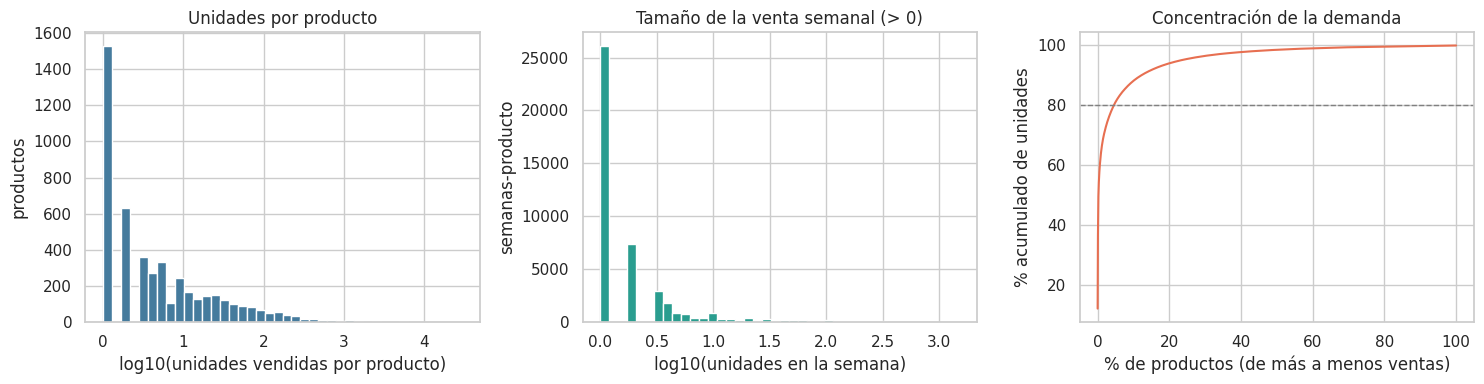

In [221]:
# 10.1 — Distribución de la demanda — usa m5 (7.5)
vt = m5.groupby("producto")["u_venta"].sum()
nz = m5.loc[m5["u_venta"].gt(0), "u_venta"]

print("1) Unidades vendidas por producto (desde su primera venta):")
print(vt.describe(percentiles=[.25, .5, .75, .9, .99]).round(1).to_string())
print(f"   media / mediana = {vt.mean() / vt.median():.1f} | asimetría = {vt.skew():.1f}")

print("\n2) Tamaño de la venta semanal, cuando hay venta:")
print(nz.describe(percentiles=[.25, .5, .75, .9, .99]).round(1).to_string())
print(f"   semanas con venta de 1 unidad: {nz.eq(1).mean():.1%} | asimetría = {nz.skew():.1f}")

o = vt.sort_values(ascending=False)
acum = 100 * o.cumsum() / o.sum()
x = 100 * np.arange(1, len(o) + 1) / len(o)
print("\n3) Concentración:")
for p in [1, 5, 10, 20]:
    print(f"   El {p} % de los productos que más venden hace el {acum.iloc[int(len(o) * p / 100) - 1]:.1f} % de las unidades")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(np.log10(vt[vt > 0]), bins=40, color="#457b9d")
ax[0].set(xlabel="log10(unidades vendidas por producto)", ylabel="productos", title="Unidades por producto")
ax[1].hist(np.log10(nz), bins=40, color="#2a9d8f")
ax[1].set(xlabel="log10(unidades en la semana)", ylabel="semanas-producto", title="Tamaño de la venta semanal (> 0)")
ax[2].plot(x, acum.values, color="#e76f51")
ax[2].axhline(80, ls="--", c="gray", lw=1)
ax[2].set(xlabel="% de productos (de más a menos ventas)", ylabel="% acumulado de unidades", title="Concentración de la demanda")
plt.tight_layout()
plt.show()

**Lectura 10.1 — Distribución:** la demanda está muy concentrada: el 1 % de los productos hace el 64,5 %
de las unidades, el 5 % el 81,1 % y el 20 % el 94,1 %. El producto típico vende poco (mediana de 3
unidades en toda su historia, frente a una media de 50,5; asimetría de 32). Cuando hay venta semanal, en
el 59,7 % de los casos es de 1 unidad; el percentil 99 es de 100. Es una distribución de conteos pequeños
con picos ocasionales, compatible con la binomial negativa (S18) y lejana a la normal: las pruebas de
hipótesis deben ser no paramétricas.

#### 10.2 — Evolución de la demanda en el tiempo

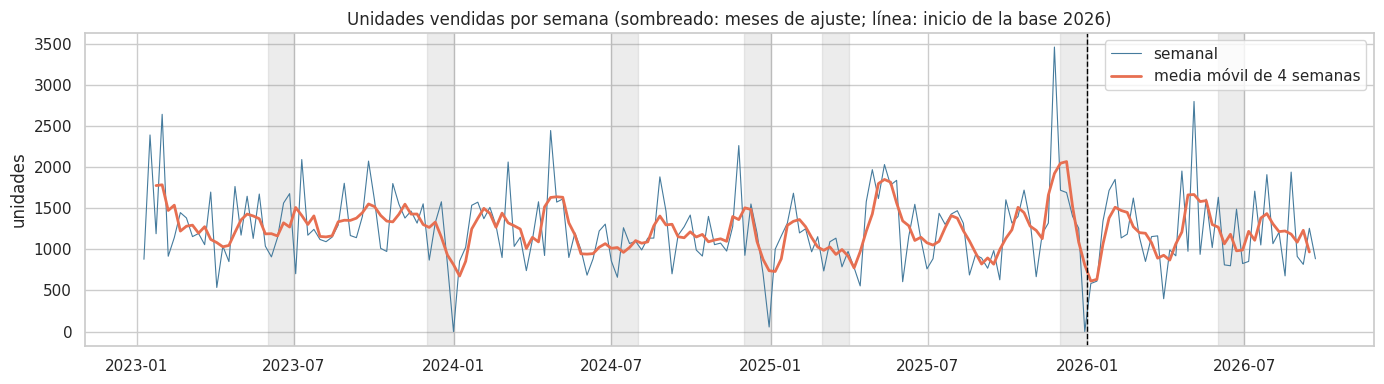

1) Variación de las unidades de enero a agosto frente al año anterior:
año
2024   -6.8
2025   -0.8
2026    2.1

2) Peso de cada mes en el total del año (%, años completos):
año  2023  2024  2025
mes                  
1     9.3   6.8   7.8
2     7.6   9.1   7.2
3     8.1   8.4   6.4
4     6.3  11.4   8.2
5     9.4   8.3  11.6
6     8.2   6.8   6.9
7     8.3   7.6   8.6
8     8.5   8.7   7.2
9     8.9   8.1   6.4
10    9.2   8.2  10.0
11    9.3   9.5  10.3
12    6.9   7.2   9.4


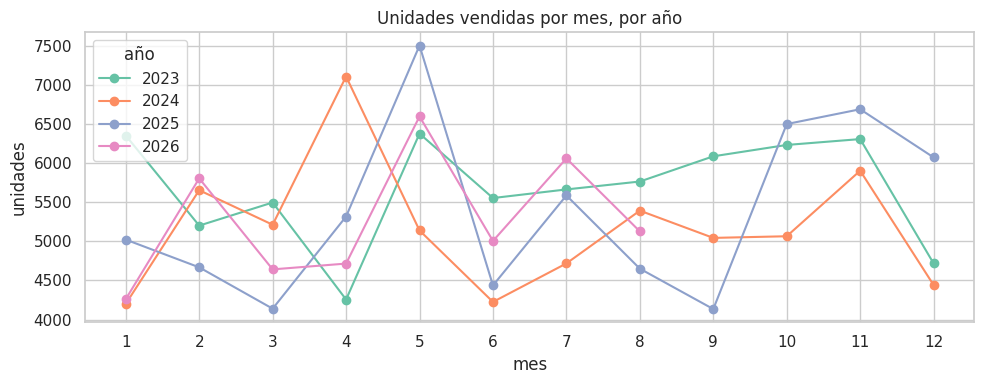


3) Productos distintos vendidos por mes (promedio por año):
fecha
2023    607.0
2024    619.0
2025    620.0
2026    600.0


In [222]:
# 10.2 — Evolución de la demanda en el tiempo — usa m5 (7.5), fvm y ULT_MES (7.4), meses_ajuste (5.2 D)
# 1) Serie semanal total
sem_tot = m5.groupby("semana")["u_venta"].sum()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(sem_tot.index, sem_tot.values, lw=0.8, color="#457b9d", label="semanal")
ax.plot(sem_tot.index, sem_tot.rolling(4, center=True).mean(), lw=2, color="#e76f51", label="media móvil de 4 semanas")
for p in meses_ajuste:
    ax.axvspan(p.start_time, p.end_time, color="gray", alpha=0.15)
ax.axvline(pd.Timestamp("2026-01-01"), ls="--", c="black", lw=1)
ax.set(title="Unidades vendidas por semana (sombreado: meses de ajuste; línea: inicio de la base 2026)",
       ylabel="unidades")
ax.legend()
plt.tight_layout()
plt.show()

# 2) Mes a mes, un año sobre otro
mt = fvm.groupby(fvm["fecha"].dt.to_period("M"))["sal_cant"].sum()
mt = mt[mt.index <= ULT_MES]
tab = pd.DataFrame({"año": mt.index.year, "mes": mt.index.month, "u": mt.values}).pivot(index="mes", columns="año", values="u")
print("1) Variación de las unidades de enero a agosto frente al año anterior:")
print((100 * tab.loc[1:8].sum().pct_change()).round(1).dropna().to_string())
print("\n2) Peso de cada mes en el total del año (%, años completos):")
completos = [a for a in tab.columns if tab[a].notna().sum() == 12]
print((100 * tab[completos] / tab[completos].sum()).round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
tab.plot(ax=ax, marker="o")
ax.set(xticks=range(1, 13), xlabel="mes", ylabel="unidades", title="Unidades vendidas por mes, por año")
plt.tight_layout()
plt.show()

# 3) ¿Cuántos productos distintos se venden cada mes?
act = fvm[fvm["sal_cant"].gt(0)].groupby(fvm["fecha"].dt.to_period("M"))["producto"].nunique()
act = act[act.index <= ULT_MES]
print("\n3) Productos distintos vendidos por mes (promedio por año):")
print(act.groupby(act.index.year).mean().round(0).to_string())

**Lectura 10.2 — Evolución en el tiempo:** la demanda total no tiene tendencia (enero–agosto: −6,8 % en
2024, −0,8 % en 2025, +2,1 % en 2026) y la empresa vende unos 600 productos distintos cada mes, de forma
estable. Hay una estacionalidad moderada e irregular: octubre–noviembre está por encima de su peso esperado
los tres años completos (17,7 %–20,3 % frente a 16,7 %), abril–mayo en dos de tres años y junio por debajo
en dos de tres. Cada mes pesa entre el 6,3 % y el 11,6 % del año. Además, la venta cae casi a cero en la
última semana de diciembre o la primera de enero todos los años, a veces precedida de un pico de compras;
coincide con el ajuste de inventario de diciembre y probablemente corresponde a un cierre por toma física.
Ambas cosas se ponen a prueba en la sección 11. El cambio a la base de 2026 no produce un salto en el nivel.

#### 10.3 — Atípicos: picos de venta semanal
Para cada producto con al menos 5 semanas con venta, una semana es atípica si su venta supera el
mayor de dos límites: Q3 + 3 × IQR, o 3 veces la mediana, ambos calculados sobre sus semanas con
venta (los ceros no cuentan, porque la demanda es intermitente). Se revisa si el pico viene de una
sola factura grande (pedido real) o de filas marcadas como `revisar` (posible error de registro).

In [223]:
# 10.3 — Atípicos: picos de venta semanal (se marcan, no se recortan) — usa m5, prod (7.5), fvm (7.4)
pos = m5[m5["u_venta"].gt(0)]
g = pos.groupby("producto")["u_venta"]
lim = pd.DataFrame({"n": g.size(), "q1": g.quantile(0.25), "q3": g.quantile(0.75), "med": g.median()})
lim["umbral"] = np.maximum(lim["q3"] + 3 * (lim["q3"] - lim["q1"]), 3 * lim["med"])
lim = lim[lim["n"].ge(5)]
pos = pos.join(lim["umbral"], on="producto")
base_at = pos["umbral"].notna()
pos["atipico"] = pos["u_venta"].gt(pos["umbral"])
at = pos[pos["atipico"]].copy()
print(f"1) Productos evaluados (≥ 5 semanas con venta): {len(lim)} | semanas atípicas: {len(at):,} "
      f"({100 * len(at) / base_at.sum():.1f} % de sus semanas con venta) | productos con alguna: {at['producto'].nunique()}")
print(f"   Unidades en semanas atípicas: {100 * at['u_venta'].sum() / pos.loc[base_at, 'u_venta'].sum():.1f} % "
      f"de las unidades de esos productos")

# 2) ¿El pico viene de una sola factura grande?
fvs = fvm.assign(semana=fvm["fecha"].dt.to_period("W-SUN").dt.start_time,
                 docu=fvm["archivo"] + "|" + fvm["num_doc"].astype(str))
por_doc = fvs.groupby(["producto", "semana", "docu"])["sal_cant"].sum()
at = (at.join(por_doc.groupby(level=["producto", "semana"]).max().rename("max_doc"), on=["producto", "semana"])
        .join(por_doc.groupby(level=["producto", "semana"]).size().rename("n_docs"), on=["producto", "semana"]))
un_pedido = (at["max_doc"] / at["u_venta"]).ge(0.8)
print(f"2) Semanas atípicas explicadas por UNA sola factura (≥ 80 % de sus unidades): {un_pedido.mean():.1%} | "
      f"facturas en la semana (mediana): {at['n_docs'].median():.0f}")

# 3) ¿Posibles errores de registro? (filas marcadas 'revisar' en el 4.4)
rv = fvs[fvs["revisar"]].groupby(["producto", "semana"]).size()
print(f"3) Semanas atípicas con alguna fila marcada 'revisar': "
      f"{at.set_index(['producto', 'semana']).index.isin(rv.index).sum()}")

# 4) ¿Dónde están?
print("\n4) Semanas atípicas según el destino del producto:")
print(at["producto"].map(prod["destino"]).value_counts().to_string())
mes_at  = at["semana"].dt.month.value_counts(normalize=True)
mes_all = pos.loc[base_at, "semana"].dt.month.value_counts(normalize=True)
print("   Meses con más atípicos de lo esperado (cociente > 1,3):")
print((mes_at / mes_all).sort_index().round(2)[lambda s: s.gt(1.3)].to_string())

# 5) Marcar en la serie del modelo (no se modifica y)
clave = set(zip(at["producto"], at["semana"]))
serie_modelo["atipico"] = [(u, d) in clave for u, d in zip(serie_modelo["unique_id"], serie_modelo["ds"])]
print(f"\n5) serie_modelo: {serie_modelo['atipico'].sum():,} semanas marcadas como atípicas (y no cambia)")

1) Productos evaluados (≥ 5 semanas con venta): 1450 | semanas atípicas: 689 (1.8 % de sus semanas con venta) | productos con alguna: 434
   Unidades en semanas atípicas: 11.8 % de las unidades de esos productos
2) Semanas atípicas explicadas por UNA sola factura (≥ 80 % de sus unidades): 64.2% | facturas en la semana (mediana): 2
3) Semanas atípicas con alguna fila marcada 'revisar': 0

4) Semanas atípicas según el destino del producto:
producto
pronóstico individual        578
sin pronóstico (inactivo)    111
   Meses con más atípicos de lo esperado (cociente > 1,3):
semana
1     1.51
11    1.38

5) serie_modelo: 689 semanas marcadas como atípicas (y no cambia)


**Lectura 10.3 — Atípicos:** en los 1.450 productos con al menos 5 semanas con venta, 689 semanas (1,8 %)
superan el límite (Q3 + 3 × IQR, o 3 veces la mediana) y concentran el 11,8 % de sus unidades. En el 64,2 %
de los casos, una sola factura explica el 80 % o más del pico, y ninguna semana atípica contiene filas
marcadas como `revisar`: son pedidos grandes reales, no errores. Son más frecuentes en enero y noviembre.
Se mantienen sin recortar y quedan marcados en `serie_modelo` (columna `atipico`).

#### Conclusión 10 — Descripción de la demanda
- **Concentración extrema:** el 1 % de los productos hace el 64,5 % de las unidades y el 5 %, el 81,1 %.
- **Conteos pequeños:** el 59,7 % de las semanas con venta son de 1 unidad; la distribución es muy
  asimétrica (binomial negativa, S18; pruebas no paramétricas).
- **Nivel estable:** sin tendencia entre 2023 y 2026 y unos 600 productos vendidos por mes.
- **Estacionalidad moderada:** octubre–noviembre por encima del promedio los tres años; abril–mayo en dos
  de tres; caída a casi cero en el cambio de año (probable cierre por inventario). Se prueba en la sección 11.
- **Atípicos reales:** 1,8 % de las semanas con venta, casi siempre por una sola factura grande; se
  conservan y quedan marcados (S33).

### 11. Estacionalidad y festivos
Se prueba con datos lo que sugirió la sección 10: si hay un patrón mensual que se repite, si la caída de
fin de año es un cierre y si los festivos reducen la venta. Las pruebas son no paramétricas (la demanda no
es normal, 10.1) y comparan dentro del mismo año o del mismo mes, para que la temporada no confunda los
resultados.

In [224]:
# 11.0 — Preparación: venta diaria y calendario de festivos de Colombia
co = holidays.Colombia(years=range(2022, 2027))                 # incluye los traslados al lunes (Ley Emiliani)
dv = fvm.groupby("fecha")["sal_cant"].sum()
dv = dv.reindex(pd.date_range("2023-01-01", "2026-09-27", freq="D"), fill_value=0)
d = pd.DataFrame({"u": dv})
d["festivo"] = [x in co for x in d.index]
d["dow"] = d.index.dayofweek                                     # 0 = lunes … 6 = domingo
d["ym"] = d.index.to_period("M")
print(f"Días: {len(d)} | festivos en el periodo: {d['festivo'].sum()} | "
      f"de ellos en lunes: {(d['festivo'] & d['dow'].eq(0)).sum()}")

def biserial(dif):
    """Correlación biserial de rangos para datos pareados: −1 (siempre menor) a +1 (siempre mayor)."""
    dif = dif[dif != 0]
    r = dif.abs().rank()
    return (r[dif > 0].sum() - r[dif < 0].sum()) / r.sum()

Días: 1366 | festivos en el periodo: 67 | de ellos en lunes: 43


#### 11.1 — ¿Hay un patrón mensual que se repite cada año?
Prueba de Friedman: compara los 12 meses usando cada año completo (2023, 2024, 2025) como bloque. El
tamaño del efecto es la W de Kendall: 0 = el orden de los meses no se repite; 1 = es idéntico cada año.

In [225]:
# 11.1 — Prueba de Friedman — usa tab (10.2)
completos = [2023, 2024, 2025]
stat, p = friedmanchisquare(*[tab.loc[m, completos].values for m in range(1, 13)])
W = stat / (len(completos) * (12 - 1))
print(f"1) Friedman: χ² = {stat:.2f} | p = {p:.3f} | W de Kendall = {W:.2f} (3 años, 12 meses)")

rangos = tab[completos].rank(ascending=False).mean(axis=1)       # 1 = el mes más fuerte del año
print("\n2) Puesto promedio de cada mes (1 = más ventas del año):")
print(rangos.round(1).sort_values().to_string())

1) Friedman: χ² = 13.00 | p = 0.293 | W de Kendall = 0.39 (3 años, 12 meses)

2) Puesto promedio de cada mes (1 = más ventas del año):
mes
11    2.3
5     2.7
10    4.7
4     6.3
8     6.3
2     7.0
7     7.0
1     7.0
9     8.3
3     8.3
12    8.3
6     9.7


**Lectura 11.1 — Estacionalidad mensual:** la prueba de Friedman no confirma un patrón mensual (χ² = 13,0;
p = 0,29; W de Kendall = 0,39), aunque con tres años completos su potencia es baja. Los puestos promedio
coinciden con la sección 10: noviembre y mayo son los meses más fuertes y junio el más débil. La
estacionalidad mensual queda como hipótesis: en el piloto se compara DeepAR con y sin una variable de mes.

#### 11.2 — ¿La caída de fin de año es un cierre?
Se cuentan los días hábiles (lunes a sábado, no festivos) sin facturación entre el 15 de diciembre y el
15 de enero, y se comparan con el resto del año.

In [226]:
# 11.2 — Días hábiles sin facturación alrededor del cambio de año
for y in [2023, 2024, 2025]:
    v = d.loc[f"{y}-12-15":f"{y + 1}-01-15"]
    hab = v[v["dow"].le(5) & ~v["festivo"]]
    sin = hab.index[hab["u"].eq(0)]
    ult_dic = v.loc[f"{y}-12-15":f"{y}-12-31"].query("u > 0").index.max()
    pri_ene = v.loc[f"{y + 1}-01-01":].query("u > 0").index.min()
    print(f"{y}/{y + 1}: última venta de diciembre {ult_dic:%d-%b} | primera de enero {pri_ene:%d-%b} | "
          f"días hábiles sin venta: {len(sin)} → {[x.strftime('%d-%b') for x in sin]}")

hab_all = d[d["dow"].le(5) & ~d["festivo"]]
print(f"\nControl: días hábiles sin venta en todo el periodo: {hab_all['u'].eq(0).mean():.1%}")

2023/2024: última venta de diciembre 30-Dec | primera de enero 09-Jan | días hábiles sin venta: 6 → ['16-Dec', '02-Jan', '03-Jan', '04-Jan', '05-Jan', '06-Jan']
2024/2025: última venta de diciembre 31-Dec | primera de enero 07-Jan | días hábiles sin venta: 3 → ['02-Jan', '03-Jan', '04-Jan']
2025/2026: última venta de diciembre 29-Dec | primera de enero 07-Jan | días hábiles sin venta: 6 → ['30-Dec', '31-Dec', '02-Jan', '03-Jan', '05-Jan', '06-Jan']

Control: días hábiles sin venta en todo el periodo: 2.4%


In [227]:
# 11.2 B — ¿El inventario de mitad de año también detiene la facturación?
hab = d[d["dow"].le(5) & ~d["festivo"]]
sin = hab[hab["u"].eq(0)]
print("Días hábiles sin venta, por mes:")
print(sin.groupby(sin.index.to_period("M")).size().to_string())
print(f"\nEn junio–julio: {sin.index.month.isin([6, 7]).sum()} días | "
      f"en la ventana de fin de año (26-dic a 10-ene): {len(cierre)} días")

Días hábiles sin venta, por mes:
2023-01    6
2023-04    1
2023-12    1
2024-01    5
2024-03    1
2025-01    3
2025-04    1
2025-12    3
2026-01    4
2026-04    1
Freq: M

En junio–julio: 0 días | en la ventana de fin de año (26-dic a 10-ene): 11424 días


**Lectura 11.2 — Cierre de fin de año:** los tres años la empresa deja de facturar entre el 30–31 de
diciembre y el 7–9 de enero; los días hábiles sin venta se concentran del 2 al 6 de enero, frente al 2,4 %
de días hábiles sin venta en el resto del periodo. Es un cierre, probablemente para la toma física de
inventario de diciembre (S21). Esas semanas no son demanda baja.

#### 11.3 — ¿Los festivos reducen la venta?
Se compara cada lunes festivo con la mediana de los lunes no festivos del mismo mes, y cada semana con
festivo con la mediana de las semanas sin festivo del mismo mes (prueba de Wilcoxon pareada; tamaño del
efecto: correlación biserial de rangos). Se excluye del 15 de diciembre al 15 de enero, que se analiza en
la 11.2.

In [228]:
# 11.3 — Efecto de los festivos (Wilcoxon pareado + biserial de rangos)
m_, d_ = d.index.month, d.index.day
fin_año = ((m_ == 12) & (d_ >= 15)) | ((m_ == 1) & (d_ <= 15))
dd = d[~fin_año]

# 1) Lunes festivo frente a lunes normales del mismo mes
lun = dd[dd["dow"].eq(0)]
ref = lun[~lun["festivo"]].groupby("ym")["u"].median()
pf = lun[lun["festivo"]].assign(ref=lambda t: t["ym"].map(ref)).dropna(subset=["ref"])
st1, p1 = wilcoxon(pf["u"], pf["ref"])
print(f"1) Lunes festivos: {len(pf)} | con venta 0: {pf['u'].eq(0).mean():.0%} | "
      f"venta mediana: {pf['u'].median():.0f} frente a {pf['ref'].median():.0f} de los lunes normales")
print(f"   Wilcoxon p = {p1:.4f} | biserial de rangos = {biserial(pf['u'] - pf['ref']):.2f}")

# 2) Sin los festivos, ¿el lunes sigue vendiendo menos?
hab = dd[dd["dow"].le(5) & ~dd["festivo"]]
dias_n = ["lun", "mar", "mié", "jue", "vie", "sáb"]
print("\n2) Venta media por día, solo días no festivos:")
print(hab.groupby("dow")["u"].mean().rename(index=dict(enumerate(dias_n))).round(0).to_string())

# 3) Semana con algún festivo (lunes a sábado) frente a semanas sin festivo del mismo mes
dd = dd.assign(semana=dd.index.to_period("W-SUN").start_time,
               fest_hab=dd["festivo"] & dd["dow"].le(5))
ws = dd.groupby("semana").agg(u=("u", "sum"), dias=("u", "size"), fest=("fest_hab", "any"))
ws = ws[ws["dias"].eq(7)].assign(ym=lambda t: t.index.to_period("M"))
ref_w = ws[~ws["fest"]].groupby("ym")["u"].median()
wf = ws[ws["fest"]].assign(ref=lambda t: t["ym"].map(ref_w)).dropna(subset=["ref"])
st3, p3 = wilcoxon(wf["u"], wf["ref"])
print(f"\n3) Semanas con festivo: {len(wf)} | venta mediana {wf['u'].median():.0f} frente a {wf['ref'].median():.0f} "
      f"| diferencia mediana {100 * ((wf['u'] - wf['ref']) / wf['ref']).median():.1f} %")
print(f"   Wilcoxon p = {p3:.4f} | biserial de rangos = {biserial(wf['u'] - wf['ref']):.2f}")

1) Lunes festivos: 37 | con venta 0: 100% | venta mediana: 0 frente a 186 de los lunes normales
   Wilcoxon p = 0.0000 | biserial de rangos = -1.00

2) Venta media por día, solo días no festivos:
dow
lun    230.0
mar    247.0
mié    245.0
jue    237.0
vie    236.0
sáb    152.0

3) Semanas con festivo: 48 | venta mediana 1056 frente a 1280 | diferencia mediana -23.8 %
   Wilcoxon p = 0.0002 | biserial de rangos = -0.62


**Lectura 11.3 — Festivos:** los 37 lunes festivos analizados tuvieron venta 0 (Wilcoxon p < 0,0001;
biserial = −1,00): la empresa no factura en festivos. Sin ellos, el lunes vende como el resto de la semana
(230 unidades frente a 236–247 de martes a viernes), lo que confirma la hipótesis de la 7.0: el lunes bajo
se debe a los festivos trasladados. Las semanas con festivo venden un 23,8 % menos que las del mismo mes sin
festivo (biserial = −0,62; p = 0,0002): la venta perdida no se recupera en los otros días. El sábado vende
alrededor del 60 % de un día entre semana.

#### 11.4 — Variable de calendario para el modelo: días hábiles de la semana
Festivos y cierre de fin de año reducen la venta porque quitan días de facturación, y ambos se conocen de
antemano. Se resumen en una sola variable: días hábiles equivalentes por semana (lunes a viernes = 1,
sábado = 0,6, festivos, domingos y cierre = 0). El cierre observado se toma de los datos (11.2); para años
futuros se asume del 1 al 6 de enero, a confirmar con la empresa.

In [229]:
# 11.4 — Días hábiles equivalentes por semana (variable futura conocida para DeepAR) — usa d, co (11.0), serie_modelo y m5 (7.5)
PESO_SABADO = 0.6                                   # 11.3: el sábado vende ≈ 60 % de un día entre semana

# Cierre observado: días hábiles sin venta del 26-dic al 10-ene (11.2)
cierre = set()
for y in [2022, 2023, 2024, 2025]:
    v = d.loc[f"{y}-12-26":f"{y + 1}-01-10"]
    hv = v[v["dow"].le(5) & ~v["festivo"]]
    cierre |= set(hv.index[hv["u"].eq(0)])

# Sábado Santo: no es festivo oficial, pero la empresa no factura (11.2 B)
sabado_santo = {pd.Timestamp(f) + pd.Timedelta(days=1)
                for f, nombre in co.items() if "viernes santo" in nombre.lower() or "good friday" in nombre.lower()}
print("Sábados Santos:", sorted(x.strftime("%d-%b-%Y") for x in sabado_santo))

def dias_habiles(inicio):
    """Días hábiles equivalentes de la semana que empieza el lunes 'inicio' (sirve también para semanas futuras)."""
    total = 0.0
    for x in pd.date_range(inicio, periods=7, freq="D"):
        if x.dayofweek == 6 or x in co or x in cierre or x in sabado_santo or (x.month == 1 and x.day <= 6):
            continue
        total += PESO_SABADO if x.dayofweek == 5 else 1.0
    return total

semanas = pd.Series(sorted(serie_modelo["ds"].unique()))
dh = pd.Series([dias_habiles(w) for w in semanas], index=semanas)
serie_modelo["dias_habiles"] = serie_modelo["ds"].map(dh)

# 1) Distribución y relación con la venta (correlación de Spearman, no paramétrica)
print("1) Semanas según días hábiles equivalentes:")
print(dh.value_counts().sort_index().to_string())
tot = m5.groupby("semana")["u_venta"].sum()
rho, p = spearmanr(dh.reindex(tot.index), tot)
print(f"\n2) Correlación de Spearman entre días hábiles y venta semanal total: ρ = {rho:.2f} | p = {p:.4f}")

# 3) La variable se conoce hacia el futuro: las 4 semanas siguientes al fin de los datos
fut = [fin_completa + pd.Timedelta(weeks=k) for k in range(1, 5)]
print("\n3) Próximas 4 semanas (horizonte):", {f"{w:%d-%b-%Y}": dias_habiles(w) for w in fut})
assert serie_modelo["dias_habiles"].notna().all(), "Hay semanas sin días hábiles"

Sábados Santos: ['04-Apr-2026', '08-Apr-2023', '16-Apr-2022', '19-Apr-2025', '30-Mar-2024']
1) Semanas según días hábiles equivalentes:
0.0      1
1.0      1
2.0      2
3.0      3
3.6      1
4.6     51
5.0      1
5.6    134

2) Correlación de Spearman entre días hábiles y venta semanal total: ρ = 0.41 | p = 0.0000

3) Próximas 4 semanas (horizonte): {'28-Sep-2026': 5.6, '05-Oct-2026': 5.6, '12-Oct-2026': 4.6, '19-Oct-2026': 5.6}


**Lectura 11.4 — Días hábiles de la semana:** se creó la variable `dias_habiles` (lunes a viernes = 1,
sábado = 0,6; festivos, domingos, Sábado Santo y cierre de inicio de año = 0) y se agregó a
`serie_modelo`. De las 195 semanas, 134 están completas (5,6 días), 51 tienen un festivo (4,6), 4 de
Semana Santa tienen 2 o 3 días y las del cierre de inicio de año, entre 0 y 2. La correlación de Spearman
con la venta semanal total es de 0,41 (p < 0,0001). La variable se calcula para cualquier semana futura
con el calendario de festivos y la regla de cierre del 1 al 6 de enero, coherente con el inventario
semestral confirmado por la empresa (S21); por ejemplo, la semana del 12-oct-2026 tiene 4,6 días por el
festivo del lunes.

#### Conclusión 11 — Estacionalidad y festivos
- **Festivos:** la empresa no factura en festivos (37 de 37 lunes festivos sin venta) y la venta perdida no
  se recupera: las semanas con festivo venden un 23,8 % menos. El lunes bajo de la 7.0 se debe a esto.
  Tampoco factura el Sábado Santo, aunque no es festivo oficial.
- **Cierre de inicio de año:** todos los años la facturación se detiene aproximadamente del 30-dic al
  6-ene; coincide con el inventario físico semestral que la empresa confirmó (S21). El inventario de mitad
  de año no detiene la facturación.
- **Estacionalidad mensual:** noviembre y mayo son los meses más fuertes y junio el más débil, pero el
  patrón no es estadísticamente significativo con tres años (Friedman p = 0,29; W = 0,39).
- **Para el modelo:** festivos, Sábado Santo y cierre se resumen en la variable conocida `dias_habiles`
  (ρ = 0,41 con la venta semanal), que DeepAR recibe como variable futura (S34). La variable de mes se
  prueba en el piloto (S35).

### 12. Indicadores para la empresa (E8)
Indicadores de gestión calculados con el último año completo de datos (52 semanas hasta el 27-sep-2026).
El kárdex registra costos, no precios: el valor se mide a costo y excluye las filas con costo_invalido
(S11). Solo se reportan porcentajes.

#### 12.1 — Clasificación ABC por valor y patrón de demanda
Clase A: productos que suman el 80 % del costo de lo vendido en el último año; B: el siguiente 15 %;
C: el 5 % restante. Se cruza con el cuadrante ADI/CV² (9.1) o con el destino del producto (7.5).

In [230]:
# 12.1 — ABC por costo de lo vendido (último año) × patrón de demanda — usa fvm (7.4), prod y fin_completa (7.5)
ini_año = fin_completa - pd.Timedelta(weeks=51)                    # 52 semanas completas
fin_año = fin_completa + pd.Timedelta(days=6)
v12 = fvm[fvm["fecha"].between(ini_año, fin_año) & ~fvm["costo_invalido"]]
val = v12.groupby("producto")["sal_total"].sum()
val = val[val > 0].sort_values(ascending=False)
previo = (val.cumsum() / val.sum()).shift(fill_value=0)              # el producto que cruza el 80 % entra en A
abc = pd.Series(np.select([previo.lt(0.80), previo.lt(0.95)], ["A", "B"], "C"), index=val.index)
prod["abc"] = abc.reindex(prod.index).fillna("sin venta último año")
prod["valor_venta_año"] = val.reindex(prod.index).fillna(0)

ORD_ABC = ["A", "B", "C", "sin venta último año"]
t1 = pd.DataFrame({
    "productos": prod["abc"].value_counts(),
    "% costo de lo vendido": (100 * prod.groupby("abc")["valor_venta_año"].sum() / val.sum()).round(1),
    "% unidades último año": (100 * prod.groupby("abc")["u_ultimo_año"].sum() / prod["u_ultimo_año"].sum()).round(1),
}).reindex(ORD_ABC)
print(f"1) Clasificación ABC ({ini_año:%d-%b-%Y} a {fin_año:%d-%b-%Y}):")
print(t1.to_string())

# Patrón: cuadrante para los de pronóstico individual; destino para los demás
patron = np.where(prod["destino"].eq("pronóstico individual"), prod["cuadrante_mes"], prod["destino"].str.split(" ").str[0])
prod["patron"] = patron
print("\n2) Productos por clase ABC (filas) y patrón de demanda (columnas):")
print(pd.crosstab(prod["abc"], prod["patron"]).reindex(ORD_ABC).fillna(0).astype(int).to_string())
print("\n3) % del costo de lo vendido:")
print((100 * pd.crosstab(prod["abc"], prod["patron"], values=prod["valor_venta_año"], aggfunc="sum")
       / val.sum()).reindex(ORD_ABC[:3]).fillna(0).round(1).to_string())

1) Clasificación ABC (29-Sep-2025 a 27-Sep-2026):
                      productos  % costo de lo vendido  % unidades último año
abc                                                                          
A                           441                   80.0                   66.2
B                           615                   15.0                   18.7
C                          1320                    5.0                   14.7
sin venta último año       2385                    0.0                    0.3

2) Productos por clase ABC (filas) y patrón de demanda (columnas):
patron                contra  errática  historia  intermitente  irregular   sin  suave
abc                                                                                   
A                          0        45        30           132         75    50    109
B                          0        14        76           268         78   143     36
C                         12        18       288           377    

**Lectura 12.1 — Clasificación ABC:** en el último año, 441 productos (clase A) hicieron el 80 % del costo
de lo vendido y el 66,2 % de las unidades; 615 (B) el 15 % y 1.320 (C) el 5 %. En la clase A, los
productos suaves y erráticos suman el 41,6 % del valor, pero los intermitentes e irregulares suman otro
28,6 % (207 productos): son importantes y difíciles de pronosticar, donde el modelo puede aportar más. Hay
30 productos de historia corta que ya son clase A (3,8 %). Además, 50 productos clase A no venden desde hace
más de 26 semanas (6,1 % del costo de lo vendido): se revisan en la 12.2 B.

#### 12.2 — Quiebres de stock por clase ABC
Semanas en quiebre corto (7.3) en el último año, solo en productos con stock y entre su primera y su
última venta. La venta perdida se estima como semanas en quiebre × venta media semanal del producto en
sus semanas observadas: es una aproximación, no un dato registrado.

In [231]:
# 12.2 — Quiebres cortos por clase ABC (último año) — usa serie_d3 (7.3) y prod (12.1)
qq = serie_d3
eva = (qq["manejo"].eq("con_stock") & qq["semana"].between(qq["prim"], qq["ult"])
       & qq["semana"].between(ini_año, fin_completa))
x = qq[eva].assign(abc=lambda t: t["producto"].map(prod["abc"]))

media = x[~x["quiebre"]].groupby("producto")["u_venta"].mean()          # venta media en semanas observadas
perdida = x[x["quiebre_corto"]].groupby("producto").size() * media.reindex(x.loc[x["quiebre_corto"], "producto"].unique())
t2 = x.groupby("abc").agg(productos=("producto", "nunique"), semanas=("quiebre_corto", "size"),
                          quiebres=("quiebre_corto", "sum"), vendido=("u_venta", "sum"))
t2["% semanas en quiebre"] = (100 * t2["quiebres"] / t2["semanas"]).round(1)
t2["venta perdida estimada (% de lo vendido)"] = (100 * perdida.groupby(prod["abc"]).sum() / t2["vendido"]).round(1)
print("1) Quiebres cortos en el último año, por clase ABC (productos con stock):")
print(t2.reindex(ORD_ABC).dropna(how="all")[["productos", "% semanas en quiebre",
                                              "venta perdida estimada (% de lo vendido)"]].to_string())
qa = x[x["abc"].eq("A")].groupby("producto")["quiebre_corto"].sum()
print(f"\n2) Productos clase A con al menos una semana en quiebre: {qa.gt(0).sum()} de {len(qa)} "
      f"| con 4 o más semanas: {qa.ge(4).sum()}")

1) Quiebres cortos en el último año, por clase ABC (productos con stock):
     productos  % semanas en quiebre  venta perdida estimada (% de lo vendido)
abc                                                                           
A        274.0                   6.3                                       1.5
B        247.0                   6.6                                       3.7
C        446.0                   3.1                                       3.7

2) Productos clase A con al menos una semana en quiebre: 113 de 274 | con 4 o más semanas: 72


In [232]:
# 12.2 B — Productos clase A inactivos: ¿descontinuados o agotados sin reponer?
ai = prod[prod["abc"].eq("A") & prod["destino"].eq("sin pronóstico (inactivo)")].copy()

# 1) Última compra (fc/remc) comparada contra el fin de la semana de la última venta (ult + 6 días)
compras = df_limpio[df_limpio["es_mercancia"] & df_limpio["doc"].isin(["fc", "remc"]) & df_limpio["ent_cant"].gt(0)]
ult_compra = compras.groupby("producto")["fecha"].max().reindex(ai.index)
ai["compra_posterior"] = ult_compra > (ai["ult"] + pd.Timedelta(days=6))

# 2) ¿En la semana de su última venta (ult) el producto se quedó sin stock?
st_ult = serie_d3.set_index(["producto", "semana"])["stock_cierre"]
ai["stock_en_ult"] = [st_ult.get((p, u), np.nan) for p, u in zip(ai.index, ai["ult"])]
ai["agoto_en_ult"] = ai["stock_en_ult"].le(TOL)

print(f"1) Clase A sin venta en > 26 semanas: {len(ai)} productos | "
      f"{100 * ai['valor_venta_año'].sum() / val.sum():.1f} % del costo de lo vendido en el último año")
print(f"   Semanas sin venta: mediana {ai['sem_sin_venta'].median():.0f} | máximo {ai['sem_sin_venta'].max():.0f}")
print(f"   Manejo (S24): {ai['manejo'].value_counts().to_dict()}")
print(f"   Clase de historia: {ai['clase_hist'].value_counts().to_dict()}")

con_stock_hoy = ai["stock_26"].gt(TOL)
sin_stock_ni_compra = ~con_stock_hoy & ~ai["compra_posterior"]
agotados_stock = sin_stock_ni_compra & ai["manejo"].eq("con_stock") & ai["agoto_en_ult"]

print(f"\n2) Diagnóstico al cierre de 2026:")
print(f"   - Con stock hoy (freno real de demanda -> inmovilizado): {con_stock_hoy.sum()} "
      f"({100 * ai.loc[con_stock_hoy, 'valor_venta_año'].sum() / val.sum():.1f} % del costo vendido)")
print(f"   - Sin stock hoy, pero con compra posterior a su última venta: {(~con_stock_hoy & ai['compra_posterior']).sum()}")
print(f"   - Sin stock hoy y sin compras posteriores: {sin_stock_ni_compra.sum()} "
      f"({100 * ai.loc[sin_stock_ni_compra, 'valor_venta_año'].sum() / val.sum():.1f} % del costo vendido)")
print(f"     ...de ellos, eran 'con_stock' y se agotaron (stock=0) justo en su última venta: {agotados_stock.sum()}")

1) Clase A sin venta en > 26 semanas: 50 productos | 6.1 % del costo de lo vendido en el último año
   Semanas sin venta: mediana 36 | máximo 47
   Manejo (S24): {'sin_dato': 27, 'bajo_pedido': 12, 'con_stock': 11}
   Clase de historia: {'madura': 32, 'historia limitada': 18, 'nuevo': 0}

2) Diagnóstico al cierre de 2026:
   - Con stock hoy (freno real de demanda -> inmovilizado): 3 (0.2 % del costo vendido)
   - Sin stock hoy, pero con compra posterior a su última venta: 3
   - Sin stock hoy y sin compras posteriores: 44 (5.8 % del costo vendido)
     ...de ellos, eran 'con_stock' y se agotaron (stock=0) justo en su última venta: 5


In [233]:
# 12.2 C — Lista para la empresa y banderas para T-17 — usa ai, sin_stock_ni_compra y agotados_stock (12.2 B)
# Contiene nombres de producto: solo para uso interno
lista_empresa = (ai[sin_stock_ni_compra]
                   .assign(agotado_en_ult=agotados_stock[sin_stock_ni_compra])
                   .sort_values(["agotado_en_ult", "valor_venta_año"], ascending=[False, False]))

prod["revisar_empresa"]       = prod.index.isin(lista_empresa.index)
prod["posible_quiebre_final"] = prod.index.isin(lista_empresa.index[lista_empresa["agotado_en_ult"]])

print(f"Marcados para consultar con la empresa: {prod['revisar_empresa'].sum()} | "
      f"posibles quiebres finales: {prod['posible_quiebre_final'].sum()}")
assert prod["revisar_empresa"].sum() == 44 and prod["posible_quiebre_final"].sum() == 5, \
    "Los conteos no coinciden con la 12.2 B (44 y 5): revisar"

lista_empresa[["agotado_en_ult", "ult", "sem_sin_venta"]].to_excel("/content/drive/MyDrive/44_productos_consulta.xlsx")

Marcados para consultar con la empresa: 44 | posibles quiebres finales: 5


**Lectura 12.2 — Quiebres por clase ABC y revisión de inactivos A:** los productos más importantes se agotan
más a menudo que los de bajo valor: la clase A pasa el 6,3 % de sus semanas evaluables en quiebre corto y la
B el 6,6 %, frente al 3,1 % de la clase C. De los 274 productos clase A manejados con stock, 113 (41 %)
tuvieron al menos un quiebre en el último año y 72 (26 %) acumularon 4 o más semanas sin existencias (un
ciclo completo de reposición). La venta perdida estimada equivale al 1,5 % de lo vendido en la clase A y al
3,7 % en las clases B y C.
- **Revisión de los 50 productos clase A inactivos (6,1 % del costo vendido):** 3 cerraron 2026 con stock
  positivo (su demanda se detuvo habiendo mercancía: forman parte del inventario inmovilizado) y 44 cerraron
  sin stock y sin compras posteriores a su última venta (5,8 % del costo vendido; 5 de ellos eran productos
  de stock que quedaron en 0 justo en la semana de su última venta). Como la regla de quiebres solo evalúa
  entre la primera y la última venta, los datos por sí solos no distinguen si estos 44 productos fueron
  descontinuados o si son quiebres prolongados sin reponer; se entregan listados a la empresa para
  confirmar su estado.

#### 12.3 — Rotación y cobertura del inventario
Rotación: unidades vendidas en el último año ÷ stock promedio semanal (bodegas de stock). Cobertura al
cierre de 2026: semanas que alcanzaría el stock actual al ritmo de venta de las últimas 13 semanas,
comparadas con el horizonte de reposición (4 semanas).

1) Rotación del inventario por clase ABC (último año):
                      rotación (veces/año)  días de inventario
abc                                                           
A                                      6.5                56.0
B                                      5.0                73.0
C                                      2.2               165.0
sin venta último año                   0.2              1820.0

2) Cobertura al cierre de 2026 de los 724 productos que se pronostican y tienen stock:
                                      productos  % del valor del inventario
cobertura                                                                  
≤ 4 semanas (menos que el horizonte)         74                         5.6
4–13 semanas                                251                        25.6
13–26 semanas                               104                        25.5
26–52 semanas                                79                         9.5
> 52 semanas (exceso)  

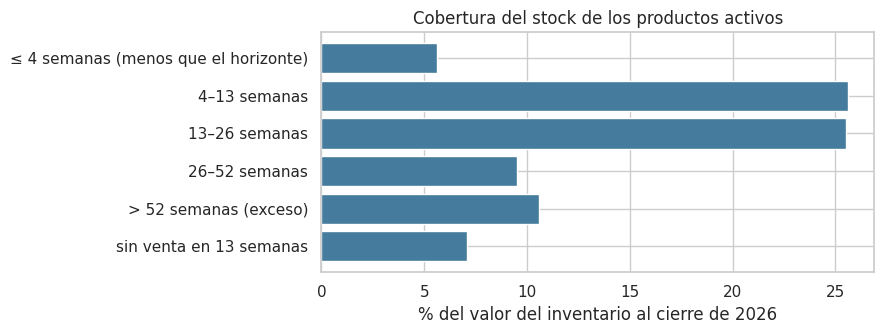

In [234]:
# 12.3 — Rotación (último año) y cobertura al cierre de 2026 — usa serie_d3, m5, prod (7.5), tot_v (7.5)
sa = qq[qq["semana"].between(ini_año, fin_completa)].assign(abc=lambda t: t["producto"].map(prod["abc"]))
stock_prom = sa.groupby(["abc", "semana"])["stock_cierre"].sum().groupby("abc").mean()
t3 = pd.DataFrame({"unidades vendidas": prod.groupby("abc")["u_ultimo_año"].sum(), "stock promedio": stock_prom})
t3["rotación (veces/año)"] = (t3["unidades vendidas"] / t3["stock promedio"]).round(1)
t3["días de inventario"] = (364 / t3["rotación (veces/año)"]).round(0)
print("1) Rotación del inventario por clase ABC (último año):")
print(t3.reindex(ORD_ABC)[["rotación (veces/año)", "días de inventario"]].to_string())

vs13 = m5[m5["semana"] > fin_completa - pd.Timedelta(weeks=13)].groupby("producto")["u_venta"].mean()
act = prod[prod["destino"].ne("sin pronóstico (inactivo)") & prod["stock_26"].gt(TOL)].copy()
act["cobertura"] = act["stock_26"] / vs13.reindex(act.index).where(lambda s: s > 0)
etiquetas = ["≤ 4 semanas (menos que el horizonte)", "4–13 semanas", "13–26 semanas", "26–52 semanas", "> 52 semanas (exceso)"]
tramo = (pd.cut(act["cobertura"], [0, 4, 13, 26, 52, np.inf], labels=etiquetas)
           .cat.add_categories("sin venta en 13 semanas").fillna("sin venta en 13 semanas"))
t4 = pd.DataFrame({"productos": act.groupby(tramo, observed=False).size(),
                   "% del valor del inventario": (100 * act.groupby(tramo, observed=False)["valor_26"].sum() / tot_v).round(1)})
print(f"\n2) Cobertura al cierre de 2026 de los {len(act)} productos que se pronostican y tienen stock:")
print(t4.to_string())

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(t4.index.astype(str), t4["% del valor del inventario"], color="#457b9d")
ax.invert_yaxis()
ax.set(xlabel="% del valor del inventario al cierre de 2026", title="Cobertura del stock de los productos activos")
plt.tight_layout()
plt.show()

**Lectura 12.3 — Rotación y cobertura:** la clase A rota 6,5 veces al año (56 días de inventario), la B 5,0
(73 días) y la C 2,2 (165 días). La rotación usa el stock de las bodegas de stock y la venta de todas las
bodegas, por lo que puede estar algo sobreestimada. En los 724 productos que se pronostican y tienen stock,
el 5,6 % del valor del inventario alcanza para menos de 4 semanas (menos que el ciclo de reposición), el
51,1 % para 4 a 26 semanas, el 10,6 % para más de un año y el 7,1 % está en productos sin venta en las
últimas 13 semanas (incluye productos de temporada fuera de su época). Junto con el inventario
inmovilizado (16,0 %), cerca de un tercio del valor del inventario tardaría más de un año en venderse o no
se está moviendo. (entre un 5 % y un 10 %; la clase A estaría entre 5,9 y 6,2 veces al año), sin cambiar el orden entre clases.

#### 12.4 — Dónde está el capital del inventario
Reparto del valor del inventario al cierre de 2026 según el destino del producto, y concentración del
inventario inmovilizado (7.5 C) por familia (grupo2).

In [235]:
# 12.4 — Composición del valor del inventario e inmovilizado por grupo2 — usa prod, nunca, inm_f, tot_v (7.5), g2 (7.4)
comp = prod.groupby("destino")["valor_26"].sum()
comp.loc["nunca vendieron"] = nunca["valor"].sum()
comp.loc["otros"] = tot_v - comp.sum()
print("1) % del valor del inventario al cierre de 2026, por destino del producto:")
print((100 * comp / tot_v).round(1).sort_values(ascending=False).to_string())

inm_val = pd.concat([prod.loc[inm_f, "valor_26"], nunca["valor"]])
fam = g2.reindex(inm_val.index).fillna("sin grupo")
t5 = pd.DataFrame({"productos": inm_val.groupby(fam).size(),
                   "% del inmovilizado": (100 * inm_val.groupby(fam).sum() / inm_val.sum()).round(1),
                   "% del valor del inventario": (100 * inm_val.groupby(fam).sum() / tot_v).round(1)})
t5 = t5.sort_values("% del inmovilizado", ascending=False)
print(f"\n2) Inventario inmovilizado por familia (grupo2): {len(inm_val)} productos, "
      f"{100 * inm_val.sum() / tot_v:.1f} % del valor del inventario")
print(t5.head(10).to_string())
print(f"   Las 3 familias con más inmovilizado concentran el {t5['% del inmovilizado'].head(3).sum():.1f} % de él")

1) % del valor del inventario al cierre de 2026, por destino del producto:
destino
pronóstico individual                                      81.6
sin pronóstico (inactivo)                                  12.3
nunca vendieron                                             3.7
historia corta (DeepAR, aprende de productos parecidos)     2.3
contra pedido / agregado por grupo2                         0.1
otros                                                       0.0

2) Inventario inmovilizado por familia (grupo2): 418 productos, 16.0 % del valor del inventario
                           productos  % del inmovilizado  % del valor del inventario
grupo2                                                                              
agro                              69                25.1                         4.0
construccion                      29                23.7                         3.8
motores                           26                11.2                         1.8
motobombas 

**Lectura 12.4 — Dónde está el capital:** el 81,6 % del valor del inventario está en productos con
pronóstico individual, el 12,3 % en inactivos, el 3,7 % en productos que nunca vendieron y el 2,3 % en
productos de historia corta. El inventario inmovilizado (418 productos, 16,0 % del valor) está concentrado:
tres familias de grupo2 suman el 60 % de él, lo que permite atacarlo con pocas acciones.

### 13. Cierre del EDA y entrega a T-17

#### 13.1 —


#### 13.2 — Archivos para el modelado
Se guardan en Drive: (1) `serie_modelo`, en formato Nixtla (unique_id, ds, y, available_mask, dias_habiles,
atipico); (2) `prod`, con la clasificación de cada producto; (3) el calendario de días hábiles de las semanas
futuras, que DeepAR necesita como variable conocida; y (4) los parámetros acordados. Antes de guardar se
valida que los archivos cumplan lo que exige NeuralForecast.

In [236]:
# 13.2 — Exportación para T-17 (con validaciones) — usa serie_modelo, prod, dias_habiles, fin_completa


# 1) Serie para el modelo
sm = serie_modelo[["unique_id", "ds", "y", "available_mask", "dias_habiles", "atipico"]].copy()
assert sm["y"].notna().all() and sm["y"].ge(0).all() and (sm["y"] % 1).eq(0).all(), "y debe ser entero ≥ 0 sin NaN"
assert sm["available_mask"].isin([0, 1]).all(), "available_mask debe ser 0 o 1"
assert sm["dias_habiles"].notna().all(), "Faltan días hábiles"
assert sm["ds"].dt.dayofweek.eq(0).all(), "ds debe ser lunes (W-MON)"
assert not sm.duplicated(["unique_id", "ds"]).any(), "Hay producto-semana repetidos"
pasos = sm.sort_values(["unique_id", "ds"]).groupby("unique_id")["ds"].diff().dropna()
assert pasos.eq(pd.Timedelta(weeks=1)).all(), "Hay semanas faltantes dentro de alguna serie"
assert set(sm["unique_id"]) <= set(prod.index), "Hay series sin fila en prod"
print(f"1) serie_modelo: {len(sm):,} filas | {sm['unique_id'].nunique()} productos | "
      f"{sm['ds'].min():%d-%b-%Y} a {sm['ds'].max():%d-%b-%Y} | enmascaradas {(sm['available_mask'] == 0).mean():.1%} ✔")

# 2) Tabla de productos
prod_out = prod.assign(grupo2=g2.reindex(prod.index))[[
    "grupo2", "destino", "patron", "cuadrante_mes", "abc", "manejo", "clase_hist", "actividad", "temporada",
    "revisar_empresa", "posible_quiebre_final", "prim", "ult", "sem_hist", "n_obs",
    "unidades", "u_ultimo_año", "stock_26", "valor_26"]]
print(f"2) prod: {len(prod_out)} productos | destinos: {prod_out['destino'].value_counts().to_dict()}")

# 3) Calendario futuro: días hábiles hasta fin de 2027 (variable conocida para DeepAR)
futuro = pd.date_range(fin_completa + pd.Timedelta(weeks=1), "2027-12-27", freq="W-MON")
cal_fut = pd.DataFrame({"ds": futuro, "dias_habiles": [dias_habiles(w) for w in futuro]})
print(f"3) Calendario futuro: {len(cal_fut)} semanas | semanas con menos de 5,6 días: {cal_fut['dias_habiles'].lt(5.6).sum()}")

# 4) Parámetros acordados
params = {"freq": "W-MON", "h": H_SEMANAS, "fin_datos": f"{fin_completa:%Y-%m-%d}",
          "bloques_evaluacion": 13, "bloques_seleccion": "1-7", "bloques_reporte": "8-13",
          "ventana_cuadrante_meses": 24, "verosimilitud": "NegativeBinomial",
          "peso_sabado": PESO_SABADO, "supuestos": "S1-S37", "fecha_exportacion": f"{pd.Timestamp.today():%Y-%m-%d}"}

sm.to_parquet(f"{SALIDA}/serie_modelo.parquet", index=False)
prod_out.to_parquet(f"{SALIDA}/prod.parquet")
cal_fut.to_parquet(f"{SALIDA}/calendario_futuro.parquet", index=False)
with open(f"{SALIDA}/parametros.json", "w") as f:
    json.dump(params, f, ensure_ascii=False, indent=2)

# 5) Prueba de lectura: lo guardado es igual a lo calculado
assert pd.read_parquet(f"{SALIDA}/serie_modelo.parquet").shape == sm.shape, "La serie guardada no coincide"
print(f"4) Archivos guardados en {SALIDA}: {sorted(os.listdir(SALIDA))} ✔")

1) serie_modelo: 570,838 filas | 4761 productos | 09-Jan-2023 a 21-Sep-2026 | enmascaradas 4.5% ✔
2) prod: 4761 productos | destinos: {'sin pronóstico (inactivo)': 3022, 'pronóstico individual': 1329, 'historia corta (DeepAR, aprende de productos parecidos)': 397, 'contra pedido / agregado por grupo2': 13}
3) Calendario futuro: 66 semanas | semanas con menos de 5,6 días: 24
4) Archivos guardados en /content/drive/MyDrive/2026_II/PF/salidas_EDA: ['calendario_futuro.parquet', 'parametros.json', 'piloto_22.parquet', 'prod.parquet', 'serie_modelo.parquet'] ✔


**Lectura 13.2 — Archivos para T-17:** en `salidas_EDA` quedaron cuatro archivos validados: la serie
semanal para el modelo (570.838 filas, 4.761 productos, del 9-ene-2023 al 21-sep-2026, 4,5 % de semanas
enmascaradas), la tabla de productos con su clasificación y banderas, el calendario de días hábiles hasta
fines de 2027 (66 semanas, 24 con menos días por festivos o cierre) y los parámetros acordados (frecuencia
semanal, horizonte de 4 semanas, 13 bloques de evaluación, binomial negativa). Las validaciones confirman
que la serie cumple lo que exige NeuralForecast: semanas continuas, ventas enteras y máscara 0/1.

#### 13.3 — Selección del piloto (22 productos, S28)
Muestra estratificada con semilla fija (reproducible), sin repetir productos entre estratos. Los nuevos
simulados son productos maduros: en T-17 se les recortará la historia a 8 semanas.

In [237]:
# 13.3 — Piloto estratificado de 22 productos — usa prod (7.5–12), i_mes (7.4), eps (7.3)
SEMILLA = 42
ind = prod["destino"].eq("pronóstico individual")
cv2 = i_mes["CV2"].reindex(prod.index)
max_q = eps[eps["tipo"].eq("quiebre corto")].groupby("producto")["largo"].max().reindex(prod.index)

estratos = [
    ("Suave / alta rotación",       4, ind & prod["cuadrante_mes"].eq("suave") & prod["abc"].eq("A")),
    ("Estacional",                  1, prod["temporada"]),
    ("Intermitente de tamaño fijo", 1, ind & prod["cuadrante_mes"].eq("intermitente") & cv2.lt(0.05) & prod["abc"].isin(["A", "B"])),
    ("Quiebres severos",            4, ind & prod["manejo"].eq("con_stock") & max_q.ge(6)),
    ("Errático",                    2, ind & prod["cuadrante_mes"].eq("errática")),
    ("Irregular",                   2, ind & prod["cuadrante_mes"].eq("irregular")),
    ("Nuevos reales",               4, prod["clase_hist"].eq("nuevo") & prod["n_obs"].ge(12)),
    ("Nuevos simulados",            4, ind & prod["clase_hist"].eq("madura") & prod["cuadrante_mes"].isin(["suave", "errática"])),
]
elegidos, resumen = [], []
for nombre, n, mask in estratos:
    cand = prod.index[mask.fillna(False) & ~prod.index.isin(elegidos)]
    sel = pd.Series(cand).sample(min(n, len(cand)), random_state=SEMILLA).tolist()
    elegidos += sel
    resumen.append({"estrato": nombre, "candidatos": len(cand), "elegidos": len(sel)})
    if len(sel) < n:
        print(f"⚠ {nombre}: solo hay {len(cand)} candidatos")

piloto = (prod.loc[elegidos, ["destino", "cuadrante_mes", "abc", "manejo", "clase_hist"]]
            .assign(estrato=[e for e, n, _ in estratos for _ in range(0)] or None))
piloto["estrato"] = sum([[r["estrato"]] * r["elegidos"] for r in resumen], [])
print(pd.DataFrame(resumen).to_string(index=False))
print(f"\nTotal piloto: {len(piloto)} productos")
print(pd.crosstab(piloto["estrato"], piloto["abc"]).to_string())

piloto.to_parquet(f"{SALIDA}/piloto_22.parquet")
assert len(piloto) == 22 and piloto.index.is_unique, "El piloto no tiene 22 productos distintos"

                    estrato  candidatos  elegidos
      Suave / alta rotación         109         4
                 Estacional          70         1
Intermitente de tamaño fijo         111         1
           Quiebres severos         271         4
                   Errático          77         2
                  Irregular         278         2
              Nuevos reales          33         4
           Nuevos simulados         213         4

Total piloto: 22 productos
abc                          A  B  C
estrato                             
Errático                     1  0  1
Estacional                   0  0  1
Intermitente de tamaño fijo  0  1  0
Irregular                    0  0  2
Nuevos reales                1  0  3
Nuevos simulados             1  2  1
Quiebres severos             2  1  1
Suave / alta rotación        4  0  0


**Lectura 13.3 — Piloto:** se eligieron 22 productos con semilla fija (42), en ocho estratos: 4 suaves de
clase A, 1 estacional, 1 intermitente de tamaño fijo, 4 con quiebres de 6 o más semanas, 2 erráticos,
2 irregulares, 4 nuevos reales (con al menos 12 semanas observadas) y 4 maduros que se usarán como nuevos
simulados. La lista está en `piloto_22.parquet`.

#### 13.4 — Limitaciones
- **Pocos años:** con tres años completos, la estacionalidad mensual no se puede confirmar (S35).
- **Censura:** las semanas en quiebre se excluyen, pero la venta de las semanas que se agotaron a mitad de
  semana está subestimada (S25), y los agotamientos al final de la serie no se detectan (S37).
- **Valor a costo:** el kárdex no tiene precios de venta; el ABC y el inventario se valorizan a costo (S36).
- **Cambio de base en 2026:** las bodegas no se pueden unir entre archivos (S4); el stock se mide solo en
  las bodegas principales (S15).
- **Reporte final sin fin de año:** los bloques de evaluación 8–13 (abr–sep 2026) no incluyen diciembre.
- **Clasificaciones con umbrales:** bajo pedido (50 %), inactivo (26 semanas) y sin surtido (13 semanas)
  son decisiones razonadas, con su sensibilidad reportada, no reglas exactas.
El registro completo de supuestos (S1–S37) está en la sección de supuestos.

In [238]:
# 13.5 — Verificación final: las cifras de las conclusiones coinciden con lo calculado
chequeos = {
    "filas del kárdex":                    (len(df_limpio), 162329),
    "productos en la serie del modelo":    (serie_modelo["unique_id"].nunique(), 4761),
    "productos con pronóstico individual": (prod["destino"].eq("pronóstico individual").sum(), 1329),
    "productos de historia corta":         (prod["destino"].str.startswith("historia corta").sum(), 397),
    "productos contra pedido":             (prod["destino"].str.startswith("contra pedido").sum(), 13),
    "productos inactivos":                 (prod["destino"].str.startswith("sin pronóstico").sum(), 3022),
    "productos clase A":                   (prod["abc"].eq("A").sum(), 441),
    "productos para consultar a la empresa": (prod["revisar_empresa"].sum(), 44),
    "productos del piloto":                (len(piloto), 22),
}
for nombre, (obtenido, esperado) in chequeos.items():
    assert obtenido == esperado, f"{nombre}: {obtenido} ≠ {esperado}"
print("Todas las cifras de las conclusiones coinciden con los cálculos ✔")

Todas las cifras de las conclusiones coinciden con los cálculos ✔


#### Conclusión 12 — Indicadores para la empresa (E8)
- **Concentración del valor:** 441 productos (clase A) hacen el 80 % del costo de lo vendido. El 28,6 % del
  valor está en productos A de demanda intermitente o irregular: importantes y difíciles de pronosticar.
- **Quiebres en lo importante:** la clase A pasa el 6,3 % de sus semanas sin stock, el doble que la C
  (3,1 %); 72 productos A tuvieron 4 o más semanas en quiebre en el último año. Oportunidad: priorizar el
  stock de seguridad de la clase A.
- **Desbalance del inventario:** el 5,6 % del valor de los productos activos alcanza para menos de 4 semanas
  (riesgo de quiebre), mientras que el 10,6 % alcanza para más de un año y el 16,0 % está inmovilizado:
  cerca de un tercio del valor tardaría más de un año en venderse o no se está moviendo.
- **Capital concentrado:** tres familias concentran el 60 % del inventario inmovilizado; se puede atacar
  con pocas acciones (liquidar, devolver al proveedor, dejar de comprar).
- **Pendiente con la empresa:** 44 productos A sin venta, stock ni compras desde hace más de 26 semanas
  (5,8 % del costo de lo vendido); 5 de ellos se agotaron en su última venta y son posibles quiebres ocultos.